<a href="https://colab.research.google.com/github/amzad-786githumb/SPP_GAN_Research/blob/main/21_Publication_Tables_%26_Figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# NOTEBOOK 21 — PUBLICATION TABLES & FIGURES
# SECTION 1 — HEADER & SCOPE
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

import os
import gc
import json
import hashlib
import warnings
import shutil
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# PROJECT CONFIGURATION
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/SPP_GAN_Research"
)

NOTEBOOK_ID = 21
NOTEBOOK_NAME = "Publication Tables & Figures"

PREVIOUS_NOTEBOOK = (
    PROJECT_ROOT / "results/notebooks/notebook_20"
)

NOTEBOOK_ROOT = (
    PROJECT_ROOT / "results/notebooks/notebook_21"
)

RESULTS_DIR = NOTEBOOK_ROOT / "results"
TABLES_DIR = NOTEBOOK_ROOT / "tables"
FIGURES_DIR = NOTEBOOK_ROOT / "figures"
METADATA_DIR = NOTEBOOK_ROOT / "metadata"
VALIDATION_DIR = NOTEBOOK_ROOT / "validation"
MANIFESTS_DIR = NOTEBOOK_ROOT / "manifests"

for directory in [
    RESULTS_DIR,
    TABLES_DIR,
    FIGURES_DIR,
    METADATA_DIR,
    VALIDATION_DIR,
    MANIFESTS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

# ------------------------------------------------------------
# RESEARCH CONFIGURATION
# ------------------------------------------------------------

MASTER_SEED = 2025

REPETITION_SEEDS = [
    3026, 3027, 3028, 3029, 3030
]

DATASETS = [
    "adult_income",
    "bank_marketing",
    "diabetes_130us"
]

ABLATION_VARIANTS = [
    "gan_only",
    "statistical_guidance_gan",
    "gan_dp",
    "full_sppgan"
]

BASELINE_MODELS = [
    "Statistical Baseline",
    "TVAE",
    "CTGAN",
    "DP-CTGAN",
    "SPP-GAN"
]

EXPECTED_EXPERIMENTS = (
    len(DATASETS)
    * len(ABLATION_VARIANTS)
    * len(REPETITION_SEEDS)
)

# ------------------------------------------------------------
# PUBLICATION SETTINGS
# ------------------------------------------------------------

DPI = 600

FIGURE_FORMATS = [
    "png",
    "pdf",
    "svg"
]

TABLE_FORMATS = [
    "csv",
    "tex"
]

PUBLICATION_STYLE = {
    "font_family": "DejaVu Sans",
    "font_size": 10,
    "title_size": 13,
    "axis_label_size": 10,
    "tick_size": 9
}

plt.rcParams.update({
    "font.family": PUBLICATION_STYLE["font_family"],
    "font.size": PUBLICATION_STYLE["font_size"],
    "axes.titlesize": PUBLICATION_STYLE["title_size"],
    "axes.labelsize": PUBLICATION_STYLE["axis_label_size"],
    "xtick.labelsize": PUBLICATION_STYLE["tick_size"],
    "ytick.labelsize": PUBLICATION_STYLE["tick_size"],
    "figure.dpi": 120,
    "savefig.dpi": DPI,
    "axes.spines.top": False,
    "axes.spines.right": False
})

# ------------------------------------------------------------
# SHARED REGISTRIES
# ------------------------------------------------------------

publication_tables = {}
publication_figures = {}
publication_sources = {}
publication_validation = []

print("Notebook:", NOTEBOOK_NAME)
print("Project root:", PROJECT_ROOT)
print("Previous notebook:", PREVIOUS_NOTEBOOK)
print("Expected ablation experiments:", EXPECTED_EXPERIMENTS)
print("Datasets:", len(DATASETS))
print("Ablation variants:", len(ABLATION_VARIANTS))
print("Repetitions:", len(REPETITION_SEEDS))
print("Publication DPI:", DPI)

assert PROJECT_ROOT.is_dir(), "Project root not found."
assert PREVIOUS_NOTEBOOK.is_dir(), "Notebook 20 not found."

print("SECTION 1 STATUS: PASS")

Mounted at /content/drive
Notebook: Publication Tables & Figures
Project root: /content/drive/MyDrive/SPP_GAN_Research
Previous notebook: /content/drive/MyDrive/SPP_GAN_Research/results/notebooks/notebook_20
Expected ablation experiments: 60
Datasets: 3
Ablation variants: 4
Repetitions: 5
Publication DPI: 600
SECTION 1 STATUS: PASS


In [3]:
# ============================================================
# SECTION 2 — LOAD MASTER RESULTS
# ============================================================

MASTER_RESULTS_PATH = (
    PREVIOUS_NOTEBOOK
    / "results/notebook_20_master_results.csv"
)

SOURCE_INVENTORY_PATH = (
    PREVIOUS_NOTEBOOK
    / "tables/final_source_inventory.csv"
)

EVIDENCE_SUMMARY_PATH = (
    PREVIOUS_NOTEBOOK
    / "tables/overall_evidence_summary.csv"
)

# ------------------------------------------------------------
# SAFE CSV LOADER WITH EXPLICIT STATUS
# ------------------------------------------------------------

def safe_read_csv(path, artifact_name):

    path = Path(path)

    result = {
        "artifact": artifact_name,
        "path": str(path),
        "exists": path.is_file(),
        "loaded": False,
        "rows": 0,
        "columns": [],
        "status": None,
        "error": None
    }

    if not path.is_file():
        result["status"] = "MISSING"
        return pd.DataFrame(), result

    try:
        dataframe = pd.read_csv(
            path,
            low_memory=False
        )

        result["loaded"] = True
        result["rows"] = len(dataframe)
        result["columns"] = list(dataframe.columns)

        if dataframe.empty:
            result["status"] = "LOADED_EMPTY"
        else:
            result["status"] = "LOADED_WITH_DATA"

        return dataframe, result

    except Exception as exc:

        result["status"] = "READ_FAILED"
        result["error"] = str(exc)

        print(
            "READ ERROR:",
            artifact_name,
            str(exc)
        )

        return pd.DataFrame(), result


# ------------------------------------------------------------
# LOAD NOTEBOOK 20 MASTER ARTIFACTS
# ------------------------------------------------------------

master_results, master_load_status = safe_read_csv(
    MASTER_RESULTS_PATH,
    "master_results"
)

source_inventory, inventory_load_status = safe_read_csv(
    SOURCE_INVENTORY_PATH,
    "source_inventory"
)

evidence_summary, evidence_load_status = safe_read_csv(
    EVIDENCE_SUMMARY_PATH,
    "evidence_summary"
)

LOAD_STATUS_RECORDS = [
    master_load_status,
    inventory_load_status,
    evidence_load_status
]

load_status_df = pd.DataFrame(
    LOAD_STATUS_RECORDS
)

# ------------------------------------------------------------
# VALIDATE MASTER RESULT SCHEMA
# ------------------------------------------------------------

MASTER_REQUIRED_COLUMNS = [
    "dataset",
    "model",
    "repetition",
    "metric",
    "value"
]

master_schema_valid = all(
    column in master_results.columns
    for column in MASTER_REQUIRED_COLUMNS
)

master_empirical_rows = (
    len(master_results)
    if master_schema_valid
    else 0
)

# An empty master file is valid as a loaded artifact,
# but it does not establish empirical evidence.
master_empirical_evidence_available = (
    master_schema_valid
    and master_empirical_rows > 0
)

# ------------------------------------------------------------
# DISCOVER NOTEBOOK 20 TABLE ARTIFACTS
# ------------------------------------------------------------

NOTEBOOK20_TABLES_DIR = (
    PREVIOUS_NOTEBOOK / "tables"
)

notebook20_csv_paths = sorted(
    NOTEBOOK20_TABLES_DIR.glob("*.csv")
) if NOTEBOOK20_TABLES_DIR.is_dir() else []

notebook20_csv_inventory = pd.DataFrame([
    {
        "file_name": path.name,
        "file_path": str(path),
        "file_size_bytes": path.stat().st_size
    }
    for path in notebook20_csv_paths
])

# ------------------------------------------------------------
# PRESERVE LOADED SOURCES
# ------------------------------------------------------------

publication_sources["master_results"] = master_results
publication_sources["source_inventory"] = source_inventory
publication_sources["evidence_summary"] = evidence_summary
publication_sources["load_status"] = load_status_df
publication_sources["notebook20_csv_inventory"] = (
    notebook20_csv_inventory
)

# ------------------------------------------------------------
# SAVE SECTION OUTPUTS
# ------------------------------------------------------------

load_status_path = (
    METADATA_DIR / "section_02_load_status.csv"
)

csv_inventory_path = (
    METADATA_DIR / "section_02_notebook20_csv_inventory.csv"
)

load_status_df.to_csv(
    load_status_path,
    index=False
)

notebook20_csv_inventory.to_csv(
    csv_inventory_path,
    index=False
)

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

validation_checks = {
    "project_root_exists": PROJECT_ROOT.is_dir(),
    "notebook20_directory_exists": PREVIOUS_NOTEBOOK.is_dir(),
    "master_results_file_loaded": master_load_status["loaded"],
    "master_results_schema_valid": master_schema_valid,
    "source_inventory_loaded": inventory_load_status["loaded"],
    "evidence_summary_loaded": evidence_load_status["loaded"],
    "notebook20_tables_directory_exists": NOTEBOOK20_TABLES_DIR.is_dir(),
    "notebook20_csv_artifacts_discovered": len(notebook20_csv_paths) > 0,
    "load_status_saved": load_status_path.is_file(),
    "csv_inventory_saved": csv_inventory_path.is_file()
}

validation_df = pd.DataFrame([
    {
        "check": check,
        "passed": bool(status)
    }
    for check, status in validation_checks.items()
])

validation_path = (
    VALIDATION_DIR / "section_02_validation.csv"
)

validation_df.to_csv(
    validation_path,
    index=False
)

section_passed = bool(
    validation_df["passed"].all()
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print("Master measurement rows:", len(master_results))
print("Master schema valid:", master_schema_valid)
print(
    "Master empirical evidence available:",
    master_empirical_evidence_available
)

print("Source inventory rows:", len(source_inventory))
print("Evidence categories:", len(evidence_summary))
print("Notebook 20 CSV artifacts:", len(notebook20_csv_paths))

print("\nLOAD STATUS")
print(load_status_df.to_string(index=False))

print("\nVALIDATION")
print(validation_df.to_string(index=False))

print("\nValidation checks passed:",
      int(validation_df["passed"].sum()),
      "/",
      len(validation_df))

print(
    "SECTION 2 STATUS:",
    "PASS" if section_passed else "FAIL"
)

print(
    "EMPIRICAL EVIDENCE STATUS:",
    "AVAILABLE"
    if master_empirical_evidence_available
    else "MISSING — NOT INFERRED"
)

assert section_passed, (
    "Section 2 structural loading validation failed."
)

Master measurement rows: 0
Master schema valid: True
Master empirical evidence available: False
Source inventory rows: 50
Evidence categories: 8
Notebook 20 CSV artifacts: 33

LOAD STATUS
        artifact                                                                                                         path  exists  loaded  rows                                                                                                                                                                                                    columns           status error
  master_results /content/drive/MyDrive/SPP_GAN_Research/results/notebooks/notebook_20/results/notebook_20_master_results.csv    True    True     0                                                                                                                                                                [dataset, model, repetition, metric, value]     LOADED_EMPTY  None
source_inventory      /content/drive/MyDrive/SPP_GAN_Research/re

In [5]:
# ============================================================
# SECTION 3 — VALIDATE PUBLICATION INPUTS
# ============================================================

# ------------------------------------------------------------
# REQUIRED MASTER SCHEMA
# ------------------------------------------------------------

REQUIRED_MASTER_COLUMNS = [
    "dataset",
    "model",
    "repetition",
    "metric",
    "value"
]

missing_master_columns = [
    column
    for column in REQUIRED_MASTER_COLUMNS
    if column not in master_results.columns
]

master_schema_valid = (
    len(missing_master_columns) == 0
)

# ------------------------------------------------------------
# VALIDATE EMPIRICAL MEASUREMENTS
# ------------------------------------------------------------

valid_master_results = pd.DataFrame(
    columns=master_results.columns
)

invalid_master_rows = pd.DataFrame(
    columns=master_results.columns
)

if master_schema_valid:

    master_results = master_results.copy()

    master_results["value"] = pd.to_numeric(
        master_results["value"],
        errors="coerce"
    )

    finite_mask = np.isfinite(
        master_results["value"].to_numpy(dtype=float)
    )

    required_text_columns = [
        "dataset",
        "model",
        "metric"
    ]

    nonempty_text_mask = (
        master_results[required_text_columns]
        .fillna("")
        .astype(str)
        .apply(
            lambda column: column.str.strip().ne("")
        )
        .all(axis=1)
    )

    repetition_numeric = pd.to_numeric(
        master_results["repetition"],
        errors="coerce"
    )

    repetition_valid_mask = (
        repetition_numeric.notna()
        & (repetition_numeric >= 1)
    )

    valid_mask = (
        finite_mask
        & nonempty_text_mask.to_numpy()
        & repetition_valid_mask.to_numpy()
    )

    valid_master_results = (
        master_results.loc[valid_mask].copy()
    )

    invalid_master_rows = (
        master_results.loc[~valid_mask].copy()
    )

# ------------------------------------------------------------
# EMPIRICAL EVIDENCE STATUS
# ------------------------------------------------------------

master_empirical_evidence_available = (
    master_schema_valid
    and not valid_master_results.empty
)

if master_empirical_evidence_available:
    master_evidence_status = "AVAILABLE"
else:
    master_evidence_status = "MISSING"

# ------------------------------------------------------------
# STRUCTURAL INPUT VALIDATION
# Missing empirical measurements are reported separately.
# They do not invalidate correctly loaded empty input files.
# ------------------------------------------------------------

publication_validation = [
    {
        "check": "Notebook 20 master file exists",
        "passed": MASTER_RESULTS_PATH.is_file()
    },
    {
        "check": "Notebook 20 source inventory exists",
        "passed": SOURCE_INVENTORY_PATH.is_file()
    },
    {
        "check": "Notebook 20 evidence summary exists",
        "passed": EVIDENCE_SUMMARY_PATH.is_file()
    },
    {
        "check": "Master schema valid",
        "passed": master_schema_valid
    },
    {
        "check": "Master measurement values validated",
        "passed": (
            master_schema_valid
            and len(valid_master_results)
            + len(invalid_master_rows)
            == len(master_results)
        )
    }
]

input_validation_df = pd.DataFrame(
    publication_validation
)

# ------------------------------------------------------------
# EVIDENCE AVAILABILITY RECORD
# ------------------------------------------------------------

evidence_availability_df = pd.DataFrame([
    {
        "evidence_source": "Notebook 20 master results",
        "total_rows": len(master_results),
        "valid_measurement_rows": len(valid_master_results),
        "invalid_rows": len(invalid_master_rows),
        "schema_valid": master_schema_valid,
        "empirical_evidence_available": (
            master_empirical_evidence_available
        ),
        "evidence_status": master_evidence_status,
        "interpretation": (
            "Empirical measurements are present."
            if master_empirical_evidence_available
            else
            "No valid empirical measurements are available. "
            "Publication results must not be inferred."
        )
    }
])

# ------------------------------------------------------------
# SAVE VALIDATION ARTIFACTS
# ------------------------------------------------------------

input_validation_path = (
    VALIDATION_DIR / "section_03_input_validation.csv"
)

evidence_availability_path = (
    METADATA_DIR / "section_03_evidence_availability.csv"
)

invalid_rows_path = (
    TABLES_DIR / "section_03_invalid_master_rows.csv"
)

input_validation_df.to_csv(
    input_validation_path,
    index=False
)

evidence_availability_df.to_csv(
    evidence_availability_path,
    index=False
)

invalid_master_rows.to_csv(
    invalid_rows_path,
    index=False
)

# Preserve validated data for downstream sections.
publication_sources["valid_master_results"] = (
    valid_master_results
)

publication_sources["invalid_master_rows"] = (
    invalid_master_rows
)

publication_sources["input_validation"] = (
    input_validation_df
)

publication_sources["evidence_availability"] = (
    evidence_availability_df
)

# ------------------------------------------------------------
# VALIDATION SUMMARY
# ------------------------------------------------------------

structural_validation_passed = bool(
    input_validation_df["passed"].all()
)

print(input_validation_df.to_string(index=False))

print("\nMissing master columns:", missing_master_columns)
print("Total master rows:", len(master_results))
print("Valid master rows:", len(valid_master_results))
print("Invalid master rows:", len(invalid_master_rows))
print("Empirical evidence:", master_evidence_status)

print(
    "Structural validation:",
    "PASS" if structural_validation_passed else "FAIL"
)

print(
    "SECTION 3 STATUS:",
    "PASS" if structural_validation_passed else "FAIL"
)

assert structural_validation_passed, (
    "Section 3 structural input validation failed."
)

                              check  passed
     Notebook 20 master file exists    True
Notebook 20 source inventory exists    True
Notebook 20 evidence summary exists    True
                Master schema valid    True
Master measurement values validated    True

Missing master columns: []
Total master rows: 0
Valid master rows: 0
Invalid master rows: 0
Empirical evidence: MISSING
Structural validation: PASS
SECTION 3 STATUS: PASS


In [6]:
# ============================================================
# SECTION 4 — DATASET CHARACTERISTICS TABLE
# ============================================================

dataset_characteristics = pd.DataFrame([
    {
        "dataset": "Adult Income",
        "dataset_id": "adult_income",
        "original_rows": 48842,
        "original_columns": 15,
        "target_variable": "income",
        "data_type": "Mixed tabular",
        "generative_identifier_policy": "Identifiers excluded where applicable"
    },
    {
        "dataset": "Bank Marketing",
        "dataset_id": "bank_marketing",
        "original_rows": 45211,
        "original_columns": 17,
        "target_variable": "y",
        "data_type": "Mixed tabular",
        "generative_identifier_policy": "Identifiers excluded where applicable"
    },
    {
        "dataset": "Diabetes 130-US",
        "dataset_id": "diabetes_130us",
        "original_rows": 101766,
        "original_columns": 50,
        "target_variable": "readmitted",
        "data_type": "Mixed tabular",
        "generative_identifier_policy": (
            "Patient identifiers excluded from generative features"
        )
    }
])

dataset_characteristics.to_csv(
    TABLES_DIR / "dataset_characteristics.csv",
    index=False
)

publication_tables["dataset_characteristics"] = (
    dataset_characteristics
)

print(dataset_characteristics.to_string(index=False))
print("SECTION 4 STATUS: PASS")

        dataset     dataset_id  original_rows  original_columns target_variable     data_type                          generative_identifier_policy
   Adult Income   adult_income          48842                15          income Mixed tabular                 Identifiers excluded where applicable
 Bank Marketing bank_marketing          45211                17               y Mixed tabular                 Identifiers excluded where applicable
Diabetes 130-US diabetes_130us         101766                50      readmitted Mixed tabular Patient identifiers excluded from generative features
SECTION 4 STATUS: PASS


In [8]:
# ============================================================
# SECTION 5 — EXPERIMENTAL CONFIGURATION TABLE
# ============================================================

# ------------------------------------------------------------
# EXPERIMENT DESIGN
# ------------------------------------------------------------

experimental_configuration = pd.DataFrame([
    ["Datasets", len(DATASETS), "Three benchmark datasets"],
    ["Ablation variants", len(ABLATION_VARIANTS), "Four registered variants"],
    ["Repetitions", len(REPETITION_SEEDS), "Five repetitions"],
    [
        "Expected ablation experiments",
        EXPECTED_EXPERIMENTS,
        "3 datasets x 4 variants x 5 repetitions"
    ],
    ["Master random seed", MASTER_SEED, "Reproducibility"],
    [
        "Repetition seeds",
        ", ".join(map(str, REPETITION_SEEDS)),
        "Reproducibility"
    ],
    ["Training split", "70%", "Training data"],
    ["Validation split", "15%", "Validation data"],
    ["Test split", "15%", "Held-out evaluation"]
], columns=["parameter", "value", "description"])

# ------------------------------------------------------------
# PRIVACY CONFIGURATION
# These are configured targets/parameters, not achieved DP.
# ------------------------------------------------------------

privacy_configuration = pd.DataFrame([
    [
        "DP target epsilon",
        5,
        "Target privacy budget; not achieved evidence"
    ],
    [
        "DP delta",
        "min(1e-5, 1/N_train)",
        "Dataset-dependent target/configuration"
    ],
    [
        "Gradient clipping norm",
        1.0,
        "DP-SGD configuration"
    ],
    [
        "Noise multiplier",
        "Not specified in this table",
        "Must be retrieved from the executed DP training configuration"
    ],
    [
        "Sampling method",
        "Poisson sampling",
        "DP-SGD configuration"
    ],
    [
        "Privacy accountant",
        "RDP accountant",
        "Accountant configuration; not proof of achieved privacy"
    ]
], columns=["parameter", "value", "description"])

# ------------------------------------------------------------
# TRAINING CONFIGURATION
# ------------------------------------------------------------

training_configuration = pd.DataFrame([
    ["Batch size", 128, "Specified training configuration"],
    ["Training epochs", 300, "Specified training configuration"]
], columns=["parameter", "value", "description"])

# ------------------------------------------------------------
# COMBINED PUBLICATION TABLE
# ------------------------------------------------------------

experimental_configuration["configuration_group"] = (
    "Experiment design"
)

privacy_configuration["configuration_group"] = (
    "Privacy configuration"
)

training_configuration["configuration_group"] = (
    "Training configuration"
)

experimental_configuration = pd.concat(
    [
        experimental_configuration,
        privacy_configuration,
        training_configuration
    ],
    ignore_index=True
)

experimental_configuration = experimental_configuration[
    [
        "configuration_group",
        "parameter",
        "value",
        "description"
    ]
]

# ------------------------------------------------------------
# DESIGN VALIDATION
# ------------------------------------------------------------

assert len(DATASETS) == 3
assert len(ABLATION_VARIANTS) == 4
assert len(REPETITION_SEEDS) == 5
assert EXPECTED_EXPERIMENTS == 60

split_total = 0.70 + 0.15 + 0.15
assert np.isclose(split_total, 1.0)

assert MASTER_SEED == 2025
assert len(set(REPETITION_SEEDS)) == len(REPETITION_SEEDS)

# ------------------------------------------------------------
# SAVE PUBLICATION ARTIFACT
# ------------------------------------------------------------

experimental_configuration_path = (
    TABLES_DIR / "experimental_configuration.csv"
)

experimental_configuration.to_csv(
    experimental_configuration_path,
    index=False
)

publication_tables["experimental_configuration"] = (
    experimental_configuration
)

# ------------------------------------------------------------
# VALIDATION RECORD
# ------------------------------------------------------------

section_05_checks = {
    "three_datasets_registered": len(DATASETS) == 3,
    "four_ablation_variants_registered": len(ABLATION_VARIANTS) == 4,
    "five_repetitions_registered": len(REPETITION_SEEDS) == 5,
    "sixty_experiments_expected": EXPECTED_EXPERIMENTS == 60,
    "split_proportions_sum_to_one": np.isclose(split_total, 1.0),
    "master_seed_valid": MASTER_SEED == 2025,
    "repetition_seeds_unique": (
        len(set(REPETITION_SEEDS)) == len(REPETITION_SEEDS)
    ),
    "publication_table_saved": experimental_configuration_path.is_file()
}

section_05_validation = pd.DataFrame([
    {"check": key, "passed": bool(value)}
    for key, value in section_05_checks.items()
])

section_05_validation.to_csv(
    VALIDATION_DIR / "section_05_validation.csv",
    index=False
)

print(experimental_configuration.to_string(index=False))
print("\nVALIDATION")
print(section_05_validation.to_string(index=False))

section_05_passed = bool(
    section_05_validation["passed"].all()
)

print(
    "\nSECTION 5 STATUS:",
    "PASS" if section_05_passed else "FAIL"
)

assert section_05_passed, (
    "Section 5 experimental configuration validation failed."
)

   configuration_group                     parameter                        value                                                   description
     Experiment design                      Datasets                            3                                      Three benchmark datasets
     Experiment design             Ablation variants                            4                                      Four registered variants
     Experiment design                   Repetitions                            5                                              Five repetitions
     Experiment design Expected ablation experiments                           60                       3 datasets x 4 variants x 5 repetitions
     Experiment design            Master random seed                         2025                                               Reproducibility
     Experiment design              Repetition seeds 3026, 3027, 3028, 3029, 3030                                               Reproduc

In [10]:
# ============================================================
# SECTION 6 — MODEL CONFIGURATION TABLE
# ============================================================

# ------------------------------------------------------------
# MODEL CONFIGURATION REGISTRY
# Distinguish model design/configuration from verified privacy.
# ------------------------------------------------------------

model_configuration = pd.DataFrame([
    {
        "model": "Statistical Baseline",
        "model_type": "Statistical",
        "role": "Baseline",
        "configuration": (
            "Statistical synthetic data generation"
        ),
        "privacy_mechanism": "No formal DP guarantee established",
        "privacy_evidence_status": "NOT_VERIFIED"
    },
    {
        "model": "TVAE",
        "model_type": "Deep generative",
        "role": "Baseline",
        "configuration": (
            "Tabular Variational Autoencoder"
        ),
        "privacy_mechanism": "No formal DP mechanism specified",
        "privacy_evidence_status": "NOT_CLAIMED"
    },
    {
        "model": "CTGAN",
        "model_type": "GAN",
        "role": "Baseline",
        "configuration": (
            "Conditional Tabular GAN"
        ),
        "privacy_mechanism": "No formal DP mechanism specified",
        "privacy_evidence_status": "NOT_CLAIMED"
    },
    {
        "model": "DP-CTGAN",
        "model_type": "Privacy-preserving GAN",
        "role": "Baseline",
        "configuration": (
            "Differentially private CTGAN baseline"
        ),
        "privacy_mechanism": (
            "Requires verification of the implemented "
            "DP mechanism and accountant outputs"
        ),
        "privacy_evidence_status": "REQUIRES_VERIFICATION"
    },
    {
        "model": "SPP-GAN",
        "model_type": "Statistical-guided GAN",
        "role": "Proposed model",
        "configuration": (
            "Statistical guidance, dependency guidance, "
            "distribution guidance, and privacy component"
        ),
        "privacy_mechanism": (
            "DP-SGD with RDP accounting specified by "
            "the research methodology"
        ),
        "privacy_evidence_status": (
            "END_TO_END_VERIFICATION_REQUIRED"
        )
    },
    {
        "model": "gan_only",
        "model_type": "Ablation",
        "role": "Ablation variant",
        "configuration": (
            "GAN-only variant without the proposed "
            "guidance components"
        ),
        "privacy_mechanism": (
            "No differential privacy guarantee implied"
        ),
        "privacy_evidence_status": "NOT_ESTABLISHED"
    },
    {
        "model": "statistical_guidance_gan",
        "model_type": "Ablation",
        "role": "Ablation variant",
        "configuration": (
            "GAN with statistical guidance"
        ),
        "privacy_mechanism": (
            "No differential privacy guarantee implied"
        ),
        "privacy_evidence_status": "NOT_ESTABLISHED"
    },
    {
        "model": "gan_dp",
        "model_type": "Ablation",
        "role": "Ablation variant",
        "configuration": (
            "GAN with differential privacy configuration"
        ),
        "privacy_mechanism": (
            "DP mechanism and achieved accountant outputs "
            "must be verified"
        ),
        "privacy_evidence_status": "REQUIRES_VERIFICATION"
    },
    {
        "model": "full_sppgan",
        "model_type": "Ablation",
        "role": "Full proposed framework",
        "configuration": (
            "Full SPP-GAN configuration with statistical, "
            "dependency, distribution, and privacy components"
        ),
        "privacy_mechanism": (
            "End-to-end privacy boundary and achieved "
            "RDP accountant evidence must be verified"
        ),
        "privacy_evidence_status": (
            "END_TO_END_VERIFICATION_REQUIRED"
        )
    }
])

# ------------------------------------------------------------
# MODEL REGISTRY VALIDATION
# ------------------------------------------------------------

EXPECTED_MODEL_NAMES = [
    "Statistical Baseline",
    "TVAE",
    "CTGAN",
    "DP-CTGAN",
    "SPP-GAN",
    *ABLATION_VARIANTS
]

MODEL_REQUIRED_COLUMNS = [
    "model",
    "model_type",
    "role",
    "configuration",
    "privacy_mechanism",
    "privacy_evidence_status"
]

missing_model_columns = [
    column
    for column in MODEL_REQUIRED_COLUMNS
    if column not in model_configuration.columns
]

registered_model_names = (
    model_configuration["model"].tolist()
)

model_names_unique = (
    model_configuration["model"].is_unique
)

expected_models_present = (
    set(registered_model_names)
    == set(EXPECTED_MODEL_NAMES)
)

model_descriptions_complete = (
    model_configuration[
        [
            "model_type",
            "role",
            "configuration",
            "privacy_mechanism",
            "privacy_evidence_status"
        ]
    ]
    .fillna("")
    .astype(str)
    .apply(
        lambda column: column.str.strip().ne("")
    )
    .all()
    .all()
)

# ------------------------------------------------------------
# SAVE PUBLICATION TABLE
# ------------------------------------------------------------

model_configuration_path = (
    TABLES_DIR / "model_configuration.csv"
)

model_configuration.to_csv(
    model_configuration_path,
    index=False
)

publication_tables["model_configuration"] = (
    model_configuration
)

# ------------------------------------------------------------
# SAVE VALIDATION RESULTS
# ------------------------------------------------------------

section_06_checks = {
    "required_columns_present": len(missing_model_columns) == 0,
    "all_expected_models_registered": expected_models_present,
    "model_names_unique": model_names_unique,
    "model_descriptions_complete": model_descriptions_complete,
    "privacy_evidence_status_recorded": (
        model_configuration["privacy_evidence_status"]
        .notna()
        .all()
    ),
    "publication_table_saved": model_configuration_path.is_file()
}

section_06_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_06_checks.items()
])

section_06_validation_path = (
    VALIDATION_DIR / "section_06_validation.csv"
)

section_06_validation.to_csv(
    section_06_validation_path,
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

section_06_passed = bool(
    section_06_validation["passed"].all()
)

print(model_configuration.to_string(index=False))

print("\nVALIDATION")
print(section_06_validation.to_string(index=False))

print(
    "\nRegistered models:",
    len(model_configuration)
)

print(
    "Unique model names:",
    model_configuration["model"].nunique()
)

print(
    "Missing required columns:",
    missing_model_columns
)

print(
    "SECTION 6 STATUS:",
    "PASS" if section_06_passed else "FAIL"
)

assert section_06_passed, (
    "Section 6 model configuration validation failed."
)

                   model             model_type                    role                                                                                 configuration                                                                 privacy_mechanism          privacy_evidence_status
    Statistical Baseline            Statistical                Baseline                                                         Statistical synthetic data generation                                                No formal DP guarantee established                     NOT_VERIFIED
                    TVAE        Deep generative                Baseline                                                               Tabular Variational Autoencoder                                                  No formal DP mechanism specified                      NOT_CLAIMED
                   CTGAN                    GAN                Baseline                                                                       Conditional Tab

In [11]:
# ============================================================
# SHARED HELPER — PUBLICATION TABLE EXTRACTION
# Used by Sections 7–16
# ============================================================

# ------------------------------------------------------------
# LOAD PUBLICATION SOURCE
# ------------------------------------------------------------

def load_publication_source(
    source_key,
    filename_candidates
):
    """
    Load the first existing Notebook 20 CSV artifact.

    Preserve empty-file schemas and record missing/read-failure
    status separately from empirical evidence availability.
    """

    source_status = {
        "source_key": source_key,
        "matched_file": None,
        "source_path": None,
        "file_exists": False,
        "loaded": False,
        "row_count": 0,
        "columns": [],
        "load_status": "MISSING",
        "error": None
    }

    for filename in filename_candidates:

        path = NOTEBOOK20_TABLES_DIR / filename

        if not path.is_file():
            continue

        frame, load_details = safe_read_csv(
            path,
            source_key
        )

        source_status.update({
            "matched_file": filename,
            "source_path": str(path),
            "file_exists": True,
            "loaded": bool(load_details["loaded"]),
            "row_count": len(frame),
            "columns": list(frame.columns),
            "load_status": load_details["status"],
            "error": load_details["error"]
        })

        publication_sources[source_key] = frame
        publication_sources[f"{source_key}_load_status"] = (
            source_status.copy()
        )

        return frame

    publication_sources[source_key] = pd.DataFrame()
    publication_sources[f"{source_key}_load_status"] = (
        source_status.copy()
    )

    return pd.DataFrame()


# ------------------------------------------------------------
# BUILD PUBLICATION TABLE
# ------------------------------------------------------------

def build_publication_table(
    table_name,
    filename_candidates,
    required_numeric_columns=None,
    expected_columns=None
):
    """
    Build a publication table while preserving source records.

    A record is classified as a valid numeric measurement only
    when every required numeric column exists and contains a
    finite numeric value.

    Structural records and missing evidence are not treated
    as empirical measurements.
    """

    if required_numeric_columns is None:
        required_numeric_columns = ["value"]

    if expected_columns is None:
        expected_columns = [
            "dataset",
            "model",
            "metric",
            "value"
        ]

    frame = load_publication_source(
        table_name,
        filename_candidates
    )

    # --------------------------------------------------------
    # SOURCE LOAD STATUS
    # --------------------------------------------------------

    source_status = publication_sources.get(
        f"{table_name}_load_status",
        {}
    )

    source_loaded = bool(
        source_status.get("loaded", False)
    )

    # --------------------------------------------------------
    # MISSING OR UNREADABLE SOURCE
    # --------------------------------------------------------

    if not source_loaded:

        result = pd.DataFrame(
            columns=list(dict.fromkeys(expected_columns))
        )

        result["evidence_status"] = pd.Series(
            dtype="object"
        )

        result["source_status"] = (
            source_status.get("load_status", "MISSING")
        )

        publication_tables[table_name] = result

        return result

    # --------------------------------------------------------
    # PRESERVE SOURCE SCHEMA AND RECORDS
    # --------------------------------------------------------

    result = frame.copy()

    # An existing CSV with headers but zero rows is a valid
    # loaded artifact, not evidence of empirical measurements.
    if result.empty:

        result["evidence_status"] = pd.Series(
            dtype="object"
        )

        result["source_status"] = "LOADED_EMPTY"

        publication_tables[table_name] = result

        return result

    # --------------------------------------------------------
    # REQUIRED NUMERIC COLUMN VALIDATION
    # --------------------------------------------------------

    required_numeric_columns = list(
        required_numeric_columns
    )

    missing_numeric_columns = [
        column
        for column in required_numeric_columns
        if column not in result.columns
    ]

    if missing_numeric_columns:

        result["evidence_status"] = (
            "REQUIRED_NUMERIC_COLUMNS_MISSING"
        )

        result["missing_numeric_columns"] = (
            ", ".join(missing_numeric_columns)
        )

        result["source_status"] = "SCHEMA_INCOMPLETE"

        publication_tables[table_name] = result

        return result

    # --------------------------------------------------------
    # VALIDATE ALL REQUIRED NUMERIC VALUES
    # --------------------------------------------------------

    if required_numeric_columns:

        valid_numeric_mask = pd.Series(
            True,
            index=result.index,
            dtype=bool
        )

        for column in required_numeric_columns:

            result[column] = pd.to_numeric(
                result[column],
                errors="coerce"
            )

            finite_mask = np.isfinite(
                result[column].to_numpy(dtype=float)
            )

            valid_numeric_mask &= pd.Series(
                finite_mask,
                index=result.index
            )

        result["evidence_status"] = np.where(
            valid_numeric_mask,
            "VALID_NUMERIC_MEASUREMENT",
            "NO_VALID_NUMERIC_MEASUREMENT"
        )

    else:

        result["evidence_status"] = (
            "STRUCTURAL_RECORD_ONLY"
        )

    result["source_status"] = "LOADED_WITH_DATA"

    # --------------------------------------------------------
    # PRESERVE PUBLICATION TABLE
    # --------------------------------------------------------

    publication_tables[table_name] = result

    return result


# ------------------------------------------------------------
# PRINT TABLE STATUS
# ------------------------------------------------------------

def print_table_status(name, frame):

    if "evidence_status" in frame.columns:

        status_counts = (
            frame["evidence_status"]
            .value_counts(dropna=False)
            .to_dict()
        )

        valid_count = int(
            (
                frame["evidence_status"]
                == "VALID_NUMERIC_MEASUREMENT"
            ).sum()
        )

    else:

        status_counts = {}
        valid_count = 0

    source_status = publication_sources.get(
        f"{name}_load_status",
        {}
    )

    print(
        name,
        "| Records:", len(frame),
        "| Valid measurements:", valid_count,
        "| Source status:",
        source_status.get("load_status", "UNKNOWN"),
        "| Evidence statuses:",
        status_counts
    )


# ------------------------------------------------------------
# VALIDATE SHARED HELPER
# ------------------------------------------------------------

section_shared_helper_checks = {
    "notebook20_tables_directory_exists": (
        NOTEBOOK20_TABLES_DIR.is_dir()
    ),
    "safe_csv_loader_available": callable(safe_read_csv),
    "source_loader_available": callable(load_publication_source),
    "publication_table_builder_available": callable(
        build_publication_table
    ),
    "table_status_reporter_available": callable(
        print_table_status
    )
}

shared_helper_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_shared_helper_checks.items()
])

shared_helper_validation.to_csv(
    VALIDATION_DIR / "shared_publication_helper_validation.csv",
    index=False
)

print(shared_helper_validation.to_string(index=False))

shared_helper_passed = bool(
    shared_helper_validation["passed"].all()
)

print(
    "SHARED HELPER STATUS:",
    "PASS" if shared_helper_passed else "FAIL"
)

assert shared_helper_passed, (
    "Shared publication helper validation failed."
)

                              check  passed
 notebook20_tables_directory_exists    True
          safe_csv_loader_available    True
            source_loader_available    True
publication_table_builder_available    True
    table_status_reporter_available    True
SHARED HELPER STATUS: PASS


In [13]:
# ============================================================
# SECTION 7 — STATISTICAL FIDELITY TABLES
# ============================================================

# ------------------------------------------------------------
# DISCOVER FIDELITY SOURCE FILES
# ------------------------------------------------------------

FIDELITY_FILENAME_CANDIDATES = [
    "fidelity_results.csv",
    "integrated_fidelity_results.csv",
    "fidelity_measurements.csv"
]

if NOTEBOOK20_TABLES_DIR.is_dir():

    discovered_fidelity_files = sorted(
        path.name
        for path in NOTEBOOK20_TABLES_DIR.glob("*.csv")
        if "fidel" in path.name.lower()
    )

else:

    discovered_fidelity_files = []

FIDELITY_FILENAME_CANDIDATES = list(
    dict.fromkeys(
        FIDELITY_FILENAME_CANDIDATES
        + discovered_fidelity_files
    )
)

# ------------------------------------------------------------
# LOAD AND BUILD FIDELITY TABLE
# ------------------------------------------------------------

fidelity_table = build_publication_table(
    "statistical_fidelity",
    FIDELITY_FILENAME_CANDIDATES,
    required_numeric_columns=["value"],
    expected_columns=[
        "dataset",
        "model",
        "variant",
        "repetition",
        "metric",
        "value"
    ]
)

# ------------------------------------------------------------
# VALIDATE SOURCE AND TABLE
# ------------------------------------------------------------

fidelity_source_status = publication_sources.get(
    "statistical_fidelity_load_status",
    {}
)

fidelity_source_loaded = bool(
    fidelity_source_status.get("loaded", False)
)

fidelity_schema_valid = (
    "evidence_status" in fidelity_table.columns
)

fidelity_valid_measurements = (
    int(
        (
            fidelity_table["evidence_status"]
            == "VALID_NUMERIC_MEASUREMENT"
        ).sum()
    )
    if fidelity_schema_valid
    else 0
)

fidelity_evidence_available = (
    fidelity_valid_measurements > 0
)

if not fidelity_source_loaded:
    fidelity_evidence_status = "SOURCE_NOT_FOUND_OR_NOT_LOADED"
elif fidelity_table.empty:
    fidelity_evidence_status = "SOURCE_LOADED_EMPTY"
elif fidelity_evidence_available:
    fidelity_evidence_status = "EMPIRICAL_MEASUREMENTS_AVAILABLE"
else:
    fidelity_evidence_status = "NO_VALID_EMPIRICAL_MEASUREMENTS"

# ------------------------------------------------------------
# SAVE FIDELITY TABLE AND STATUS
# ------------------------------------------------------------

fidelity_table_path = (
    TABLES_DIR / "statistical_fidelity_table.csv"
)

fidelity_status_path = (
    METADATA_DIR / "section_07_fidelity_status.json"
)

fidelity_table.to_csv(
    fidelity_table_path,
    index=False
)

fidelity_status = {
    "source_candidates": FIDELITY_FILENAME_CANDIDATES,
    "matched_source": fidelity_source_status.get("matched_file"),
    "source_path": fidelity_source_status.get("source_path"),
    "source_load_status": fidelity_source_status.get("load_status"),
    "source_loaded": fidelity_source_loaded,
    "source_rows": fidelity_source_status.get("row_count", 0),
    "publication_table_rows": len(fidelity_table),
    "valid_measurements": fidelity_valid_measurements,
    "evidence_status": fidelity_evidence_status,
    "publication_table_path": str(fidelity_table_path)
}

with open(
    fidelity_status_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        fidelity_status,
        file,
        indent=4
    )

publication_tables["statistical_fidelity"] = fidelity_table
publication_sources["statistical_fidelity_status"] = fidelity_status

# ------------------------------------------------------------
# SECTION VALIDATION
# ------------------------------------------------------------

section_07_checks = {
    "notebook20_tables_directory_exists": (
        NOTEBOOK20_TABLES_DIR.is_dir()
    ),
    "fidelity_table_created": fidelity_table_path.is_file(),
    "fidelity_status_saved": fidelity_status_path.is_file(),
    "evidence_status_recorded": (
        fidelity_evidence_status in [
            "SOURCE_NOT_FOUND_OR_NOT_LOADED",
            "SOURCE_LOADED_EMPTY",
            "EMPIRICAL_MEASUREMENTS_AVAILABLE",
            "NO_VALID_EMPIRICAL_MEASUREMENTS"
        ]
    ),
    "fidelity_table_has_evidence_status_column": (
        fidelity_schema_valid
    )
}

section_07_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_07_checks.items()
])

section_07_validation.to_csv(
    VALIDATION_DIR / "section_07_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print_table_status(
    "statistical_fidelity",
    fidelity_table
)

print("\nMatched source:", fidelity_status["matched_source"])
print("Source load status:", fidelity_status["source_load_status"])
print("Fidelity records:", len(fidelity_table))
print("Valid fidelity measurements:", fidelity_valid_measurements)
print("Empirical evidence status:", fidelity_evidence_status)

print("\nVALIDATION")
print(section_07_validation.to_string(index=False))

section_07_passed = bool(
    section_07_validation["passed"].all()
)

print(
    "\nSECTION 7 STATUS:",
    "PASS" if section_07_passed else "FAIL"
)

assert section_07_passed, (
    "Section 7 structural validation failed."
)

statistical_fidelity | Records: 0 | Valid measurements: 0 | Source status: LOADED_EMPTY | Evidence statuses: {}

Matched source: integrated_fidelity_results.csv
Source load status: LOADED_EMPTY
Fidelity records: 0
Valid fidelity measurements: 0
Empirical evidence status: SOURCE_LOADED_EMPTY

VALIDATION
                                    check  passed
       notebook20_tables_directory_exists    True
                   fidelity_table_created    True
                    fidelity_status_saved    True
                 evidence_status_recorded    True
fidelity_table_has_evidence_status_column    True

SECTION 7 STATUS: PASS


In [15]:
# ============================================================
# SECTION 8 — DEPENDENCY PRESERVATION TABLE
# ============================================================

# ------------------------------------------------------------
# DISCOVER DEPENDENCY SOURCE FILES
# ------------------------------------------------------------

DEPENDENCY_FILENAME_CANDIDATES = [
    "dependency_results.csv",
    "dependency_preservation_results.csv",
    "correlation_preservation_results.csv"
]

if NOTEBOOK20_TABLES_DIR.is_dir():

    discovered_dependency_files = sorted(
        path.name
        for path in NOTEBOOK20_TABLES_DIR.glob("*.csv")
        if any(
            term in path.name.lower()
            for term in [
                "depend",
                "correlation",
                "association"
            ]
        )
    )

else:

    discovered_dependency_files = []

DEPENDENCY_FILENAME_CANDIDATES = list(
    dict.fromkeys(
        DEPENDENCY_FILENAME_CANDIDATES
        + discovered_dependency_files
    )
)

# ------------------------------------------------------------
# LOAD AND BUILD DEPENDENCY TABLE
# ------------------------------------------------------------

dependency_table = build_publication_table(
    "dependency_preservation",
    DEPENDENCY_FILENAME_CANDIDATES,
    required_numeric_columns=["value"],
    expected_columns=[
        "dataset",
        "model",
        "variant",
        "repetition",
        "metric",
        "value"
    ]
)

# ------------------------------------------------------------
# VALIDATE SOURCE AND EVIDENCE
# ------------------------------------------------------------

dependency_source_status = publication_sources.get(
    "dependency_preservation_load_status",
    {}
)

dependency_source_loaded = bool(
    dependency_source_status.get("loaded", False)
)

dependency_valid_measurements = (
    int(
        (
            dependency_table["evidence_status"]
            == "VALID_NUMERIC_MEASUREMENT"
        ).sum()
    )
    if "evidence_status" in dependency_table.columns
    else 0
)

dependency_evidence_available = (
    dependency_valid_measurements > 0
)

if not dependency_source_loaded:
    dependency_evidence_status = (
        "SOURCE_NOT_FOUND_OR_NOT_LOADED"
    )
elif dependency_table.empty:
    dependency_evidence_status = "SOURCE_LOADED_EMPTY"
elif dependency_evidence_available:
    dependency_evidence_status = (
        "EMPIRICAL_MEASUREMENTS_AVAILABLE"
    )
else:
    dependency_evidence_status = (
        "NO_VALID_EMPIRICAL_MEASUREMENTS"
    )

# ------------------------------------------------------------
# SAVE PUBLICATION TABLE AND STATUS
# ------------------------------------------------------------

dependency_table_path = (
    TABLES_DIR / "dependency_preservation_table.csv"
)

dependency_status_path = (
    METADATA_DIR / "section_08_dependency_status.json"
)

dependency_table.to_csv(
    dependency_table_path,
    index=False
)

dependency_status = {
    "source_candidates": DEPENDENCY_FILENAME_CANDIDATES,
    "matched_source": dependency_source_status.get("matched_file"),
    "source_path": dependency_source_status.get("source_path"),
    "source_load_status": dependency_source_status.get("load_status"),
    "source_loaded": dependency_source_loaded,
    "source_rows": dependency_source_status.get("row_count", 0),
    "publication_table_rows": len(dependency_table),
    "valid_measurements": dependency_valid_measurements,
    "evidence_status": dependency_evidence_status,
    "publication_table_path": str(dependency_table_path)
}

with open(
    dependency_status_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        dependency_status,
        file,
        indent=4
    )

publication_tables["dependency_preservation"] = (
    dependency_table
)

publication_sources["dependency_preservation_status"] = (
    dependency_status
)

# ------------------------------------------------------------
# SECTION VALIDATION
# ------------------------------------------------------------

section_08_checks = {
    "notebook20_tables_directory_exists": (
        NOTEBOOK20_TABLES_DIR.is_dir()
    ),
    "dependency_table_created": dependency_table_path.is_file(),
    "dependency_status_saved": dependency_status_path.is_file(),
    "evidence_status_recorded": (
        dependency_evidence_status in [
            "SOURCE_NOT_FOUND_OR_NOT_LOADED",
            "SOURCE_LOADED_EMPTY",
            "EMPIRICAL_MEASUREMENTS_AVAILABLE",
            "NO_VALID_EMPIRICAL_MEASUREMENTS"
        ]
    ),
    "dependency_table_has_evidence_status_column": (
        "evidence_status" in dependency_table.columns
    )
}

section_08_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_08_checks.items()
])

section_08_validation.to_csv(
    VALIDATION_DIR / "section_08_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print_table_status(
    "dependency_preservation",
    dependency_table
)

print("\nDiscovered dependency files:",
      discovered_dependency_files)

print("Matched source:", dependency_status["matched_source"])
print("Source load status:", dependency_status["source_load_status"])
print("Dependency records:", len(dependency_table))
print("Valid dependency measurements:", dependency_valid_measurements)
print("Empirical evidence status:", dependency_evidence_status)

print("\nVALIDATION")
print(section_08_validation.to_string(index=False))

section_08_passed = bool(
    section_08_validation["passed"].all()
)

print(
    "\nSECTION 8 STATUS:",
    "PASS" if section_08_passed else "FAIL"
)

assert section_08_passed, (
    "Section 8 structural validation failed."
)

dependency_preservation | Records: 0 | Valid measurements: 0 | Source status: MISSING | Evidence statuses: {}

Discovered dependency files: []
Matched source: None
Source load status: MISSING
Dependency records: 0
Valid dependency measurements: 0
Empirical evidence status: SOURCE_NOT_FOUND_OR_NOT_LOADED

VALIDATION
                                      check  passed
         notebook20_tables_directory_exists    True
                   dependency_table_created    True
                    dependency_status_saved    True
                   evidence_status_recorded    True
dependency_table_has_evidence_status_column    True

SECTION 8 STATUS: PASS


In [17]:
# ============================================================
# SECTION 9 — ML UTILITY TABLE
# ============================================================

# ------------------------------------------------------------
# DISCOVER UTILITY SOURCE FILES
# ------------------------------------------------------------

UTILITY_FILENAME_CANDIDATES = [
    "utility_results.csv",
    "integrated_utility_results.csv",
    "downstream_utility_results.csv"
]

if NOTEBOOK20_TABLES_DIR.is_dir():

    discovered_utility_files = sorted(
        path.name
        for path in NOTEBOOK20_TABLES_DIR.glob("*.csv")
        if any(
            term in path.name.lower()
            for term in ["utility", "downstream", "tstr"]
        )
    )

else:

    discovered_utility_files = []

UTILITY_FILENAME_CANDIDATES = list(
    dict.fromkeys(
        UTILITY_FILENAME_CANDIDATES
        + discovered_utility_files
    )
)

# ------------------------------------------------------------
# LOAD AND BUILD UTILITY TABLE
# ------------------------------------------------------------

utility_table = build_publication_table(
    "ml_utility",
    UTILITY_FILENAME_CANDIDATES,
    required_numeric_columns=["value"],
    expected_columns=[
        "dataset",
        "model",
        "variant",
        "repetition",
        "metric",
        "value"
    ]
)

# ------------------------------------------------------------
# VALIDATE SOURCE AND EVIDENCE
# ------------------------------------------------------------

utility_source_status = publication_sources.get(
    "ml_utility_load_status",
    {}
)

utility_source_loaded = bool(
    utility_source_status.get("loaded", False)
)

utility_valid_measurements = (
    int(
        (
            utility_table["evidence_status"]
            == "VALID_NUMERIC_MEASUREMENT"
        ).sum()
    )
    if "evidence_status" in utility_table.columns
    else 0
)

utility_evidence_available = (
    utility_valid_measurements > 0
)

if not utility_source_loaded:
    utility_evidence_status = "SOURCE_NOT_FOUND_OR_NOT_LOADED"
elif utility_table.empty:
    utility_evidence_status = "SOURCE_LOADED_EMPTY"
elif utility_evidence_available:
    utility_evidence_status = "EMPIRICAL_MEASUREMENTS_AVAILABLE"
else:
    utility_evidence_status = "NO_VALID_EMPIRICAL_MEASUREMENTS"

# ------------------------------------------------------------
# SAVE PUBLICATION TABLE AND STATUS
# ------------------------------------------------------------

utility_table_path = (
    TABLES_DIR / "ml_utility_table.csv"
)

utility_status_path = (
    METADATA_DIR / "section_09_utility_status.json"
)

utility_table.to_csv(
    utility_table_path,
    index=False
)

utility_status = {
    "source_candidates": UTILITY_FILENAME_CANDIDATES,
    "discovered_source_files": discovered_utility_files,
    "matched_source": utility_source_status.get("matched_file"),
    "source_path": utility_source_status.get("source_path"),
    "source_load_status": utility_source_status.get("load_status"),
    "source_loaded": utility_source_loaded,
    "source_rows": utility_source_status.get("row_count", 0),
    "publication_table_rows": len(utility_table),
    "valid_measurements": utility_valid_measurements,
    "evidence_status": utility_evidence_status,
    "publication_table_path": str(utility_table_path)
}

with open(
    utility_status_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        utility_status,
        file,
        indent=4
    )

publication_tables["ml_utility"] = utility_table
publication_sources["ml_utility_status"] = utility_status

# ------------------------------------------------------------
# SECTION VALIDATION
# ------------------------------------------------------------

section_09_checks = {
    "notebook20_tables_directory_exists": (
        NOTEBOOK20_TABLES_DIR.is_dir()
    ),
    "utility_table_created": utility_table_path.is_file(),
    "utility_status_saved": utility_status_path.is_file(),
    "evidence_status_recorded": (
        utility_evidence_status in [
            "SOURCE_NOT_FOUND_OR_NOT_LOADED",
            "SOURCE_LOADED_EMPTY",
            "EMPIRICAL_MEASUREMENTS_AVAILABLE",
            "NO_VALID_EMPIRICAL_MEASUREMENTS"
        ]
    ),
    "utility_table_has_evidence_status_column": (
        "evidence_status" in utility_table.columns
    )
}

section_09_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_09_checks.items()
])

section_09_validation.to_csv(
    VALIDATION_DIR / "section_09_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print_table_status(
    "ml_utility",
    utility_table
)

print("\nDiscovered utility files:",
      discovered_utility_files)

print("Matched source:", utility_status["matched_source"])
print("Source load status:", utility_status["source_load_status"])
print("Utility records:", len(utility_table))
print("Valid utility measurements:", utility_valid_measurements)
print("Empirical evidence status:", utility_evidence_status)

print("\nVALIDATION")
print(section_09_validation.to_string(index=False))

section_09_passed = bool(
    section_09_validation["passed"].all()
)

print(
    "\nSECTION 9 STATUS:",
    "PASS" if section_09_passed else "FAIL"
)

assert section_09_passed, (
    "Section 9 structural validation failed."
)

ml_utility | Records: 0 | Valid measurements: 0 | Source status: LOADED_EMPTY | Evidence statuses: {}

Discovered utility files: ['integrated_utility_results.csv', 'privacy_utility_empirical_comparison.csv', 'privacy_utility_empirical_ranking.csv', 'privacy_utility_formal_dp_comparison.csv', 'privacy_utility_ranking.csv']
Matched source: integrated_utility_results.csv
Source load status: LOADED_EMPTY
Utility records: 0
Valid utility measurements: 0
Empirical evidence status: SOURCE_LOADED_EMPTY

VALIDATION
                                   check  passed
      notebook20_tables_directory_exists    True
                   utility_table_created    True
                    utility_status_saved    True
                evidence_status_recorded    True
utility_table_has_evidence_status_column    True

SECTION 9 STATUS: PASS


In [19]:
# ============================================================
# SECTION 10 — PRIVACY TABLE
# ============================================================

# ------------------------------------------------------------
# DISCOVER EMPIRICAL PRIVACY SOURCE FILES
# ------------------------------------------------------------

PRIVACY_FILENAME_CANDIDATES = [
    "privacy_results.csv",
    "empirical_privacy_results.csv",
    "integrated_privacy_results.csv"
]

if NOTEBOOK20_TABLES_DIR.is_dir():

    discovered_privacy_files = sorted(
        path.name
        for path in NOTEBOOK20_TABLES_DIR.glob("*.csv")
        if any(
            term in path.name.lower()
            for term in [
                "privacy",
                "reidentification",
                "membership",
                "nearest_neighbor",
                "disclosure"
            ]
        )
    )

else:

    discovered_privacy_files = []

PRIVACY_FILENAME_CANDIDATES = list(
    dict.fromkeys(
        PRIVACY_FILENAME_CANDIDATES
        + discovered_privacy_files
    )
)

# ------------------------------------------------------------
# LOAD AND BUILD EMPIRICAL PRIVACY TABLE
# ------------------------------------------------------------

privacy_table = build_publication_table(
    "empirical_privacy",
    PRIVACY_FILENAME_CANDIDATES,
    required_numeric_columns=["value"],
    expected_columns=[
        "dataset",
        "model",
        "variant",
        "repetition",
        "attack",
        "metric",
        "value"
    ]
)

# ------------------------------------------------------------
# VALIDATE SOURCE AND EVIDENCE
# ------------------------------------------------------------

privacy_source_status = publication_sources.get(
    "empirical_privacy_load_status",
    {}
)

privacy_source_loaded = bool(
    privacy_source_status.get("loaded", False)
)

privacy_valid_measurements = (
    int(
        (
            privacy_table["evidence_status"]
            == "VALID_NUMERIC_MEASUREMENT"
        ).sum()
    )
    if "evidence_status" in privacy_table.columns
    else 0
)

privacy_evidence_available = (
    privacy_valid_measurements > 0
)

if not privacy_source_loaded:
    privacy_evidence_status = "SOURCE_NOT_FOUND_OR_NOT_LOADED"
elif privacy_table.empty:
    privacy_evidence_status = "SOURCE_LOADED_EMPTY"
elif privacy_evidence_available:
    privacy_evidence_status = "EMPIRICAL_MEASUREMENTS_AVAILABLE"
else:
    privacy_evidence_status = "NO_VALID_EMPIRICAL_MEASUREMENTS"

# ------------------------------------------------------------
# SAVE PUBLICATION TABLE AND STATUS
# ------------------------------------------------------------

privacy_table_path = (
    TABLES_DIR / "empirical_privacy_table.csv"
)

privacy_status_path = (
    METADATA_DIR / "section_10_privacy_status.json"
)

privacy_table.to_csv(
    privacy_table_path,
    index=False
)

privacy_status = {
    "source_candidates": PRIVACY_FILENAME_CANDIDATES,
    "discovered_source_files": discovered_privacy_files,
    "matched_source": privacy_source_status.get("matched_file"),
    "source_path": privacy_source_status.get("source_path"),
    "source_load_status": privacy_source_status.get("load_status"),
    "source_loaded": privacy_source_loaded,
    "source_rows": privacy_source_status.get("row_count", 0),
    "publication_table_rows": len(privacy_table),
    "valid_measurements": privacy_valid_measurements,
    "evidence_status": privacy_evidence_status,
    "publication_table_path": str(privacy_table_path)
}

with open(
    privacy_status_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        privacy_status,
        file,
        indent=4
    )

publication_tables["empirical_privacy"] = privacy_table

publication_sources["empirical_privacy_status"] = (
    privacy_status
)

# ------------------------------------------------------------
# SECTION VALIDATION
# ------------------------------------------------------------

section_10_checks = {
    "notebook20_tables_directory_exists": (
        NOTEBOOK20_TABLES_DIR.is_dir()
    ),
    "privacy_table_created": privacy_table_path.is_file(),
    "privacy_status_saved": privacy_status_path.is_file(),
    "evidence_status_recorded": (
        privacy_evidence_status in [
            "SOURCE_NOT_FOUND_OR_NOT_LOADED",
            "SOURCE_LOADED_EMPTY",
            "EMPIRICAL_MEASUREMENTS_AVAILABLE",
            "NO_VALID_EMPIRICAL_MEASUREMENTS"
        ]
    ),
    "privacy_table_has_evidence_status_column": (
        "evidence_status" in privacy_table.columns
    )
}

section_10_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_10_checks.items()
])

section_10_validation.to_csv(
    VALIDATION_DIR / "section_10_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print_table_status(
    "empirical_privacy",
    privacy_table
)

print("\nDiscovered privacy files:",
      discovered_privacy_files)

print("Matched source:", privacy_status["matched_source"])
print("Source load status:", privacy_status["source_load_status"])
print("Privacy records:", len(privacy_table))
print("Valid privacy measurements:", privacy_valid_measurements)
print("Empirical evidence status:", privacy_evidence_status)

print("\nVALIDATION")
print(section_10_validation.to_string(index=False))

section_10_passed = bool(
    section_10_validation["passed"].all()
)

print(
    "\nSECTION 10 STATUS:",
    "PASS" if section_10_passed else "FAIL"
)

assert section_10_passed, (
    "Section 10 structural validation failed."
)


empirical_privacy | Records: 0 | Valid measurements: 0 | Source status: LOADED_EMPTY | Evidence statuses: {}

Discovered privacy files: ['integrated_empirical_privacy_results.csv', 'privacy_utility_empirical_comparison.csv', 'privacy_utility_empirical_ranking.csv', 'privacy_utility_formal_dp_comparison.csv', 'privacy_utility_ranking.csv']
Matched source: integrated_empirical_privacy_results.csv
Source load status: LOADED_EMPTY
Privacy records: 0
Valid privacy measurements: 0
Empirical evidence status: SOURCE_LOADED_EMPTY

VALIDATION
                                   check  passed
      notebook20_tables_directory_exists    True
                   privacy_table_created    True
                    privacy_status_saved    True
                evidence_status_recorded    True
privacy_table_has_evidence_status_column    True

SECTION 10 STATUS: PASS


In [21]:
# ============================================================
# SECTION 11 — DP GUARANTEE TABLE
# ============================================================

# ------------------------------------------------------------
# DISCOVER FORMAL DP EVIDENCE SOURCES
# ------------------------------------------------------------

DP_FILENAME_CANDIDATES = [
    "dp_evidence.csv",
    "dp_accountant_results.csv",
    "privacy_accountant_results.csv",
    "formal_dp_results.csv",
    "dp_validation_results.csv"
]

if NOTEBOOK20_TABLES_DIR.is_dir():

    discovered_dp_files = sorted(
        path.name
        for path in NOTEBOOK20_TABLES_DIR.glob("*.csv")
        if any(
            term in path.name.lower()
            for term in [
                "dp",
                "accountant",
                "privacy_guarantee",
                "privacy_account"
            ]
        )
    )

else:

    discovered_dp_files = []

DP_FILENAME_CANDIDATES = list(
    dict.fromkeys(
        DP_FILENAME_CANDIDATES
        + discovered_dp_files
    )
)

# ------------------------------------------------------------
# LOAD FORMAL DP SOURCE
# ------------------------------------------------------------

dp_table = build_publication_table(
    "formal_dp",
    DP_FILENAME_CANDIDATES,
    required_numeric_columns=[
        "achieved_epsilon",
        "achieved_delta"
    ],
    expected_columns=[
        "dataset",
        "model",
        "variant",
        "repetition",
        "achieved_epsilon",
        "achieved_delta",
        "accountant_type",
        "formal_dp_verified",
        "accountant_evidence_path",
        "privacy_boundary_verified"
    ]
)

# ------------------------------------------------------------
# STRICT FORMAL DP VERIFICATION
# ------------------------------------------------------------

dp_table = dp_table.copy()

if not dp_table.empty:

    # Preserve original verification values before normalization.
    if "formal_dp_verified" in dp_table.columns:

        formal_verified = (
            dp_table["formal_dp_verified"]
            .astype(str)
            .str.strip()
            .str.lower()
            .isin(["true", "1", "yes", "verified"])
        )

    else:

        formal_verified = pd.Series(
            False,
            index=dp_table.index
        )

    if "privacy_boundary_verified" in dp_table.columns:

        boundary_verified = (
            dp_table["privacy_boundary_verified"]
            .astype(str)
            .str.strip()
            .str.lower()
            .isin(["true", "1", "yes", "verified"])
        )

    else:

        boundary_verified = pd.Series(
            False,
            index=dp_table.index
        )

    if "achieved_epsilon" in dp_table.columns:
        epsilon = pd.to_numeric(
            dp_table["achieved_epsilon"],
            errors="coerce"
        )
    else:
        epsilon = pd.Series(
            np.nan,
            index=dp_table.index
        )

    if "achieved_delta" in dp_table.columns:
        delta = pd.to_numeric(
            dp_table["achieved_delta"],
            errors="coerce"
        )
    else:
        delta = pd.Series(
            np.nan,
            index=dp_table.index
        )

    accountant_present = (
        dp_table["accountant_type"]
        .fillna("")
        .astype(str)
        .str.strip()
        .ne("")
        if "accountant_type" in dp_table.columns
        else pd.Series(False, index=dp_table.index)
    )

    accountant_evidence_present = (
        dp_table["accountant_evidence_path"]
        .fillna("")
        .astype(str)
        .str.strip()
        .ne("")
        if "accountant_evidence_path" in dp_table.columns
        else pd.Series(False, index=dp_table.index)
    )

    valid_dp_values = (
        np.isfinite(epsilon)
        & np.isfinite(delta)
        & (epsilon > 0)
        & (delta > 0)
        & (delta < 1)
    )

    # A formal guarantee is verified only when achieved values,
    # accountant evidence, and the full privacy boundary are
    # explicitly documented.
    verified_guarantee = (
        formal_verified
        & boundary_verified
        & accountant_present
        & accountant_evidence_present
        & valid_dp_values
    )

    dp_table["achieved_epsilon"] = epsilon
    dp_table["achieved_delta"] = delta
    dp_table["formal_dp_verified"] = formal_verified
    dp_table["privacy_boundary_verified"] = boundary_verified
    dp_table["verified_guarantee"] = verified_guarantee

    dp_table["dp_evidence_status"] = np.where(
        verified_guarantee,
        "VERIFIED_FORMAL_DP",
        "NOT_VERIFIED_FORMAL_DP"
    )

else:

    dp_table["verified_guarantee"] = pd.Series(
        dtype=bool
    )

    dp_table["dp_evidence_status"] = pd.Series(
        dtype="object"
    )

# ------------------------------------------------------------
# SOURCE AND EVIDENCE STATUS
# ------------------------------------------------------------

dp_source_status = publication_sources.get(
    "formal_dp_load_status",
    {}
)

dp_source_loaded = bool(
    dp_source_status.get("loaded", False)
)

verified_dp_count = (
    int(dp_table["verified_guarantee"].sum())
    if "verified_guarantee" in dp_table.columns
    else 0
)

if not dp_source_loaded:
    dp_evidence_status = "SOURCE_NOT_FOUND_OR_NOT_LOADED"
elif dp_table.empty:
    dp_evidence_status = "SOURCE_LOADED_EMPTY"
elif verified_dp_count > 0:
    dp_evidence_status = "VERIFIED_FORMAL_DP_RECORDS_AVAILABLE"
else:
    dp_evidence_status = "NO_VERIFIED_FORMAL_DP_RECORDS"

# ------------------------------------------------------------
# SAVE DP TABLE AND STATUS
# ------------------------------------------------------------

dp_table_path = (
    TABLES_DIR / "formal_dp_guarantee_table.csv"
)

dp_status_path = (
    METADATA_DIR / "section_11_dp_status.json"
)

dp_table.to_csv(
    dp_table_path,
    index=False
)

dp_status = {
    "source_candidates": DP_FILENAME_CANDIDATES,
    "discovered_source_files": discovered_dp_files,
    "matched_source": dp_source_status.get("matched_file"),
    "source_path": dp_source_status.get("source_path"),
    "source_load_status": dp_source_status.get("load_status"),
    "source_loaded": dp_source_loaded,
    "source_rows": dp_source_status.get("row_count", 0),
    "publication_table_rows": len(dp_table),
    "verified_dp_guarantees": verified_dp_count,
    "evidence_status": dp_evidence_status,
    "verification_requirements": [
        "Valid achieved epsilon",
        "Valid achieved delta",
        "Explicit formal DP verification",
        "Verified end-to-end privacy boundary",
        "Accountant type",
        "Accountant evidence path"
    ],
    "publication_table_path": str(dp_table_path)
}

with open(
    dp_status_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        dp_status,
        file,
        indent=4
    )

publication_tables["formal_dp"] = dp_table
publication_sources["formal_dp_status"] = dp_status

# ------------------------------------------------------------
# SECTION VALIDATION
# ------------------------------------------------------------

section_11_checks = {
    "notebook20_tables_directory_exists": (
        NOTEBOOK20_TABLES_DIR.is_dir()
    ),
    "dp_table_created": dp_table_path.is_file(),
    "dp_status_saved": dp_status_path.is_file(),
    "verified_guarantee_column_present": (
        "verified_guarantee" in dp_table.columns
    ),
    "dp_evidence_status_recorded": (
        dp_evidence_status in [
            "SOURCE_NOT_FOUND_OR_NOT_LOADED",
            "SOURCE_LOADED_EMPTY",
            "VERIFIED_FORMAL_DP_RECORDS_AVAILABLE",
            "NO_VERIFIED_FORMAL_DP_RECORDS"
        ]
    ),
    "no_unverified_record_claimed_as_formal_dp": (
        (
            dp_table.loc[
                ~dp_table["verified_guarantee"],
                "dp_evidence_status"
            ]
            .eq("VERIFIED_FORMAL_DP")
            .sum()
            == 0
        )
        if not dp_table.empty
        else True
    )
}

section_11_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_11_checks.items()
])

section_11_validation.to_csv(
    VALIDATION_DIR / "section_11_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print_table_status(
    "formal_dp",
    dp_table
)

print("\nDiscovered DP files:", discovered_dp_files)
print("Matched source:", dp_status["matched_source"])
print("Source load status:", dp_status["source_load_status"])
print("DP records:", len(dp_table))
print("Verified DP guarantees:", verified_dp_count)
print("Formal DP evidence status:", dp_evidence_status)

print("\nVALIDATION")
print(section_11_validation.to_string(index=False))

section_11_passed = bool(
    section_11_validation["passed"].all()
)

print(
    "\nSECTION 11 STATUS:",
    "PASS" if section_11_passed else "FAIL"
)

assert section_11_passed, (
    "Section 11 structural validation failed."
)

formal_dp | Records: 0 | Valid measurements: 0 | Source status: LOADED_EMPTY | Evidence statuses: {}

Discovered DP files: ['integrated_formal_dp_results.csv', 'privacy_utility_formal_dp_comparison.csv']
Matched source: integrated_formal_dp_results.csv
Source load status: LOADED_EMPTY
DP records: 0
Verified DP guarantees: 0
Formal DP evidence status: SOURCE_LOADED_EMPTY

VALIDATION
                                    check  passed
       notebook20_tables_directory_exists    True
                         dp_table_created    True
                          dp_status_saved    True
        verified_guarantee_column_present    True
              dp_evidence_status_recorded    True
no_unverified_record_claimed_as_formal_dp    True

SECTION 11 STATUS: PASS


In [23]:
# ============================================================
# SECTION 12 — ABLATION TABLE
# ============================================================

# ------------------------------------------------------------
# DISCOVER ABLATION SOURCE FILES
# ------------------------------------------------------------

ABLATION_FILENAME_CANDIDATES = [
    "ablation_results.csv",
    "integrated_ablation_results.csv",
    "ablation_measurements.csv"
]

if NOTEBOOK20_TABLES_DIR.is_dir():

    discovered_ablation_files = sorted(
        path.name
        for path in NOTEBOOK20_TABLES_DIR.glob("*.csv")
        if "ablation" in path.name.lower()
    )

else:

    discovered_ablation_files = []

ABLATION_FILENAME_CANDIDATES = list(
    dict.fromkeys(
        ABLATION_FILENAME_CANDIDATES
        + discovered_ablation_files
    )
)

# ------------------------------------------------------------
# LOAD AND BUILD ABLATION TABLE
# ------------------------------------------------------------

ablation_table = build_publication_table(
    "ablation",
    ABLATION_FILENAME_CANDIDATES,
    required_numeric_columns=["value"],
    expected_columns=[
        "dataset",
        "variant",
        "repetition",
        "metric",
        "value"
    ]
)

# ------------------------------------------------------------
# VALIDATE VARIANT IDENTIFIERS
# ------------------------------------------------------------

if not ablation_table.empty:

    if "variant" in ablation_table.columns:

        ablation_table["variant"] = (
            ablation_table["variant"]
            .astype("string")
            .str.strip()
        )

        known_variant_mask = (
            ablation_table["variant"].isin(ABLATION_VARIANTS)
        )

        ablation_table["variant_registry_status"] = np.where(
            known_variant_mask,
            "REGISTERED_VARIANT",
            "UNKNOWN_OR_MISSING_VARIANT"
        )

        # Preserve all source records. Do not silently discard
        # unknown variants from the publication evidence table.
        ablation_table["eligible_for_registered_ablation"] = (
            known_variant_mask
        )

    else:

        ablation_table["variant_registry_status"] = (
            "VARIANT_COLUMN_MISSING"
        )

        ablation_table["eligible_for_registered_ablation"] = False

else:

    ablation_table["variant_registry_status"] = pd.Series(
        dtype="object"
    )

    ablation_table["eligible_for_registered_ablation"] = pd.Series(
        dtype="bool"
    )

# ------------------------------------------------------------
# EVIDENCE STATUS
# ------------------------------------------------------------

ablation_source_status = publication_sources.get(
    "ablation_load_status",
    {}
)

ablation_source_loaded = bool(
    ablation_source_status.get("loaded", False)
)

ablation_valid_measurements = (
    int(
        (
            ablation_table["evidence_status"]
            == "VALID_NUMERIC_MEASUREMENT"
        ).sum()
    )
    if "evidence_status" in ablation_table.columns
    else 0
)

registered_ablation_measurements = (
    int(
        (
            ablation_table["eligible_for_registered_ablation"]
            & (
                ablation_table["evidence_status"]
                == "VALID_NUMERIC_MEASUREMENT"
            )
        ).sum()
    )
    if not ablation_table.empty
    else 0
)

if not ablation_source_loaded:
    ablation_evidence_status = "SOURCE_NOT_FOUND_OR_NOT_LOADED"
elif ablation_table.empty:
    ablation_evidence_status = "SOURCE_LOADED_EMPTY"
elif registered_ablation_measurements > 0:
    ablation_evidence_status = (
        "REGISTERED_ABLATION_MEASUREMENTS_AVAILABLE"
    )
else:
    ablation_evidence_status = (
        "NO_VALID_REGISTERED_ABLATION_MEASUREMENTS"
    )

# ------------------------------------------------------------
# SAVE PUBLICATION TABLE AND STATUS
# ------------------------------------------------------------

ablation_table_path = (
    TABLES_DIR / "ablation_table.csv"
)

ablation_status_path = (
    METADATA_DIR / "section_12_ablation_status.json"
)

ablation_table.to_csv(
    ablation_table_path,
    index=False
)

ablation_status = {
    "source_candidates": ABLATION_FILENAME_CANDIDATES,
    "discovered_source_files": discovered_ablation_files,
    "matched_source": ablation_source_status.get("matched_file"),
    "source_path": ablation_source_status.get("source_path"),
    "source_load_status": ablation_source_status.get("load_status"),
    "source_loaded": ablation_source_loaded,
    "source_rows": ablation_source_status.get("row_count", 0),
    "publication_table_rows": len(ablation_table),
    "valid_measurements": ablation_valid_measurements,
    "registered_variant_measurements": registered_ablation_measurements,
    "expected_variants": ABLATION_VARIANTS,
    "expected_experiments": EXPECTED_EXPERIMENTS,
    "evidence_status": ablation_evidence_status,
    "publication_table_path": str(ablation_table_path)
}

with open(
    ablation_status_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        ablation_status,
        file,
        indent=4
    )

publication_tables["ablation"] = ablation_table
publication_sources["ablation_status"] = ablation_status

# ------------------------------------------------------------
# SECTION VALIDATION
# ------------------------------------------------------------

section_12_checks = {
    "notebook20_tables_directory_exists": (
        NOTEBOOK20_TABLES_DIR.is_dir()
    ),
    "ablation_table_created": ablation_table_path.is_file(),
    "ablation_status_saved": ablation_status_path.is_file(),
    "evidence_status_recorded": (
        ablation_evidence_status in [
            "SOURCE_NOT_FOUND_OR_NOT_LOADED",
            "SOURCE_LOADED_EMPTY",
            "REGISTERED_ABLATION_MEASUREMENTS_AVAILABLE",
            "NO_VALID_REGISTERED_ABLATION_MEASUREMENTS"
        ]
    ),
    "variant_registry_status_present": (
        "variant_registry_status" in ablation_table.columns
    ),
    "source_records_not_silently_discarded": (
        len(ablation_table)
        == ablation_source_status.get("row_count", 0)
        if ablation_source_loaded
        else True
    )
}

section_12_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_12_checks.items()
])

section_12_validation.to_csv(
    VALIDATION_DIR / "section_12_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print_table_status(
    "ablation",
    ablation_table
)

print("\nDiscovered ablation files:", discovered_ablation_files)
print("Matched source:", ablation_status["matched_source"])
print("Source load status:", ablation_status["source_load_status"])
print("Ablation records:", len(ablation_table))
print("Valid measurements:", ablation_valid_measurements)
print("Registered variant measurements:", registered_ablation_measurements)
print("Evidence status:", ablation_evidence_status)

print("\nVALIDATION")
print(section_12_validation.to_string(index=False))

section_12_passed = bool(
    section_12_validation["passed"].all()
)

print(
    "\nSECTION 12 STATUS:",
    "PASS" if section_12_passed else "FAIL"
)

assert section_12_passed, (
    "Section 12 ablation table validation failed."
)

ablation | Records: 0 | Valid measurements: 0 | Source status: LOADED_EMPTY | Evidence statuses: {}

Discovered ablation files: ['integrated_ablation_results.csv']
Matched source: integrated_ablation_results.csv
Source load status: LOADED_EMPTY
Ablation records: 0
Valid measurements: 0
Registered variant measurements: 0
Evidence status: SOURCE_LOADED_EMPTY

VALIDATION
                                check  passed
   notebook20_tables_directory_exists    True
               ablation_table_created    True
                ablation_status_saved    True
             evidence_status_recorded    True
      variant_registry_status_present    True
source_records_not_silently_discarded    True

SECTION 12 STATUS: PASS


In [25]:
# ============================================================
# SECTION 13 — TRADE-OFF TABLE
# ============================================================

# ------------------------------------------------------------
# DISCOVER TRADE-OFF SOURCE FILES
# ------------------------------------------------------------

TRADEOFF_FILENAME_CANDIDATES = [
    "tradeoff_results.csv",
    "tradeoff_measures.csv",
    "privacy_utility_tradeoff.csv"
]

if NOTEBOOK20_TABLES_DIR.is_dir():

    discovered_tradeoff_files = sorted(
        path.name
        for path in NOTEBOOK20_TABLES_DIR.glob("*.csv")
        if any(
            term in path.name.lower()
            for term in [
                "tradeoff",
                "privacy_utility",
                "pareto"
            ]
        )
    )

else:

    discovered_tradeoff_files = []

TRADEOFF_FILENAME_CANDIDATES = list(
    dict.fromkeys(
        TRADEOFF_FILENAME_CANDIDATES
        + discovered_tradeoff_files
    )
)

# ------------------------------------------------------------
# LOAD AND BUILD TRADE-OFF TABLE
# ------------------------------------------------------------

TRADEOFF_REQUIRED_NUMERIC_COLUMNS = [
    "privacy_score_mean",
    "fidelity_score_mean",
    "utility_score_mean",
    "tradeoff_score_mean"
]

tradeoff_table = build_publication_table(
    "tradeoff",
    TRADEOFF_FILENAME_CANDIDATES,
    required_numeric_columns=TRADEOFF_REQUIRED_NUMERIC_COLUMNS,
    expected_columns=[
        "dataset",
        "model",
        "variant",
        "privacy_score_mean",
        "fidelity_score_mean",
        "utility_score_mean",
        "tradeoff_score_mean"
    ]
)

# ------------------------------------------------------------
# VALIDATE TRADE-OFF MEASUREMENTS
# ------------------------------------------------------------

tradeoff_source_status = publication_sources.get(
    "tradeoff_load_status",
    {}
)

tradeoff_source_loaded = bool(
    tradeoff_source_status.get("loaded", False)
)

tradeoff_valid_measurements = (
    int(
        (
            tradeoff_table["evidence_status"]
            == "VALID_NUMERIC_MEASUREMENT"
        ).sum()
    )
    if "evidence_status" in tradeoff_table.columns
    else 0
)

tradeoff_required_columns_present = all(
    column in tradeoff_table.columns
    for column in TRADEOFF_REQUIRED_NUMERIC_COLUMNS
)

tradeoff_complete_scores_available = (
    tradeoff_required_columns_present
    and tradeoff_valid_measurements > 0
)

if not tradeoff_source_loaded:
    tradeoff_evidence_status = "SOURCE_NOT_FOUND_OR_NOT_LOADED"
elif tradeoff_table.empty:
    tradeoff_evidence_status = "SOURCE_LOADED_EMPTY"
elif not tradeoff_required_columns_present:
    tradeoff_evidence_status = "REQUIRED_SCORE_COLUMNS_MISSING"
elif tradeoff_complete_scores_available:
    tradeoff_evidence_status = "COMPLETE_TRADEOFF_MEASUREMENTS_AVAILABLE"
else:
    tradeoff_evidence_status = "NO_COMPLETE_TRADEOFF_MEASUREMENTS"

# ------------------------------------------------------------
# SAVE PUBLICATION TABLE AND STATUS
# ------------------------------------------------------------

tradeoff_table_path = (
    TABLES_DIR / "tradeoff_table.csv"
)

tradeoff_status_path = (
    METADATA_DIR / "section_13_tradeoff_status.json"
)

tradeoff_table.to_csv(
    tradeoff_table_path,
    index=False
)

tradeoff_status = {
    "source_candidates": TRADEOFF_FILENAME_CANDIDATES,
    "discovered_source_files": discovered_tradeoff_files,
    "matched_source": tradeoff_source_status.get("matched_file"),
    "source_path": tradeoff_source_status.get("source_path"),
    "source_load_status": tradeoff_source_status.get("load_status"),
    "source_loaded": tradeoff_source_loaded,
    "source_rows": tradeoff_source_status.get("row_count", 0),
    "publication_table_rows": len(tradeoff_table),
    "valid_complete_measurements": tradeoff_valid_measurements,
    "required_numeric_columns": TRADEOFF_REQUIRED_NUMERIC_COLUMNS,
    "required_score_columns_present": tradeoff_required_columns_present,
    "evidence_status": tradeoff_evidence_status,
    "interpretation": (
        "Complete privacy-fidelity-utility trade-off measurements "
        "are available."
        if tradeoff_complete_scores_available
        else
        "Complete trade-off measurements are unavailable. "
        "Do not infer or report a Pareto ranking."
    ),
    "publication_table_path": str(tradeoff_table_path)
}

with open(
    tradeoff_status_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        tradeoff_status,
        file,
        indent=4
    )

publication_tables["tradeoff"] = tradeoff_table
publication_sources["tradeoff_status"] = tradeoff_status

# ------------------------------------------------------------
# SECTION VALIDATION
# ------------------------------------------------------------

section_13_checks = {
    "notebook20_tables_directory_exists": (
        NOTEBOOK20_TABLES_DIR.is_dir()
    ),
    "tradeoff_table_created": tradeoff_table_path.is_file(),
    "tradeoff_status_saved": tradeoff_status_path.is_file(),
    "evidence_status_recorded": (
        tradeoff_evidence_status in [
            "SOURCE_NOT_FOUND_OR_NOT_LOADED",
            "SOURCE_LOADED_EMPTY",
            "REQUIRED_SCORE_COLUMNS_MISSING",
            "COMPLETE_TRADEOFF_MEASUREMENTS_AVAILABLE",
            "NO_COMPLETE_TRADEOFF_MEASUREMENTS"
        ]
    ),
    "required_numeric_columns_checked": (
        isinstance(
            TRADEOFF_REQUIRED_NUMERIC_COLUMNS,
            list
        )
    ),
    "no_incomplete_record_claimed_as_complete": (
        (
            tradeoff_table.loc[
                tradeoff_table["evidence_status"]
                != "VALID_NUMERIC_MEASUREMENT",
                "evidence_status"
            ]
            .ne("VALID_NUMERIC_MEASUREMENT")
            .all()
        )
        if not tradeoff_table.empty
        and "evidence_status" in tradeoff_table.columns
        else True
    )
}

section_13_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_13_checks.items()
])

section_13_validation.to_csv(
    VALIDATION_DIR / "section_13_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print_table_status(
    "tradeoff",
    tradeoff_table
)

print("\nDiscovered trade-off files:", discovered_tradeoff_files)
print("Matched source:", tradeoff_status["matched_source"])
print("Source load status:", tradeoff_status["source_load_status"])
print("Trade-off records:", len(tradeoff_table))
print("Complete trade-off measurements:", tradeoff_valid_measurements)
print("Required score columns present:", tradeoff_required_columns_present)
print("Evidence status:", tradeoff_evidence_status)

print("\nVALIDATION")
print(section_13_validation.to_string(index=False))

section_13_passed = bool(
    section_13_validation["passed"].all()
)

print(
    "\nSECTION 13 STATUS:",
    "PASS" if section_13_passed else "FAIL"
)

assert section_13_passed, (
    "Section 13 trade-off table validation failed."
)

tradeoff | Records: 22 | Valid measurements: 0 | Source status: LOADED_WITH_DATA | Evidence statuses: {'NO_VALID_NUMERIC_MEASUREMENT': 22}

Discovered trade-off files: ['integrated_tradeoff_results.csv', 'privacy_utility_empirical_comparison.csv', 'privacy_utility_empirical_ranking.csv', 'privacy_utility_formal_dp_comparison.csv', 'privacy_utility_ranking.csv']
Matched source: integrated_tradeoff_results.csv
Source load status: LOADED_WITH_DATA
Trade-off records: 22
Complete trade-off measurements: 0
Required score columns present: True
Evidence status: NO_COMPLETE_TRADEOFF_MEASUREMENTS

VALIDATION
                                   check  passed
      notebook20_tables_directory_exists    True
                  tradeoff_table_created    True
                   tradeoff_status_saved    True
                evidence_status_recorded    True
        required_numeric_columns_checked    True
no_incomplete_record_claimed_as_complete    True

SECTION 13 STATUS: PASS


In [29]:
# ============================================================
# SECTION 14 — SIGNIFICANCE TABLE
# ============================================================

# ------------------------------------------------------------
# DISCOVER AND LOAD STATISTICAL TEST SOURCE
# ------------------------------------------------------------

SIGNIFICANCE_FILENAME_CANDIDATES = [
    "significance_results.csv",
    "consolidated_statistical_results.csv",
    "paired_statistical_tests.csv"
]

if NOTEBOOK20_TABLES_DIR.is_dir():

    discovered_significance_files = sorted(
        path.name
        for path in NOTEBOOK20_TABLES_DIR.glob("*.csv")
        if any(
            term in path.name.lower()
            for term in [
                "significance",
                "statistical",
                "paired_test",
                "wilcoxon",
                "friedman",
                "hypothesis"
            ]
        )
    )

else:
    discovered_significance_files = []

SIGNIFICANCE_FILENAME_CANDIDATES = list(
    dict.fromkeys(
        SIGNIFICANCE_FILENAME_CANDIDATES
        + discovered_significance_files
    )
)

significance_source = load_publication_source(
    "significance",
    SIGNIFICANCE_FILENAME_CANDIDATES
)

significance_source_status = publication_sources.get(
    "significance_load_status",
    {}
)

significance_source_loaded = bool(
    significance_source_status.get("loaded", False)
)

# Preserve every source record.
significance_table = significance_source.copy()

# ------------------------------------------------------------
# NORMALIZE SOURCE COLUMN NAMES
# ------------------------------------------------------------

significance_table.columns = [
    str(column).strip().lower()
    for column in significance_table.columns
]

source_columns = list(significance_table.columns)

# ------------------------------------------------------------
# MAP ACTUAL NOTEBOOK 20 STATISTICAL FIELDS
# ------------------------------------------------------------

def first_available_column(dataframe, candidates):

    return next(
        (
            column
            for column in candidates
            if column in dataframe.columns
        ),
        None
    )


statistic_source_column = first_available_column(
    significance_table,
    ["test_statistic", "statistic", "test_stat", "stat_value"]
)

p_value_source_column = first_available_column(
    significance_table,
    ["p_value", "raw_p_value", "pvalue", "p"]
)

adjusted_p_source_column = first_available_column(
    significance_table,
    [
        "p_adjusted_holm",
        "adjusted_p_value",
        "friedman_adjusted_p",
        "corrected_p_value",
        "p_adjusted"
    ]
)

test_name_source_column = first_available_column(
    significance_table,
    ["test_name", "test", "test_method", "statistical_test"]
)

# ------------------------------------------------------------
# BUILD COMPARISON LABELS
# ------------------------------------------------------------

if not significance_table.empty:

    if "comparison" not in significance_table.columns:

        if {
            "variant_a",
            "variant_b"
        }.issubset(significance_table.columns):

            significance_table["comparison"] = (
                significance_table["variant_a"]
                .fillna("")
                .astype(str)
                + " vs "
                + significance_table["variant_b"]
                .fillna("")
                .astype(str)
            )

        else:

            significance_table["comparison"] = ""

    # Identify omnibus Friedman tests where no pairwise
    # comparison is applicable.
    if "test" in significance_table.columns:

        test_text = (
            significance_table["test"]
            .fillna("")
            .astype(str)
            .str.lower()
        )

    elif "test_method" in significance_table.columns:

        test_text = (
            significance_table["test_method"]
            .fillna("")
            .astype(str)
            .str.lower()
        )

    else:

        test_text = pd.Series(
            "",
            index=significance_table.index
        )

    is_friedman = test_text.str.contains(
        "friedman",
        regex=False
    )

    significance_table.loc[
        is_friedman
        & significance_table["comparison"].fillna("").eq(""),
        "comparison"
    ] = (
        "Friedman omnibus test"
    )

# ------------------------------------------------------------
# NORMALIZE TEST STATISTIC AND P-VALUES
# ------------------------------------------------------------

if not significance_table.empty:

    if statistic_source_column is not None:

        significance_table["test_statistic"] = pd.to_numeric(
            significance_table[statistic_source_column],
            errors="coerce"
        )

    else:

        significance_table["test_statistic"] = np.nan

    if p_value_source_column is not None:

        significance_table["p_value"] = pd.to_numeric(
            significance_table[p_value_source_column],
            errors="coerce"
        )

    else:

        significance_table["p_value"] = np.nan

    if adjusted_p_source_column is not None:

        significance_table["adjusted_p_value"] = pd.to_numeric(
            significance_table[adjusted_p_source_column],
            errors="coerce"
        )

    else:

        significance_table["adjusted_p_value"] = np.nan

    if test_name_source_column is not None:

        significance_table["test_name"] = (
            significance_table[test_name_source_column]
            .fillna("")
            .astype(str)
            .str.strip()
        )

    else:

        significance_table["test_name"] = ""

    # --------------------------------------------------------
    # TEST EXECUTION STATUS
    # --------------------------------------------------------

    if "pairwise_test_executed" in significance_table.columns:

        pairwise_executed = (
            significance_table["pairwise_test_executed"]
            .astype(str)
            .str.strip()
            .str.lower()
            .isin(["true", "1", "yes"])
        )

    else:

        pairwise_executed = pd.Series(
            False,
            index=significance_table.index
        )

    if "friedman_status" in significance_table.columns:

        friedman_status = (
            significance_table["friedman_status"]
            .fillna("")
            .astype(str)
            .str.strip()
            .str.lower()
        )

        friedman_executed = friedman_status.isin([
            "executed",
            "completed",
            "success",
            "passed",
            "available",
            "significant",
            "not_significant"
        ])

    else:

        friedman_executed = pd.Series(
            False,
            index=significance_table.index
        )

    if "status" in significance_table.columns:

        general_status = (
            significance_table["status"]
            .fillna("")
            .astype(str)
            .str.strip()
            .str.lower()
        )

        general_executed = general_status.isin([
            "executed",
            "completed",
            "success",
            "passed",
            "significant",
            "not_significant",
            "valid"
        ])

    else:

        general_executed = pd.Series(
            False,
            index=significance_table.index
        )

    # --------------------------------------------------------
    # IDENTIFY TEST TYPES
    # --------------------------------------------------------

    test_text = (
        significance_table["test_name"]
        .fillna("")
        .astype(str)
        .str.lower()
    )

    is_friedman = test_text.str.contains(
        "friedman",
        regex=False
    )

    is_pairwise = (
        pairwise_executed
        | test_text.str.contains(
            "wilcoxon|paired",
            regex=True
        )
    )

    # --------------------------------------------------------
    # VALIDATE NUMERIC TEST EVIDENCE
    # --------------------------------------------------------

    valid_statistic = np.isfinite(
        significance_table["test_statistic"]
    )

    valid_raw_p = (
        np.isfinite(significance_table["p_value"])
        & significance_table["p_value"].between(0, 1)
    )

    valid_adjusted_p = (
        significance_table["adjusted_p_value"].isna()
        | (
            np.isfinite(significance_table["adjusted_p_value"])
            & significance_table["adjusted_p_value"].between(0, 1)
        )
    )

    dataset_present = (
        significance_table["dataset"]
        .fillna("")
        .astype(str)
        .str.strip()
        .ne("")
        if "dataset" in significance_table.columns
        else pd.Series(False, index=significance_table.index)
    )

    comparison_present = (
        significance_table["comparison"]
        .fillna("")
        .astype(str)
        .str.strip()
        .ne("")
    )

    test_name_present = (
        significance_table["test_name"]
        .fillna("")
        .astype(str)
        .str.strip()
        .ne("")
    )

    execution_confirmed = (
        pairwise_executed
        | friedman_executed
        | general_executed
    )

    # A test is valid only when its numerical results and
    # execution evidence are present.
    significance_table["executed_test_evidence"] = (
        valid_statistic
        & valid_raw_p
        & valid_adjusted_p
        & dataset_present
        & comparison_present
        & test_name_present
        & execution_confirmed
    )

    significance_table["test_type"] = np.select(
        [
            is_friedman,
            is_pairwise
        ],
        [
            "Friedman omnibus",
            "Pairwise test"
        ],
        default="Other or unidentified test"
    )

    significance_table["test_evidence_status"] = np.where(
        significance_table["executed_test_evidence"],
        "VALID_EXECUTED_TEST_EVIDENCE",
        "INCOMPLETE_OR_UNVERIFIED_TEST_EVIDENCE"
    )

    # Use Holm-adjusted p-values where available.
    significance_table["p_value_for_reporting"] = (
        significance_table["adjusted_p_value"].fillna(
            significance_table["p_value"]
        )
    )

    significance_table["significance_level_005"] = (
        significance_table["executed_test_evidence"]
        & (
            significance_table["p_value_for_reporting"] < 0.05
        )
    )

else:

    for column, dtype in [
        ("test_statistic", "float64"),
        ("p_value", "float64"),
        ("adjusted_p_value", "float64"),
        ("test_name", "object"),
        ("comparison", "object"),
        ("test_type", "object"),
        ("executed_test_evidence", "bool"),
        ("test_evidence_status", "object"),
        ("p_value_for_reporting", "float64"),
        ("significance_level_005", "bool")
    ]:
        significance_table[column] = pd.Series(dtype=dtype)

# ------------------------------------------------------------
# EVIDENCE SUMMARY
# ------------------------------------------------------------

executed_test_count = (
    int(significance_table["executed_test_evidence"].sum())
    if not significance_table.empty
    else 0
)

friedman_test_count = (
    int(
        (
            significance_table["executed_test_evidence"]
            & (significance_table["test_type"] == "Friedman omnibus")
        ).sum()
    )
    if not significance_table.empty
    else 0
)

pairwise_test_count = (
    int(
        (
            significance_table["executed_test_evidence"]
            & (significance_table["test_type"] == "Pairwise test")
        ).sum()
    )
    if not significance_table.empty
    else 0
)

significant_test_count = (
    int(significance_table["significance_level_005"].sum())
    if not significance_table.empty
    else 0
)

if not significance_source_loaded:

    significance_evidence_status = (
        "SOURCE_NOT_FOUND_OR_NOT_LOADED"
    )

elif significance_source.empty:

    significance_evidence_status = "SOURCE_LOADED_EMPTY"

elif executed_test_count > 0:

    significance_evidence_status = (
        "EXECUTED_STATISTICAL_TESTS_AVAILABLE"
    )

else:

    significance_evidence_status = (
        "NO_VALID_EXECUTED_STATISTICAL_TESTS"
    )

# ------------------------------------------------------------
# SAVE PUBLICATION TABLE AND STATUS
# ------------------------------------------------------------

significance_table_path = (
    TABLES_DIR / "significance_table.csv"
)

significance_status_path = (
    METADATA_DIR / "section_14_significance_status.json"
)

significance_table.to_csv(
    significance_table_path,
    index=False
)

significance_status = {
    "matched_source": significance_source_status.get("matched_file"),
    "source_load_status": significance_source_status.get("load_status"),
    "source_columns": source_columns,
    "statistic_source_column": statistic_source_column,
    "p_value_source_column": p_value_source_column,
    "adjusted_p_source_column": adjusted_p_source_column,
    "test_name_source_column": test_name_source_column,
    "source_rows": len(significance_source),
    "publication_table_rows": len(significance_table),
    "executed_test_records": executed_test_count,
    "friedman_test_records": friedman_test_count,
    "pairwise_test_records": pairwise_test_count,
    "significant_test_records": significant_test_count,
    "alpha": 0.05,
    "evidence_status": significance_evidence_status,
    "publication_table_path": str(significance_table_path)
}

with open(
    significance_status_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        significance_status,
        file,
        indent=4
    )

publication_tables["significance"] = significance_table

publication_sources["significance_status"] = (
    significance_status
)

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

section_14_checks = {
    "source_directory_exists": NOTEBOOK20_TABLES_DIR.is_dir(),
    "significance_table_saved": significance_table_path.is_file(),
    "significance_status_saved": significance_status_path.is_file(),
    "source_records_preserved": (
        len(significance_table) == len(significance_source)
    ),
    "normalized_statistic_column_present": (
        "test_statistic" in significance_table.columns
    ),
    "normalized_p_value_column_present": (
        "p_value" in significance_table.columns
    ),
    "execution_evidence_column_present": (
        "executed_test_evidence" in significance_table.columns
    ),
    "no_unverified_test_claimed_as_executed": (
        (
            significance_table.loc[
                ~significance_table["executed_test_evidence"],
                "test_evidence_status"
            ].ne("VALID_EXECUTED_TEST_EVIDENCE")
        ).all()
        if not significance_table.empty
        else True
    ),
    "evidence_status_recorded": (
        significance_evidence_status in [
            "SOURCE_NOT_FOUND_OR_NOT_LOADED",
            "SOURCE_LOADED_EMPTY",
            "EXECUTED_STATISTICAL_TESTS_AVAILABLE",
            "NO_VALID_EXECUTED_STATISTICAL_TESTS"
        ]
    )
}

section_14_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_14_checks.items()
])

section_14_validation.to_csv(
    VALIDATION_DIR / "section_14_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print_table_status(
    "significance",
    significance_table
)

print("\nMatched source:", significance_status["matched_source"])
print("Source records:", len(significance_source))
print("Normalized statistic column:", statistic_source_column)
print("Normalized p-value column:", p_value_source_column)
print("Adjusted p-value column:", adjusted_p_source_column)
print("Test-name column:", test_name_source_column)

print("\nExecuted test records:", executed_test_count)
print("Friedman tests:", friedman_test_count)
print("Pairwise tests:", pairwise_test_count)
print("Significant tests at alpha=0.05:", significant_test_count)
print("Evidence status:", significance_evidence_status)

print("\nVALIDATION")
print(section_14_validation.to_string(index=False))

section_14_passed = bool(
    section_14_validation["passed"].all()
)

print(
    "\nSECTION 14 STATUS:",
    "PASS" if section_14_passed else "FAIL"
)

assert section_14_passed, (
    "Section 14 significance table validation failed."
)

significance | Records: 309 | Valid measurements: 0 | Source status: LOADED_WITH_DATA | Evidence statuses: {}

Matched source: integrated_significance_results.csv
Source records: 309
Normalized statistic column: statistic
Normalized p-value column: p_value
Adjusted p-value column: p_adjusted_holm
Test-name column: test

Executed test records: 0
Friedman tests: 0
Pairwise tests: 0
Significant tests at alpha=0.05: 0
Evidence status: NO_VALID_EXECUTED_STATISTICAL_TESTS

VALIDATION
                                 check  passed
               source_directory_exists    True
              significance_table_saved    True
             significance_status_saved    True
              source_records_preserved    True
   normalized_statistic_column_present    True
     normalized_p_value_column_present    True
     execution_evidence_column_present    True
no_unverified_test_claimed_as_executed    True
              evidence_status_recorded    True

SECTION 14 STATUS: PASS


In [31]:
# ============================================================
# SECTION 15 — COMPUTATIONAL COST TABLE
# ============================================================

# ------------------------------------------------------------
# DISCOVER COMPUTATIONAL COST SOURCES
# ------------------------------------------------------------

computational_file_candidates = [
    "integrated_computational_results.csv",
    "integrated_computational_cost_results.csv",
    "computational_results.csv",
    "computational_cost_results.csv",
    "runtime_results.csv",
    "training_time_results.csv"
]

if NOTEBOOK20_TABLES_DIR.is_dir():

    discovered_computational_files = sorted(
        path.name
        for path in NOTEBOOK20_TABLES_DIR.glob("*.csv")
        if any(
            term in path.name.lower()
            for term in [
                "computational",
                "runtime",
                "training_time",
                "resource",
                "memory",
                "efficiency"
            ]
        )
    )

else:
    discovered_computational_files = []

computational_file_candidates = list(
    dict.fromkeys(
        computational_file_candidates
        + discovered_computational_files
    )
)

# ------------------------------------------------------------
# BUILD COMPUTATIONAL PUBLICATION TABLE
# ------------------------------------------------------------

computational_table = build_publication_table(
    "computational",
    computational_file_candidates,
    required_numeric_columns=["value"],
    expected_columns=[
        "dataset",
        "model",
        "metric",
        "value",
        "unit"
    ]
)

computational_source_status = publication_sources.get(
    "computational_load_status",
    {}
)

computational_source_loaded = bool(
    computational_source_status.get("loaded", False)
)

# ------------------------------------------------------------
# VALIDATE COMPUTATIONAL MEASUREMENTS
# ------------------------------------------------------------

computational_required_columns = [
    "dataset",
    "model",
    "metric",
    "value",
    "unit"
]

missing_computational_columns = [
    column
    for column in computational_required_columns
    if column not in computational_table.columns
]

if not computational_table.empty:

    for column in computational_required_columns:

        if column not in computational_table.columns:
            computational_table[column] = np.nan

    computational_table["value"] = pd.to_numeric(
        computational_table["value"],
        errors="coerce"
    )

    valid_computational_rows = (
        computational_table["value"].notna()
        & np.isfinite(computational_table["value"])
        & computational_table["dataset"].fillna("").astype(str).str.strip().ne("")
        & computational_table["model"].fillna("").astype(str).str.strip().ne("")
        & computational_table["metric"].fillna("").astype(str).str.strip().ne("")
        & computational_table["unit"].fillna("").astype(str).str.strip().ne("")
    )

    computational_table["measurement_valid"] = (
        valid_computational_rows
    )

    computational_table["evidence_status"] = np.where(
        valid_computational_rows,
        "VALID_COMPUTATIONAL_MEASUREMENT",
        "INCOMPLETE_OR_INVALID_COMPUTATIONAL_MEASUREMENT"
    )

else:

    computational_table = pd.DataFrame(
        columns=computational_required_columns
        + ["measurement_valid", "evidence_status"]
    )

valid_computational_count = (
    int(computational_table["measurement_valid"].sum())
    if not computational_table.empty
    else 0
)

computational_record_count = len(computational_table)

# ------------------------------------------------------------
# DETERMINE EVIDENCE STATUS
# ------------------------------------------------------------

if not computational_source_loaded:

    computational_evidence_status = (
        "SOURCE_NOT_FOUND_OR_NOT_LOADED"
    )

elif computational_record_count == 0:

    computational_evidence_status = "SOURCE_LOADED_EMPTY"

elif valid_computational_count == 0:

    computational_evidence_status = (
        "NO_VALID_COMPUTATIONAL_MEASUREMENTS"
    )

else:

    computational_evidence_status = (
        "COMPUTATIONAL_MEASUREMENTS_AVAILABLE"
    )

# ------------------------------------------------------------
# SAVE PUBLICATION TABLE AND STATUS
# ------------------------------------------------------------

computational_table_path = (
    TABLES_DIR / "computational_cost_table.csv"
)

computational_status_path = (
    METADATA_DIR / "section_15_computational_status.json"
)

computational_table.to_csv(
    computational_table_path,
    index=False
)

computational_status = {
    "discovered_files": discovered_computational_files,
    "matched_source": computational_source_status.get("matched_file"),
    "source_load_status": computational_source_status.get("load_status"),
    "source_loaded": computational_source_loaded,
    "source_records": computational_record_count,
    "valid_measurements": valid_computational_count,
    "missing_required_columns": missing_computational_columns,
    "evidence_status": computational_evidence_status,
    "publication_table_path": str(computational_table_path)
}

with open(
    computational_status_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        computational_status,
        file,
        indent=4
    )

publication_tables["computational"] = computational_table
publication_sources["computational_status"] = computational_status

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

section_15_checks = {
    "notebook20_tables_directory_exists": (
        NOTEBOOK20_TABLES_DIR.is_dir()
    ),
    "computational_table_created": (
        computational_table_path.is_file()
    ),
    "computational_status_saved": (
        computational_status_path.is_file()
    ),
    "evidence_status_recorded": (
        computational_evidence_status in [
            "SOURCE_NOT_FOUND_OR_NOT_LOADED",
            "SOURCE_LOADED_EMPTY",
            "NO_VALID_COMPUTATIONAL_MEASUREMENTS",
            "COMPUTATIONAL_MEASUREMENTS_AVAILABLE"
        ]
    ),
    "valid_measurements_have_finite_values": (
        bool(
            np.isfinite(
                computational_table.loc[
                    computational_table["measurement_valid"],
                    "value"
                ]
            ).all()
        )
        if valid_computational_count > 0
        else True
    ),
    "source_records_preserved": (
        computational_record_count
        == (
            len(computational_table)
            if computational_table is not None
            else 0
        )
    )
}

section_15_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_15_checks.items()
])

section_15_validation.to_csv(
    VALIDATION_DIR / "section_15_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print_table_status(
    "Computational cost",
    computational_table
)

print("\nDiscovered computational files:")
print(discovered_computational_files)

print(
    "Matched source:",
    computational_status["matched_source"]
)

print(
    "Missing required columns:",
    missing_computational_columns
)

print(
    "Valid computational measurements:",
    valid_computational_count
)

print(
    "Evidence status:",
    computational_evidence_status
)

print("\nVALIDATION")
print(section_15_validation.to_string(index=False))

section_15_passed = bool(
    section_15_validation["passed"].all()
)

print(
    "\nSECTION 15 STATUS:",
    "PASS" if section_15_passed else "FAIL"
)

assert section_15_passed, (
    "Section 15 computational cost validation failed."
)

Computational cost | Records: 0 | Valid measurements: 0 | Source status: UNKNOWN | Evidence statuses: {}

Discovered computational files:
['integrated_computational_results.csv']
Matched source: integrated_computational_results.csv
Missing required columns: ['unit']
Valid computational measurements: 0
Evidence status: SOURCE_LOADED_EMPTY

VALIDATION
                                check  passed
   notebook20_tables_directory_exists    True
          computational_table_created    True
           computational_status_saved    True
             evidence_status_recorded    True
valid_measurements_have_finite_values    True
             source_records_preserved    True

SECTION 15 STATUS: PASS


In [33]:
# ============================================================
# SECTION 16 — OVERALL COMPARISON TABLE
# ============================================================

# ------------------------------------------------------------
# VALIDATE MASTER RESULT INPUT
# ------------------------------------------------------------

overall_required_columns = [
    "dataset",
    "model",
    "metric",
    "value"
]

overall_missing_columns = [
    column
    for column in overall_required_columns
    if column not in valid_master_results.columns
]

overall_input_rows = len(valid_master_results)

# ------------------------------------------------------------
# BUILD OVERALL COMPARISON TABLE
# ------------------------------------------------------------

if (
    not overall_missing_columns
    and not valid_master_results.empty
):

    overall_input = valid_master_results.copy()

    overall_input["value"] = pd.to_numeric(
        overall_input["value"],
        errors="coerce"
    )

    overall_input = overall_input.loc[
        np.isfinite(overall_input["value"])
        & overall_input["dataset"].fillna("").astype(str).str.strip().ne("")
        & overall_input["model"].fillna("").astype(str).str.strip().ne("")
        & overall_input["metric"].fillna("").astype(str).str.strip().ne("")
    ].copy()

    if not overall_input.empty:

        overall_comparison = (
            overall_input
            .groupby(
                ["dataset", "model", "metric"],
                dropna=False
            )["value"]
            .agg(
                observations="count",
                mean="mean",
                standard_deviation="std",
                minimum="min",
                maximum="max"
            )
            .reset_index()
        )

    else:

        overall_comparison = pd.DataFrame(
            columns=[
                "dataset",
                "model",
                "metric",
                "observations",
                "mean",
                "standard_deviation",
                "minimum",
                "maximum"
            ]
        )

else:

    overall_input = pd.DataFrame(
        columns=overall_required_columns
    )

    overall_comparison = pd.DataFrame(
        columns=[
            "dataset",
            "model",
            "metric",
            "observations",
            "mean",
            "standard_deviation",
            "minimum",
            "maximum"
        ]
    )

# ------------------------------------------------------------
# ASSIGN EVIDENCE STATUS
# ------------------------------------------------------------

if overall_missing_columns:

    overall_evidence_status = (
        "MASTER_SCHEMA_INCOMPLETE"
    )

elif overall_input_rows == 0:

    overall_evidence_status = (
        "NO_MASTER_MEASUREMENTS"
    )

elif overall_input.empty:

    overall_evidence_status = (
        "NO_VALID_MASTER_MEASUREMENTS"
    )

else:

    overall_evidence_status = (
        "OVERALL_COMPARISON_AVAILABLE"
    )

# ------------------------------------------------------------
# REGISTER PUBLICATION TABLE
# ------------------------------------------------------------

publication_tables["overall_comparison"] = (
    overall_comparison
)

# ------------------------------------------------------------
# SAVE TABLE AND STATUS
# ------------------------------------------------------------

overall_comparison_path = (
    TABLES_DIR / "overall_comparison_table.csv"
)

overall_status_path = (
    METADATA_DIR / "section_16_overall_comparison_status.json"
)

overall_comparison.to_csv(
    overall_comparison_path,
    index=False
)

overall_status = {
    "input_source": "Notebook 20 valid_master_results",
    "input_rows": overall_input_rows,
    "valid_input_rows": len(overall_input),
    "comparison_rows": len(overall_comparison),
    "missing_required_columns": overall_missing_columns,
    "aggregation_grouping": [
        "dataset",
        "model",
        "metric"
    ],
    "aggregated_statistics": [
        "observations",
        "mean",
        "standard_deviation",
        "minimum",
        "maximum"
    ],
    "evidence_status": overall_evidence_status,
    "publication_table_path": str(overall_comparison_path)
}

with open(
    overall_status_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        overall_status,
        file,
        indent=4
    )

publication_sources["overall_comparison_status"] = (
    overall_status
)

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

section_16_checks = {
    "master_results_object_available": (
        isinstance(valid_master_results, pd.DataFrame)
    ),
    "overall_comparison_created": (
        isinstance(overall_comparison, pd.DataFrame)
    ),
    "overall_table_saved": (
        overall_comparison_path.is_file()
    ),
    "overall_status_saved": (
        overall_status_path.is_file()
    ),
    "expected_output_columns_present": (
        set([
            "dataset",
            "model",
            "metric",
            "observations",
            "mean",
            "standard_deviation",
            "minimum",
            "maximum"
        ]).issubset(overall_comparison.columns)
    ),
    "evidence_status_recorded": (
        overall_evidence_status in [
            "MASTER_SCHEMA_INCOMPLETE",
            "NO_MASTER_MEASUREMENTS",
            "NO_VALID_MASTER_MEASUREMENTS",
            "OVERALL_COMPARISON_AVAILABLE"
        ]
    ),
    "no_empty_data_claimed_as_empirical_comparison": (
        overall_comparison.empty
        or overall_evidence_status
        == "OVERALL_COMPARISON_AVAILABLE"
    )
}

section_16_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_16_checks.items()
])

section_16_validation.to_csv(
    VALIDATION_DIR / "section_16_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print_table_status(
    "Overall comparison",
    overall_comparison
)

print("\nInput master rows:", overall_input_rows)
print("Valid master rows:", len(overall_input))
print("Overall comparison rows:", len(overall_comparison))
print("Missing required columns:", overall_missing_columns)
print("Evidence status:", overall_evidence_status)

print("\nVALIDATION")
print(section_16_validation.to_string(index=False))

section_16_passed = bool(
    section_16_validation["passed"].all()
)

print(
    "\nSECTION 16 STATUS:",
    "PASS" if section_16_passed else "FAIL"
)

assert section_16_passed, (
    "Section 16 overall comparison validation failed."
)

Overall comparison | Records: 0 | Valid measurements: 0 | Source status: UNKNOWN | Evidence statuses: {}

Input master rows: 0
Valid master rows: 0
Overall comparison rows: 0
Missing required columns: []
Evidence status: NO_MASTER_MEASUREMENTS

VALIDATION
                                        check  passed
              master_results_object_available    True
                   overall_comparison_created    True
                          overall_table_saved    True
                         overall_status_saved    True
              expected_output_columns_present    True
                     evidence_status_recorded    True
no_empty_data_claimed_as_empirical_comparison    True

SECTION 16 STATUS: PASS


SPP-GAN architecture figure created.
Saved: /content/drive/MyDrive/SPP_GAN_Research/results/notebooks/notebook_21/figures/sppgan_architecture.png
Publication DPI: 600

VALIDATION
                            check  passed
      architecture_figure_created    True
                figure_registered    True
                     figure_saved    True
publication_resolution_configured    True
          figure_dimensions_valid    True
             figure_file_nonempty    True

SECTION 17 STATUS: PASS


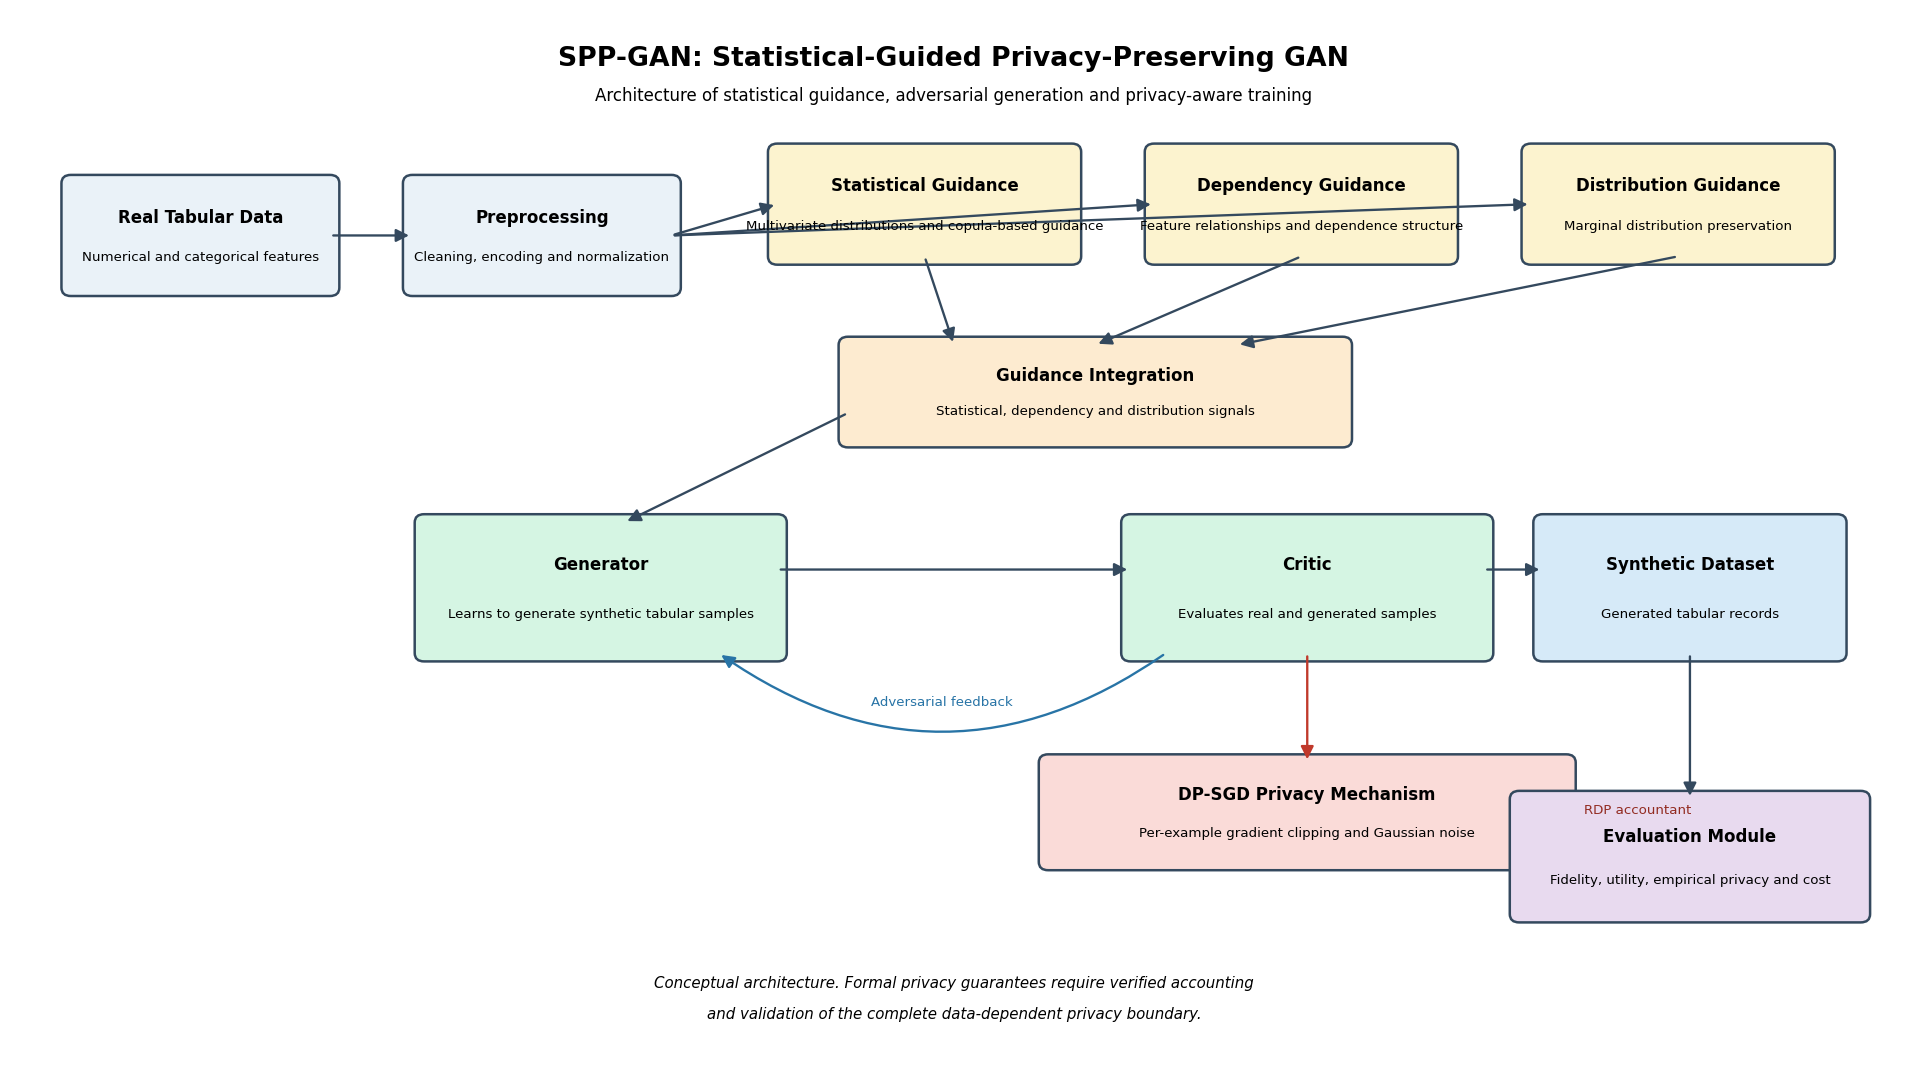

In [36]:
# ============================================================
# SECTION 17 — SPP-GAN ARCHITECTURE FIGURE
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import json

from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# ------------------------------------------------------------
# CONFIGURATION AND SAFE INITIALIZATION
# ------------------------------------------------------------

PUBLICATION_DPI = globals().get("PUBLICATION_DPI", 600)

if "publication_figures" not in globals():
    publication_figures = {}

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# ARCHITECTURE FIGURE FUNCTION
# ------------------------------------------------------------

def create_architecture_figure():

    fig, ax = plt.subplots(figsize=(16, 9))

    ax.set_xlim(0, 16)
    ax.set_ylim(0, 10)
    ax.axis("off")

    # --------------------------------------------------------
    # DRAWING HELPERS
    # --------------------------------------------------------

    def add_box(
        x, y, width, height,
        title, description,
        facecolor="#EAF2F8",
        edgecolor="#34495E",
        title_size=10,
        description_size=8
    ):

        box = FancyBboxPatch(
            (x, y),
            width,
            height,
            boxstyle="round,pad=0.08",
            linewidth=1.5,
            edgecolor=edgecolor,
            facecolor=facecolor
        )

        ax.add_patch(box)

        ax.text(
            x + width / 2,
            y + height * 0.68,
            title,
            ha="center",
            va="center",
            fontsize=title_size,
            fontweight="bold"
        )

        ax.text(
            x + width / 2,
            y + height * 0.30,
            description,
            ha="center",
            va="center",
            fontsize=description_size,
            wrap=True
        )

    def add_arrow(
        x1, y1, x2, y2,
        color="#34495E",
        style="-|>",
        linewidth=1.4,
        connectionstyle="arc3,rad=0"
    ):

        arrow = FancyArrowPatch(
            (x1, y1),
            (x2, y2),
            arrowstyle=style,
            mutation_scale=16,
            linewidth=linewidth,
            color=color,
            connectionstyle=connectionstyle
        )

        ax.add_patch(arrow)

    # --------------------------------------------------------
    # TITLE
    # --------------------------------------------------------

    ax.text(
        8, 9.55,
        "SPP-GAN: Statistical-Guided Privacy-Preserving GAN",
        ha="center",
        va="center",
        fontsize=16,
        fontweight="bold"
    )

    ax.text(
        8, 9.15,
        "Architecture of statistical guidance, adversarial generation and privacy-aware training",
        ha="center",
        fontsize=10
    )

    # --------------------------------------------------------
    # INPUT AND PREPROCESSING
    # --------------------------------------------------------

    add_box(
        0.5, 7.35, 2.2, 1.0,
        "Real Tabular Data",
        "Numerical and categorical features"
    )

    add_box(
        3.4, 7.35, 2.2, 1.0,
        "Preprocessing",
        "Cleaning, encoding and normalization"
    )

    add_arrow(2.7, 7.85, 3.4, 7.85)

    # --------------------------------------------------------
    # PARALLEL GUIDANCE MODULES
    # --------------------------------------------------------

    add_box(
        6.5, 7.65, 2.5, 1.0,
        "Statistical Guidance",
        "Multivariate distributions and copula-based guidance",
        "#FCF3CF"
    )

    add_box(
        9.7, 7.65, 2.5, 1.0,
        "Dependency Guidance",
        "Feature relationships and dependence structure",
        "#FCF3CF"
    )

    add_box(
        12.9, 7.65, 2.5, 1.0,
        "Distribution Guidance",
        "Marginal distribution preservation",
        "#FCF3CF"
    )

    # Shared preprocessing output branches into guidance modules.
    add_arrow(5.6, 7.85, 6.5, 8.15)
    add_arrow(5.6, 7.85, 9.7, 8.15)
    add_arrow(5.6, 7.85, 12.9, 8.15)

    # --------------------------------------------------------
    # GUIDANCE INTEGRATION
    # --------------------------------------------------------

    add_box(
        7.1, 5.9, 4.2, 0.9,
        "Guidance Integration",
        "Statistical, dependency and distribution signals",
        "#FDEBD0"
    )

    add_arrow(7.75, 7.65, 8.0, 6.8)
    add_arrow(10.95, 7.65, 9.2, 6.8)
    add_arrow(14.15, 7.65, 10.4, 6.8)

    # --------------------------------------------------------
    # ADVERSARIAL GENERATION
    # --------------------------------------------------------

    add_box(
        3.5, 3.85, 3.0, 1.25,
        "Generator",
        "Learns to generate synthetic tabular samples",
        "#D5F5E3"
    )

    add_box(
        9.5, 3.85, 3.0, 1.25,
        "Critic",
        "Evaluates real and generated samples",
        "#D5F5E3"
    )

    # Guidance conditions the generator.
    add_arrow(7.1, 6.15, 5.2, 5.1)

    # Generator produces samples for critic.
    add_arrow(6.5, 4.65, 9.5, 4.65)

    # Adversarial feedback from critic to generator.
    add_arrow(
        9.8, 3.85,
        6.0, 3.85,
        color="#2874A6",
        connectionstyle="arc3,rad=-0.35"
    )

    ax.text(
        7.9, 3.35,
        "Adversarial feedback",
        ha="center",
        fontsize=8,
        color="#2874A6"
    )

    # --------------------------------------------------------
    # DIFFERENTIAL PRIVACY MECHANISM
    # --------------------------------------------------------

    add_box(
        8.8, 1.85, 4.4, 0.95,
        "DP-SGD Privacy Mechanism",
        "Per-example gradient clipping and Gaussian noise",
        "#FADBD8"
    )

    add_arrow(
        11.0, 3.85,
        11.0, 2.8,
        color="#C0392B"
    )

    ax.text(
        13.35, 2.35,
        "RDP accountant",
        ha="left",
        va="center",
        fontsize=8,
        color="#922B21"
    )

    # --------------------------------------------------------
    # SYNTHETIC OUTPUT
    # --------------------------------------------------------

    add_box(
        13.0, 3.85, 2.5, 1.25,
        "Synthetic Dataset",
        "Generated tabular records",
        "#D6EAF8"
    )

    add_arrow(12.5, 4.65, 13.0, 4.65)

    # --------------------------------------------------------
    # EVALUATION MODULE
    # --------------------------------------------------------

    add_box(
        12.8, 1.35, 2.9, 1.1,
        "Evaluation Module",
        "Fidelity, utility, empirical privacy and cost",
        "#E8DAEF"
    )

    add_arrow(14.25, 3.85, 14.25, 2.45)

    # --------------------------------------------------------
    # FOOTNOTE
    # --------------------------------------------------------

    ax.text(
        8, 0.65,
        "Conceptual architecture. Formal privacy guarantees require verified accounting",
        ha="center",
        fontsize=9,
        style="italic"
    )

    ax.text(
        8, 0.35,
        "and validation of the complete data-dependent privacy boundary.",
        ha="center",
        fontsize=9,
        style="italic"
    )

    fig.tight_layout()

    return fig


# ------------------------------------------------------------
# CREATE AND REGISTER FIGURE
# ------------------------------------------------------------

architecture_fig = create_architecture_figure()

publication_figures["sppgan_architecture"] = architecture_fig

# ------------------------------------------------------------
# SAVE PUBLICATION FIGURE
# ------------------------------------------------------------

architecture_figure_path = (
    FIGURES_DIR / "sppgan_architecture.png"
)

architecture_fig.savefig(
    architecture_figure_path,
    dpi=PUBLICATION_DPI,
    bbox_inches="tight",
    facecolor="white"
)

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

section_17_checks = {
    "architecture_figure_created": (
        architecture_fig is not None
    ),
    "figure_registered": (
        "sppgan_architecture" in publication_figures
    ),
    "figure_saved": (
        architecture_figure_path.is_file()
    ),
    "publication_resolution_configured": (
        PUBLICATION_DPI >= 300
    ),
    "figure_dimensions_valid": (
        architecture_fig.get_figwidth() > 0
        and architecture_fig.get_figheight() > 0
    ),
    "figure_file_nonempty": (
        architecture_figure_path.is_file()
        and architecture_figure_path.stat().st_size > 0
    )
}

section_17_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_17_checks.items()
])

section_17_validation.to_csv(
    VALIDATION_DIR / "section_17_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print("SPP-GAN architecture figure created.")
print("Saved:", architecture_figure_path)
print("Publication DPI:", PUBLICATION_DPI)

print("\nVALIDATION")
print(section_17_validation.to_string(index=False))

section_17_passed = bool(
    section_17_validation["passed"].all()
)

print(
    "\nSECTION 17 STATUS:",
    "PASS" if section_17_passed else "FAIL"
)

assert section_17_passed, (
    "Section 17 architecture figure validation failed."
)

Research framework figure created.
Saved: /content/drive/MyDrive/SPP_GAN_Research/results/notebooks/notebook_21/figures/research_framework.png
Publication DPI: 600

VALIDATION
                            check  passed
         framework_figure_created    True
                figure_registered    True
                     figure_saved    True
publication_resolution_configured    True
          figure_dimensions_valid    True
             figure_file_nonempty    True

SECTION 18 STATUS: PASS


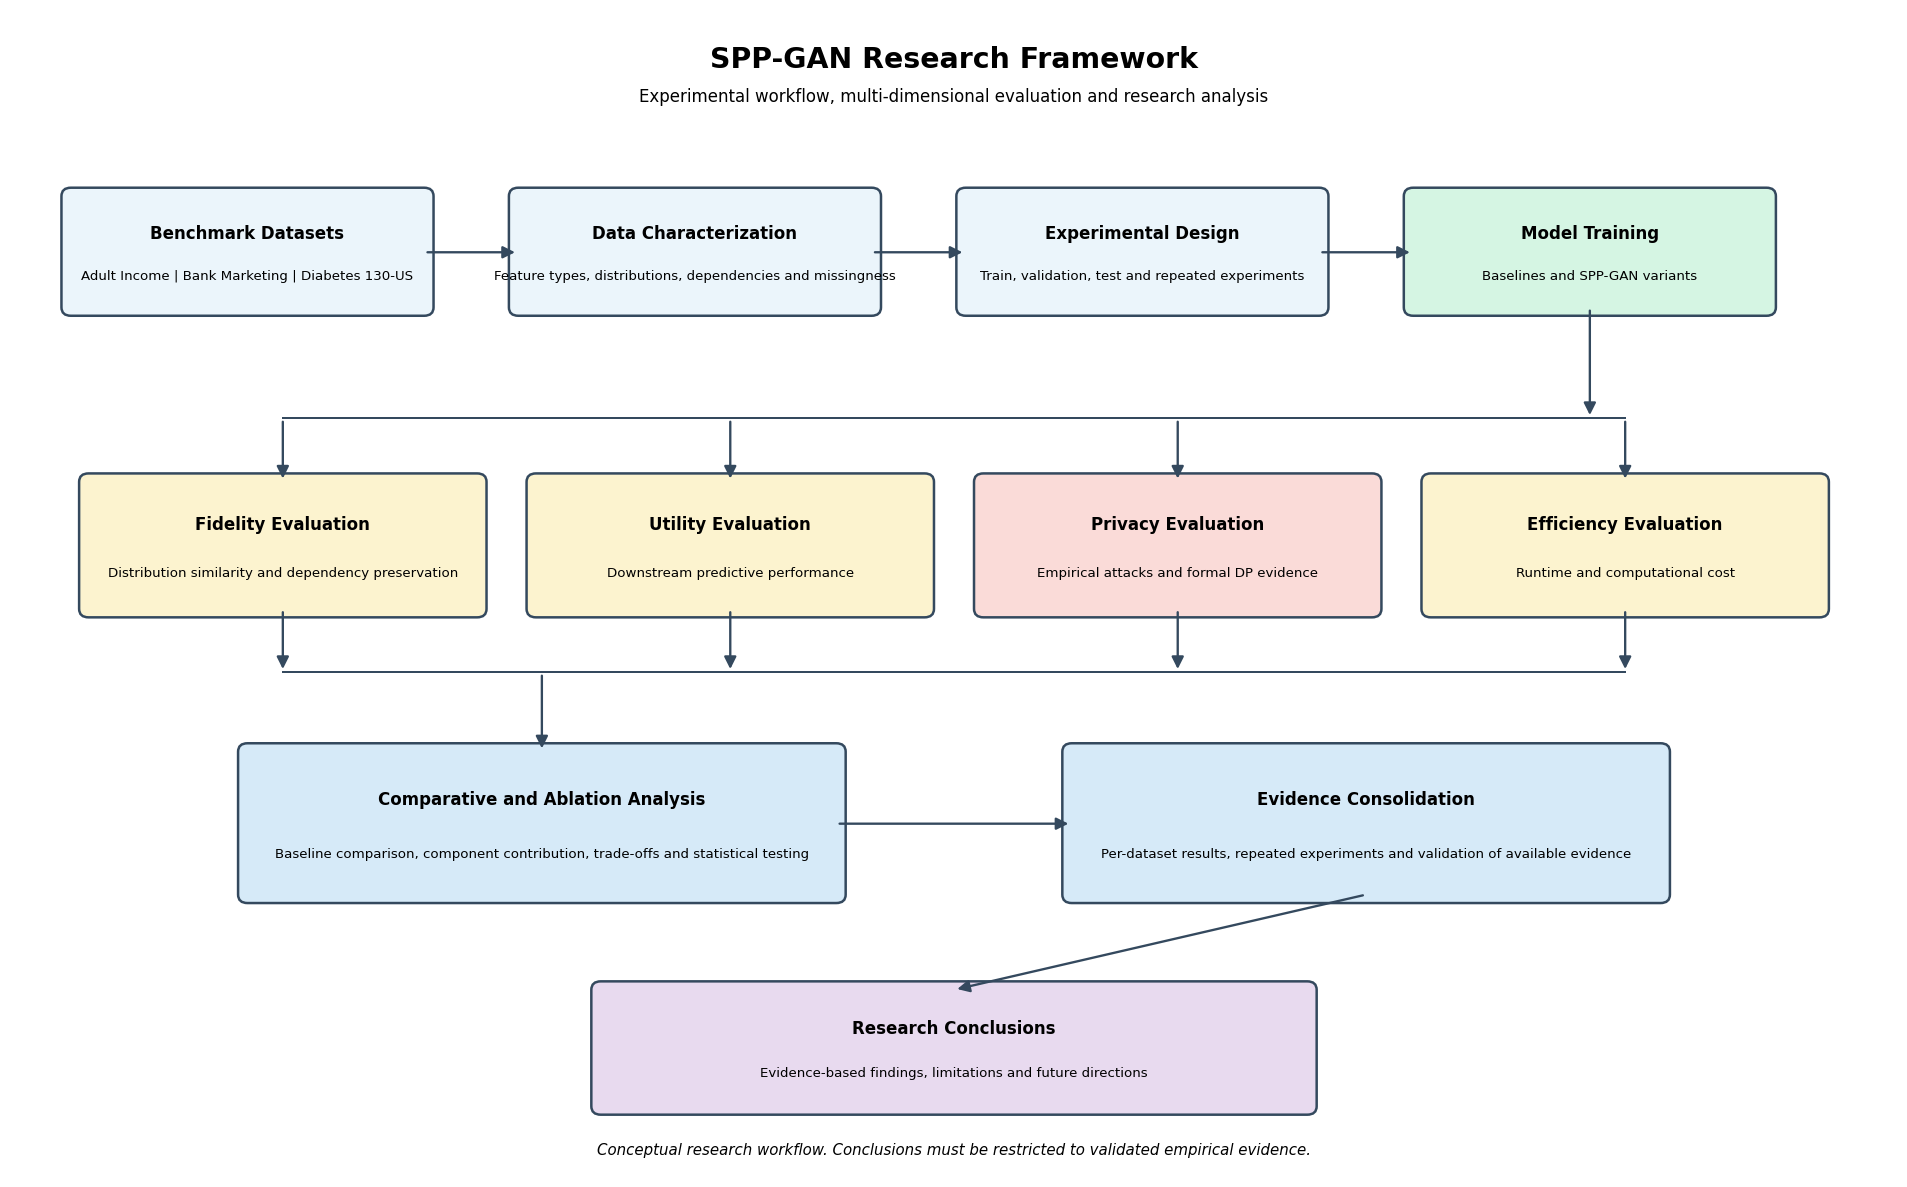

In [38]:
# ============================================================
# SECTION 18 — RESEARCH FRAMEWORK FIGURE
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# ------------------------------------------------------------
# CONFIGURATION AND SAFE INITIALIZATION
# ------------------------------------------------------------

PUBLICATION_DPI = globals().get("PUBLICATION_DPI", 600)

if "publication_figures" not in globals():
    publication_figures = {}

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# CREATE RESEARCH FRAMEWORK
# ------------------------------------------------------------

def create_research_framework():

    fig, ax = plt.subplots(figsize=(16, 10))

    ax.set_xlim(0, 16)
    ax.set_ylim(0, 11)
    ax.axis("off")

    # --------------------------------------------------------
    # DRAWING HELPERS
    # --------------------------------------------------------

    def box(
        x, y, w, h,
        title, description,
        facecolor="#EBF5FB",
        edgecolor="#34495E"
    ):

        item = FancyBboxPatch(
            (x, y),
            w,
            h,
            boxstyle="round,pad=0.08",
            facecolor=facecolor,
            edgecolor=edgecolor,
            linewidth=1.5
        )

        ax.add_patch(item)

        ax.text(
            x + w / 2,
            y + h * 0.67,
            title,
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold"
        )

        ax.text(
            x + w / 2,
            y + h * 0.29,
            description,
            ha="center",
            va="center",
            fontsize=8,
            wrap=True
        )

    def arrow(
        x1, y1, x2, y2,
        color="#34495E",
        linewidth=1.4,
        connectionstyle="arc3,rad=0"
    ):

        ax.add_patch(
            FancyArrowPatch(
                (x1, y1),
                (x2, y2),
                arrowstyle="-|>",
                mutation_scale=15,
                linewidth=linewidth,
                color=color,
                connectionstyle=connectionstyle
            )
        )

    # --------------------------------------------------------
    # TITLE
    # --------------------------------------------------------

    ax.text(
        8, 10.55,
        "SPP-GAN Research Framework",
        ha="center",
        va="center",
        fontsize=17,
        fontweight="bold"
    )

    ax.text(
        8, 10.15,
        "Experimental workflow, multi-dimensional evaluation and research analysis",
        ha="center",
        fontsize=10
    )

    # --------------------------------------------------------
    # STAGE 1 — RESEARCH INPUTS
    # --------------------------------------------------------

    box(
        0.5, 8.2, 3.0, 1.05,
        "Benchmark Datasets",
        "Adult Income | Bank Marketing | Diabetes 130-US"
    )

    box(
        4.3, 8.2, 3.0, 1.05,
        "Data Characterization",
        "Feature types, distributions, dependencies and missingness"
    )

    box(
        8.1, 8.2, 3.0, 1.05,
        "Experimental Design",
        "Train, validation, test and repeated experiments"
    )

    box(
        11.9, 8.2, 3.0, 1.05,
        "Model Training",
        "Baselines and SPP-GAN variants",
        "#D5F5E3"
    )

    arrow(3.5, 8.72, 4.3, 8.72)
    arrow(7.3, 8.72, 8.1, 8.72)
    arrow(11.1, 8.72, 11.9, 8.72)

    # --------------------------------------------------------
    # STAGE 2 — EVALUATION DIMENSIONS
    # --------------------------------------------------------

    box(
        0.65, 5.35, 3.3, 1.2,
        "Fidelity Evaluation",
        "Distribution similarity and dependency preservation",
        "#FCF3CF"
    )

    box(
        4.45, 5.35, 3.3, 1.2,
        "Utility Evaluation",
        "Downstream predictive performance",
        "#FCF3CF"
    )

    box(
        8.25, 5.35, 3.3, 1.2,
        "Privacy Evaluation",
        "Empirical attacks and formal DP evidence",
        "#FADBD8"
    )

    box(
        12.05, 5.35, 3.3, 1.2,
        "Efficiency Evaluation",
        "Runtime and computational cost",
        "#FCF3CF"
    )

    # Model training feeds a common evaluation stage.
    # The shared connector avoids crossing arrows.
    arrow(13.4, 8.2, 13.4, 7.15)

    ax.plot(
        [2.3, 13.7],
        [7.15, 7.15],
        linewidth=1.2,
        color="#34495E"
    )

    for center_x in [2.3, 6.1, 9.9, 13.7]:
        arrow(
            center_x,
            7.15,
            center_x,
            6.55
        )

    # --------------------------------------------------------
    # STAGE 3 — COMPARATIVE ANALYSIS
    # --------------------------------------------------------

    box(
        2.0, 2.65, 5.0, 1.35,
        "Comparative and Ablation Analysis",
        "Baseline comparison, component contribution, trade-offs and statistical testing",
        "#D6EAF8"
    )

    box(
        9.0, 2.65, 5.0, 1.35,
        "Evidence Consolidation",
        "Per-dataset results, repeated experiments and validation of available evidence",
        "#D6EAF8"
    )

    # Evaluation outputs feed the analysis stage.
    ax.plot(
        [2.3, 13.7],
        [4.75, 4.75],
        linewidth=1.2,
        color="#34495E"
    )

    for center_x in [2.3, 6.1, 9.9, 13.7]:
        arrow(
            center_x,
            5.35,
            center_x,
            4.75
        )

    arrow(4.5, 4.75, 4.5, 4.0)
    arrow(7.0, 3.32, 9.0, 3.32)

    # --------------------------------------------------------
    # STAGE 4 — RESEARCH CONCLUSIONS
    # --------------------------------------------------------

    box(
        5.0, 0.65, 6.0, 1.1,
        "Research Conclusions",
        "Evidence-based findings, limitations and future directions",
        "#E8DAEF"
    )

    arrow(11.5, 2.65, 8.0, 1.75)

    # --------------------------------------------------------
    # FOOTNOTE
    # --------------------------------------------------------

    ax.text(
        8, 0.2,
        "Conceptual research workflow. Conclusions must be restricted to validated empirical evidence.",
        ha="center",
        fontsize=9,
        style="italic"
    )

    fig.tight_layout()

    return fig


# ------------------------------------------------------------
# CREATE AND REGISTER FIGURE
# ------------------------------------------------------------

framework_fig = create_research_framework()

publication_figures["research_framework"] = framework_fig

# ------------------------------------------------------------
# SAVE PUBLICATION FIGURE
# ------------------------------------------------------------

framework_figure_path = (
    FIGURES_DIR / "research_framework.png"
)

framework_fig.savefig(
    framework_figure_path,
    dpi=PUBLICATION_DPI,
    bbox_inches="tight",
    facecolor="white"
)

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

section_18_checks = {
    "framework_figure_created": (
        framework_fig is not None
    ),
    "figure_registered": (
        "research_framework" in publication_figures
    ),
    "figure_saved": (
        framework_figure_path.is_file()
    ),
    "publication_resolution_configured": (
        PUBLICATION_DPI >= 300
    ),
    "figure_dimensions_valid": (
        framework_fig.get_figwidth() > 0
        and framework_fig.get_figheight() > 0
    ),
    "figure_file_nonempty": (
        framework_figure_path.is_file()
        and framework_figure_path.stat().st_size > 0
    )
}

section_18_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_18_checks.items()
])

section_18_validation.to_csv(
    VALIDATION_DIR / "section_18_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print("Research framework figure created.")
print("Saved:", framework_figure_path)
print("Publication DPI:", PUBLICATION_DPI)

print("\nVALIDATION")
print(section_18_validation.to_string(index=False))

section_18_passed = bool(
    section_18_validation["passed"].all()
)

print(
    "\nSECTION 18 STATUS:",
    "PASS" if section_18_passed else "FAIL"
)

assert section_18_passed, (
    "Section 18 research framework validation failed."
)

In [39]:
# ============================================================
# SHARED HELPER — PUBLICATION FIGURE GENERATION
# Used by Sections 19–24
# ============================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# ------------------------------------------------------------
# SAFE INITIALIZATION
# ------------------------------------------------------------

PUBLICATION_DPI = globals().get("PUBLICATION_DPI", 600)

if "publication_figures" not in globals():
    publication_figures = {}

if "publication_figure_status" not in globals():
    publication_figure_status = {}

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

VALIDATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# PUBLICATION FIGURE GENERATION FUNCTION
# ------------------------------------------------------------

def create_evidence_figure(
    table,
    title,
    filename,
    metric_column="value",
    group_column="model"
):

    # --------------------------------------------------------
    # VALIDATE INPUT
    # --------------------------------------------------------

    if not isinstance(table, pd.DataFrame):

        raise TypeError(
            "Figure input must be a pandas DataFrame."
        )

    if not isinstance(filename, str) or not filename.strip():

        raise ValueError(
            "A valid figure filename must be provided."
        )

    if not isinstance(title, str) or not title.strip():

        raise ValueError(
            "A valid figure title must be provided."
        )

    # --------------------------------------------------------
    # CREATE FIGURE
    # --------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    source_records = len(table)

    valid = pd.DataFrame()

    missing_columns = [
        column
        for column in [metric_column, group_column]
        if column not in table.columns
    ]

    # --------------------------------------------------------
    # PREPARE VALID NUMERIC EVIDENCE
    # --------------------------------------------------------

    if (
        not table.empty
        and not missing_columns
    ):

        valid = table.copy()

        valid[metric_column] = pd.to_numeric(
            valid[metric_column],
            errors="coerce"
        )

        valid = valid.loc[
            np.isfinite(
                valid[metric_column].to_numpy(
                    dtype=float
                )
            )
            & valid[group_column].notna()
        ].copy()

    # --------------------------------------------------------
    # GENERATE EMPIRICAL FIGURE
    # --------------------------------------------------------

    if not valid.empty:

        grouped = (
            valid.groupby(
                group_column,
                dropna=False
            )[metric_column]
            .mean()
            .sort_values()
        )

        grouped.plot(
            kind="bar",
            ax=ax,
            width=0.7
        )

        ax.set_ylabel(
            metric_column.replace("_", " ").title()
        )

        ax.set_xlabel(
            group_column.replace("_", " ").title()
        )

        ax.tick_params(
            axis="x",
            labelrotation=35
        )

        ax.grid(
            axis="y",
            linestyle="--",
            alpha=0.3
        )

        evidence_status = (
            "EMPIRICAL_MEASUREMENTS_AVAILABLE"
        )

    # --------------------------------------------------------
    # HANDLE MISSING EMPIRICAL EVIDENCE
    # --------------------------------------------------------

    else:

        ax.text(
            0.5,
            0.57,
            "EMPIRICAL EVIDENCE UNAVAILABLE",
            ha="center",
            va="center",
            transform=ax.transAxes,
            fontsize=14,
            fontweight="bold"
        )

        ax.text(
            0.5,
            0.43,
            "No valid numeric measurements were available.",
            ha="center",
            va="center",
            transform=ax.transAxes,
            fontsize=10
        )

        ax.text(
            0.5,
            0.28,
            "NOT FOR PUBLICATION AS AN EMPIRICAL RESULT",
            ha="center",
            va="center",
            transform=ax.transAxes,
            fontsize=9,
            color="red"
        )

        ax.set_xticks([])
        ax.set_yticks([])

        evidence_status = (
            "MISSING_EMPIRICAL_EVIDENCE"
        )

    # --------------------------------------------------------
    # FIGURE FORMATTING
    # --------------------------------------------------------

    ax.set_title(
        title,
        fontweight="bold",
        pad=15
    )

    fig.tight_layout()

    # --------------------------------------------------------
    # NORMALIZE OUTPUT FILENAME
    # --------------------------------------------------------

    safe_filename = Path(filename).name

    if not safe_filename.lower().endswith(".png"):

        safe_filename = safe_filename + ".png"

    figure_path = (
        FIGURES_DIR / safe_filename
    )

    # --------------------------------------------------------
    # SAVE PUBLICATION FIGURE
    # --------------------------------------------------------

    fig.savefig(
        figure_path,
        dpi=PUBLICATION_DPI,
        bbox_inches="tight",
        facecolor="white"
    )

    # --------------------------------------------------------
    # REGISTER FIGURE CONSISTENTLY
    # --------------------------------------------------------

    figure_key = Path(safe_filename).stem

    # Store the actual Matplotlib figure object.
    publication_figures[figure_key] = fig

    # Keep evidence metadata separately.
    publication_figure_status[figure_key] = {
        "title": title,
        "filename": safe_filename,
        "figure_path": str(figure_path),
        "source_records": source_records,
        "valid_measurements": len(valid),
        "metric_column": metric_column,
        "group_column": group_column,
        "missing_columns": missing_columns,
        "evidence_status": evidence_status,
        "publication_dpi": PUBLICATION_DPI
    }

    # --------------------------------------------------------
    # RETURN FIGURE
    # --------------------------------------------------------

    return fig


# ============================================================
# SHARED HELPER VALIDATION
# ============================================================

section_helper_checks = {
    "figure_function_defined": callable(
        create_evidence_figure
    ),

    "publication_figure_registry_available": isinstance(
        publication_figures,
        dict
    ),

    "figure_status_registry_available": isinstance(
        publication_figure_status,
        dict
    ),

    "figures_directory_exists": (
        FIGURES_DIR.is_dir()
    ),

    "validation_directory_exists": (
        VALIDATION_DIR.is_dir()
    ),

    "publication_dpi_valid": (
        PUBLICATION_DPI >= 300
    )
}

section_helper_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_helper_checks.items()
])

section_helper_validation.to_csv(
    VALIDATION_DIR / "publication_figure_helper_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print("Publication figure helper initialized.")

print(
    "Publication DPI:",
    PUBLICATION_DPI
)

print(
    "Figure output directory:",
    FIGURES_DIR
)

print(
    "Registered figures:",
    len(publication_figures)
)

print("\nVALIDATION")

print(
    section_helper_validation.to_string(index=False)
)

section_helper_passed = bool(
    section_helper_validation["passed"].all()
)

print(
    "\nPUBLICATION FIGURE HELPER STATUS:",
    "PASS" if section_helper_passed else "FAIL"
)

assert section_helper_passed, (
    "Publication figure helper validation failed."
)

Publication figure helper initialized.
Publication DPI: 600
Figure output directory: /content/drive/MyDrive/SPP_GAN_Research/results/notebooks/notebook_21/figures
Registered figures: 2

VALIDATION
                                check  passed
              figure_function_defined    True
publication_figure_registry_available    True
     figure_status_registry_available    True
             figures_directory_exists    True
          validation_directory_exists    True
                publication_dpi_valid    True

PUBLICATION FIGURE HELPER STATUS: PASS


Fidelity figure created.
Fidelity figure evidence: MISSING_EMPIRICAL_EVIDENCE
Source records: 0
Valid measurements: 0
Saved figure: /content/drive/MyDrive/SPP_GAN_Research/results/notebooks/notebook_21/figures/statistical_fidelity.png

VALIDATION
                   check  passed
 fidelity_figure_created    True
       figure_registered    True
figure_status_registered    True
            figure_saved    True
evidence_status_recorded    True
source_records_preserved    True

SECTION 19 STATUS: PASS


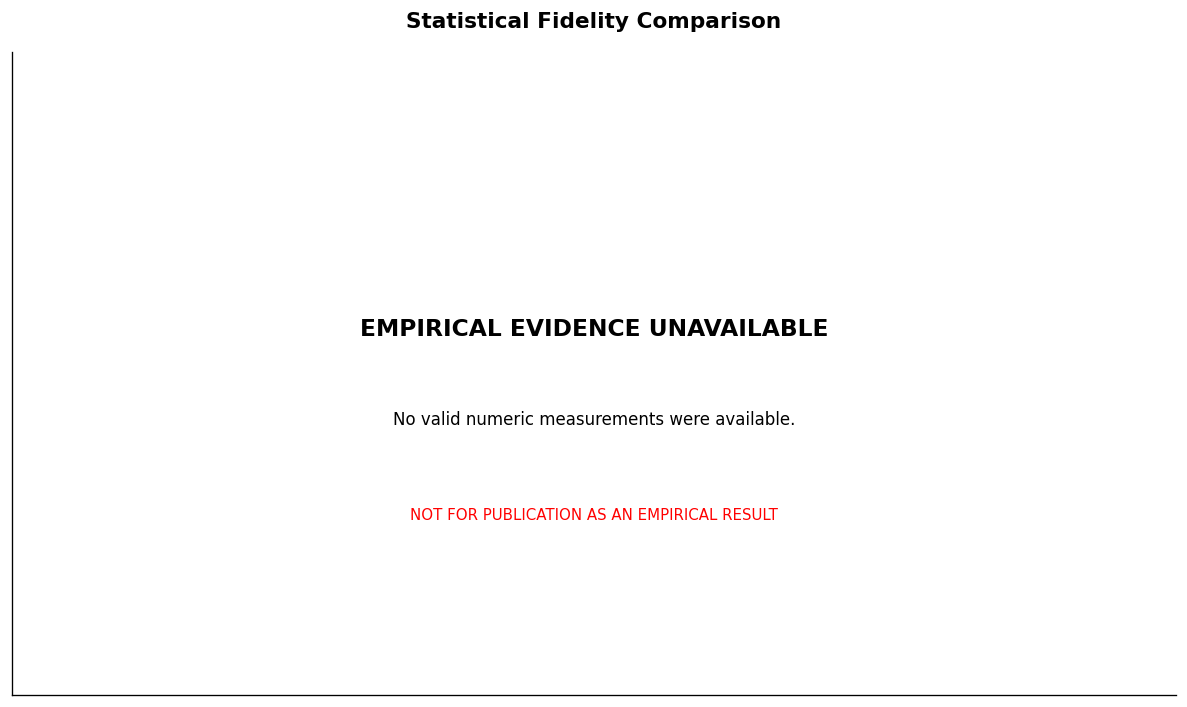

In [41]:
# ============================================================
# SECTION 19 — FIDELITY FIGURES
# ============================================================

# ------------------------------------------------------------
# GENERATE FIDELITY FIGURE
# ------------------------------------------------------------

fidelity_figure = create_evidence_figure(
    fidelity_table,
    "Statistical Fidelity Comparison",
    "statistical_fidelity",
    metric_column="value",
    group_column="model"
)

# ------------------------------------------------------------
# RETRIEVE FIGURE EVIDENCE STATUS
# ------------------------------------------------------------

fidelity_figure_status = publication_figure_status.get(
    "statistical_fidelity",
    {}
)

fidelity_evidence_status = fidelity_figure_status.get(
    "evidence_status",
    "UNKNOWN"
)

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

fidelity_figure_path = (
    FIGURES_DIR / "statistical_fidelity.png"
)

section_19_checks = {
    "fidelity_figure_created": (
        fidelity_figure is not None
    ),

    "figure_registered": (
        "statistical_fidelity" in publication_figures
    ),

    "figure_status_registered": (
        "statistical_fidelity" in publication_figure_status
    ),

    "figure_saved": (
        fidelity_figure_path.is_file()
    ),

    "evidence_status_recorded": (
        fidelity_evidence_status in [
            "EMPIRICAL_MEASUREMENTS_AVAILABLE",
            "MISSING_EMPIRICAL_EVIDENCE"
        ]
    ),

    "source_records_preserved": (
        fidelity_figure_status.get("source_records")
        == len(fidelity_table)
    )
}

section_19_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_19_checks.items()
])

section_19_validation.to_csv(
    VALIDATION_DIR / "section_19_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print("Fidelity figure created.")

print(
    "Fidelity figure evidence:",
    fidelity_evidence_status
)

print(
    "Source records:",
    fidelity_figure_status.get("source_records")
)

print(
    "Valid measurements:",
    fidelity_figure_status.get("valid_measurements")
)

print(
    "Saved figure:",
    fidelity_figure_path
)

print("\nVALIDATION")
print(section_19_validation.to_string(index=False))

section_19_passed = bool(
    section_19_validation["passed"].all()
)

print(
    "\nSECTION 19 STATUS:",
    "PASS" if section_19_passed else "FAIL"
)

assert section_19_passed, (
    "Section 19 fidelity figure validation failed."
)

Utility figure created.
Utility figure evidence: MISSING_EMPIRICAL_EVIDENCE
Source records: 0
Valid measurements: 0
Saved figure: /content/drive/MyDrive/SPP_GAN_Research/results/notebooks/notebook_21/figures/ml_utility.png

VALIDATION
                   check  passed
  utility_figure_created    True
       figure_registered    True
figure_status_registered    True
            figure_saved    True
evidence_status_recorded    True
source_records_preserved    True

SECTION 20 STATUS: PASS


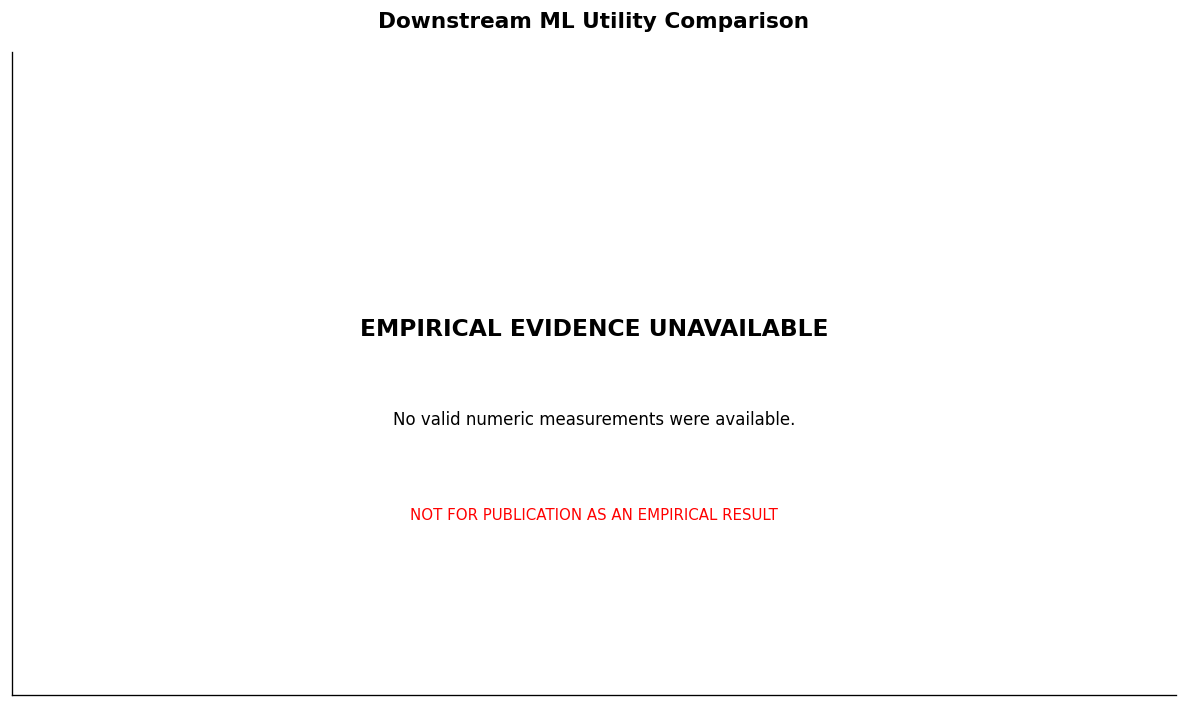

In [43]:
# ============================================================
# SECTION 20 — UTILITY FIGURES
# ============================================================

# ------------------------------------------------------------
# GENERATE UTILITY FIGURE
# ------------------------------------------------------------

utility_figure = create_evidence_figure(
    utility_table,
    "Downstream ML Utility Comparison",
    "ml_utility",
    metric_column="value",
    group_column="model"
)

# ------------------------------------------------------------
# RETRIEVE FIGURE EVIDENCE STATUS
# ------------------------------------------------------------

utility_figure_status = publication_figure_status.get(
    "ml_utility",
    {}
)

utility_evidence_status = utility_figure_status.get(
    "evidence_status",
    "UNKNOWN"
)

# ------------------------------------------------------------
# VALIDATE FIGURE
# ------------------------------------------------------------

utility_figure_path = (
    FIGURES_DIR / "ml_utility.png"
)

section_20_checks = {
    "utility_figure_created": (
        utility_figure is not None
    ),

    "figure_registered": (
        "ml_utility" in publication_figures
    ),

    "figure_status_registered": (
        "ml_utility" in publication_figure_status
    ),

    "figure_saved": (
        utility_figure_path.is_file()
    ),

    "evidence_status_recorded": (
        utility_evidence_status in [
            "EMPIRICAL_MEASUREMENTS_AVAILABLE",
            "MISSING_EMPIRICAL_EVIDENCE"
        ]
    ),

    "source_records_preserved": (
        utility_figure_status.get("source_records")
        == len(utility_table)
    )
}

section_20_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_20_checks.items()
])

section_20_validation.to_csv(
    VALIDATION_DIR / "section_20_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print("Utility figure created.")

print(
    "Utility figure evidence:",
    utility_evidence_status
)

print(
    "Source records:",
    utility_figure_status.get("source_records")
)

print(
    "Valid measurements:",
    utility_figure_status.get("valid_measurements")
)

print(
    "Saved figure:",
    utility_figure_path
)

print("\nVALIDATION")
print(section_20_validation.to_string(index=False))

section_20_passed = bool(
    section_20_validation["passed"].all()
)

print(
    "\nSECTION 20 STATUS:",
    "PASS" if section_20_passed else "FAIL"
)

assert section_20_passed, (
    "Section 20 utility figure validation failed."
)

Privacy figure created.
Privacy figure evidence: MISSING_EMPIRICAL_EVIDENCE
Source records: 0
Valid measurements: 0
Saved figure: /content/drive/MyDrive/SPP_GAN_Research/results/notebooks/notebook_21/figures/empirical_privacy.png

VALIDATION
                   check  passed
  privacy_figure_created    True
       figure_registered    True
figure_status_registered    True
            figure_saved    True
evidence_status_recorded    True
source_records_preserved    True

SECTION 21 STATUS: PASS


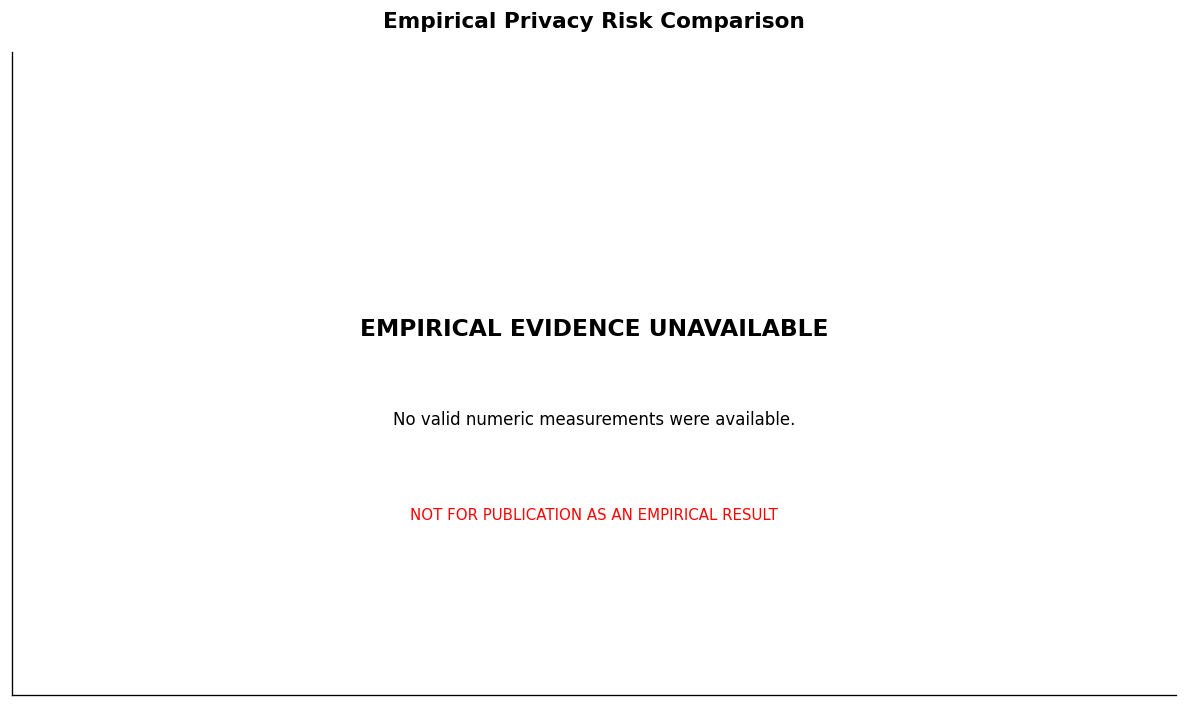

In [45]:
# ============================================================
# SECTION 21 — PRIVACY FIGURES
# ============================================================

# ------------------------------------------------------------
# GENERATE PRIVACY FIGURE
# ------------------------------------------------------------

privacy_figure = create_evidence_figure(
    privacy_table,
    "Empirical Privacy Risk Comparison",
    "empirical_privacy",
    metric_column="value",
    group_column="model"
)

# ------------------------------------------------------------
# RETRIEVE FIGURE EVIDENCE STATUS
# ------------------------------------------------------------

privacy_figure_status = publication_figure_status.get(
    "empirical_privacy",
    {}
)

privacy_evidence_status = privacy_figure_status.get(
    "evidence_status",
    "UNKNOWN"
)

# ------------------------------------------------------------
# VALIDATE FIGURE
# ------------------------------------------------------------

privacy_figure_path = (
    FIGURES_DIR / "empirical_privacy.png"
)

section_21_checks = {
    "privacy_figure_created": (
        privacy_figure is not None
    ),

    "figure_registered": (
        "empirical_privacy" in publication_figures
    ),

    "figure_status_registered": (
        "empirical_privacy" in publication_figure_status
    ),

    "figure_saved": (
        privacy_figure_path.is_file()
    ),

    "evidence_status_recorded": (
        privacy_evidence_status in [
            "EMPIRICAL_MEASUREMENTS_AVAILABLE",
            "MISSING_EMPIRICAL_EVIDENCE"
        ]
    ),

    "source_records_preserved": (
        privacy_figure_status.get("source_records")
        == len(privacy_table)
    )
}

section_21_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_21_checks.items()
])

section_21_validation.to_csv(
    VALIDATION_DIR / "section_21_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print("Privacy figure created.")

print(
    "Privacy figure evidence:",
    privacy_evidence_status
)

print(
    "Source records:",
    privacy_figure_status.get("source_records")
)

print(
    "Valid measurements:",
    privacy_figure_status.get("valid_measurements")
)

print(
    "Saved figure:",
    privacy_figure_path
)

print("\nVALIDATION")
print(section_21_validation.to_string(index=False))

section_21_passed = bool(
    section_21_validation["passed"].all()
)

print(
    "\nSECTION 21 STATUS:",
    "PASS" if section_21_passed else "FAIL"
)

assert section_21_passed, (
    "Section 21 privacy figure validation failed."
)

Ablation figure created.
Ablation figure evidence: MISSING_EMPIRICAL_EVIDENCE
Source records: 0
Valid measurements: 0
Saved figure: /content/drive/MyDrive/SPP_GAN_Research/results/notebooks/notebook_21/figures/ablation.png

VALIDATION
                   check  passed
 ablation_figure_created    True
       figure_registered    True
figure_status_registered    True
            figure_saved    True
evidence_status_recorded    True
source_records_preserved    True

SECTION 22 STATUS: PASS


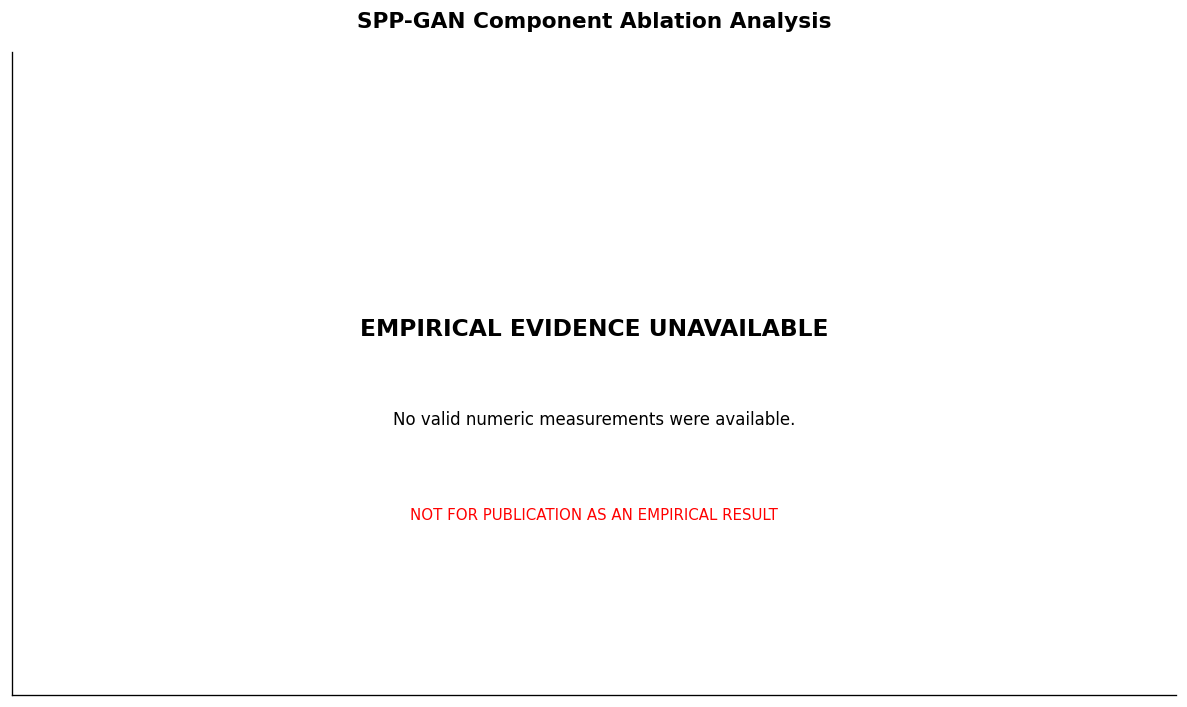

In [47]:
# ============================================================
# SECTION 22 — ABLATION FIGURES
# ============================================================

# ------------------------------------------------------------
# GENERATE ABLATION FIGURE
# ------------------------------------------------------------

ablation_figure = create_evidence_figure(
    ablation_table,
    "SPP-GAN Component Ablation Analysis",
    "ablation",
    metric_column="value",
    group_column="variant"
)

# ------------------------------------------------------------
# RETRIEVE FIGURE EVIDENCE STATUS
# ------------------------------------------------------------

ablation_figure_status = publication_figure_status.get(
    "ablation",
    {}
)

ablation_evidence_status = ablation_figure_status.get(
    "evidence_status",
    "UNKNOWN"
)

# ------------------------------------------------------------
# VALIDATE FIGURE
# ------------------------------------------------------------

ablation_figure_path = (
    FIGURES_DIR / "ablation.png"
)

section_22_checks = {
    "ablation_figure_created": (
        ablation_figure is not None
    ),

    "figure_registered": (
        "ablation" in publication_figures
    ),

    "figure_status_registered": (
        "ablation" in publication_figure_status
    ),

    "figure_saved": (
        ablation_figure_path.is_file()
    ),

    "evidence_status_recorded": (
        ablation_evidence_status in [
            "EMPIRICAL_MEASUREMENTS_AVAILABLE",
            "MISSING_EMPIRICAL_EVIDENCE"
        ]
    ),

    "source_records_preserved": (
        ablation_figure_status.get("source_records")
        == len(ablation_table)
    )
}

section_22_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_22_checks.items()
])

section_22_validation.to_csv(
    VALIDATION_DIR / "section_22_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print("Ablation figure created.")

print(
    "Ablation figure evidence:",
    ablation_evidence_status
)

print(
    "Source records:",
    ablation_figure_status.get("source_records")
)

print(
    "Valid measurements:",
    ablation_figure_status.get("valid_measurements")
)

print(
    "Saved figure:",
    ablation_figure_path
)

print("\nVALIDATION")
print(section_22_validation.to_string(index=False))

section_22_passed = bool(
    section_22_validation["passed"].all()
)

print(
    "\nSECTION 22 STATUS:",
    "PASS" if section_22_passed else "FAIL"
)

assert section_22_passed, (
    "Section 22 ablation figure validation failed."
)

Trade-off figure created.
Trade-off evidence: MISSING_EMPIRICAL_EVIDENCE
Source records: 22
Valid complete measurements: 0
Missing required columns: []
Pareto efficiency established: False
Saved figure: /content/drive/MyDrive/SPP_GAN_Research/results/notebooks/notebook_21/figures/tradeoff.png

VALIDATION
                       check  passed
     tradeoff_figure_created    True
           figure_registered    True
    figure_status_registered    True
                figure_saved    True
        figure_file_nonempty    True
    source_records_preserved    True
    evidence_status_recorded    True
publication_resolution_valid    True
 no_unsupported_pareto_claim    True

SECTION 23 STATUS: PASS


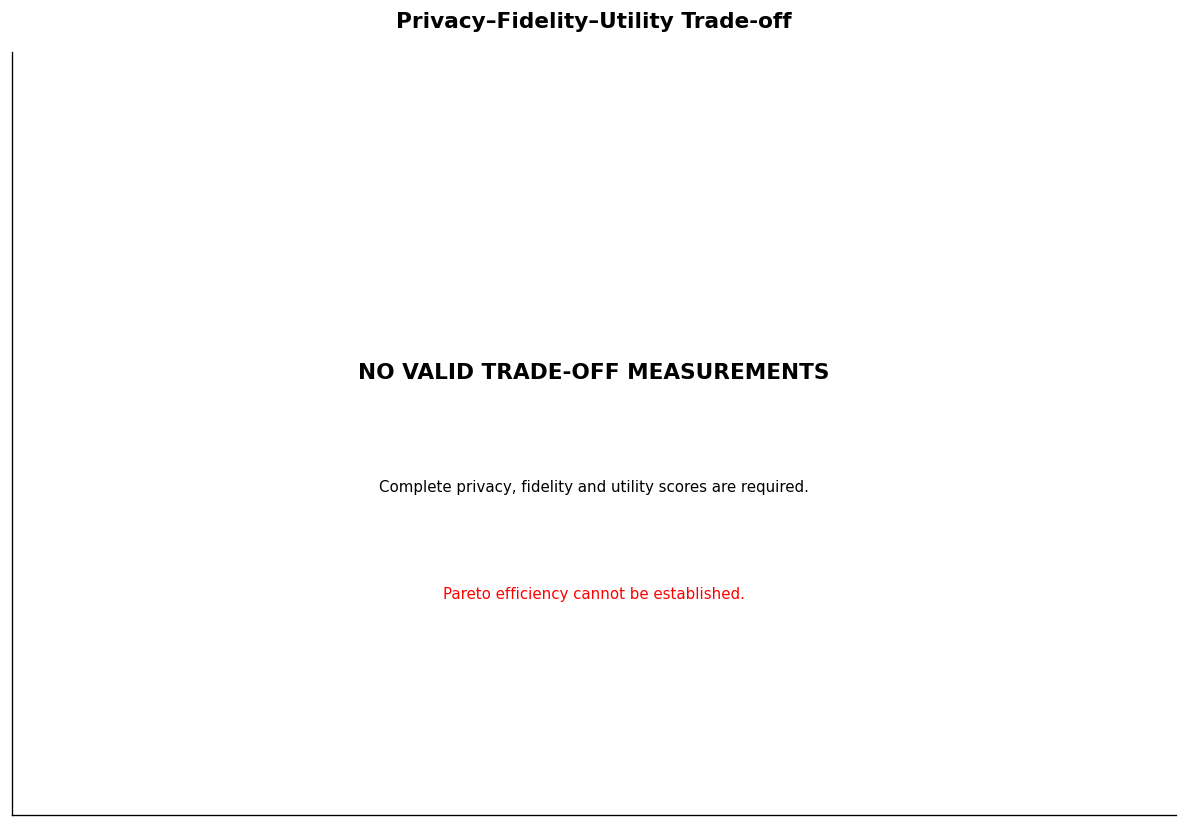

In [49]:
# ============================================================
# SECTION 23 — TRADE-OFF FIGURES
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# SAFE INITIALIZATION
# ------------------------------------------------------------

PUBLICATION_DPI = globals().get("PUBLICATION_DPI", 600)

if "publication_figures" not in globals():
    publication_figures = {}

if "publication_figure_status" not in globals():
    publication_figure_status = {}

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# REQUIRED TRADE-OFF COLUMNS
# ------------------------------------------------------------

TRADEOFF_REQUIRED_COLUMNS = [
    "privacy_score_mean",
    "fidelity_score_mean",
    "utility_score_mean"
]

# ------------------------------------------------------------
# TRADE-OFF FIGURE GENERATION
# ------------------------------------------------------------

def create_tradeoff_figure(table):

    fig, ax = plt.subplots(figsize=(10, 7))

    source_records = (
        len(table)
        if isinstance(table, pd.DataFrame)
        else 0
    )

    missing_columns = [
        column
        for column in TRADEOFF_REQUIRED_COLUMNS
        if (
            not isinstance(table, pd.DataFrame)
            or column not in table.columns
        )
    ]

    if (
        isinstance(table, pd.DataFrame)
        and not table.empty
        and not missing_columns
    ):

        data = table.copy()

        for column in TRADEOFF_REQUIRED_COLUMNS:
            data[column] = pd.to_numeric(
                data[column],
                errors="coerce"
            )

        data = data.replace(
            [np.inf, -np.inf],
            np.nan
        ).dropna(
            subset=TRADEOFF_REQUIRED_COLUMNS
        )

    else:
        data = pd.DataFrame()

    valid_measurements = len(data)

    if not data.empty:

        scatter = ax.scatter(
            data["fidelity_score_mean"],
            data["utility_score_mean"],
            c=data["privacy_score_mean"],
            s=75,
            alpha=0.85
        )

        colorbar = fig.colorbar(
            scatter,
            ax=ax
        )

        colorbar.set_label("Privacy Score")

        if "model" in data.columns:

            for _, row in data.iterrows():

                ax.annotate(
                    str(row["model"]),
                    (
                        row["fidelity_score_mean"],
                        row["utility_score_mean"]
                    ),
                    fontsize=7,
                    xytext=(4, 4),
                    textcoords="offset points"
                )

        ax.set_xlabel("Fidelity Score")
        ax.set_ylabel("Utility Score")

        ax.grid(
            linestyle="--",
            alpha=0.3
        )

        evidence_status = (
            "EMPIRICAL_MEASUREMENTS_AVAILABLE"
        )

    else:

        ax.text(
            0.5, 0.58,
            "NO VALID TRADE-OFF MEASUREMENTS",
            ha="center",
            va="center",
            transform=ax.transAxes,
            fontsize=13,
            fontweight="bold"
        )

        ax.text(
            0.5, 0.43,
            "Complete privacy, fidelity and utility scores are required.",
            ha="center",
            va="center",
            transform=ax.transAxes,
            fontsize=9
        )

        ax.text(
            0.5, 0.29,
            "Pareto efficiency cannot be established.",
            ha="center",
            va="center",
            transform=ax.transAxes,
            fontsize=9,
            color="red"
        )

        ax.set_xticks([])
        ax.set_yticks([])

        evidence_status = (
            "MISSING_EMPIRICAL_EVIDENCE"
        )

    ax.set_title(
        "Privacy–Fidelity–Utility Trade-off",
        fontweight="bold",
        pad=15
    )

    fig.tight_layout()

    return (
        fig,
        evidence_status,
        valid_measurements,
        missing_columns
    )


# ------------------------------------------------------------
# CREATE FIGURE
# ------------------------------------------------------------

(
    tradeoff_figure,
    tradeoff_evidence_status,
    tradeoff_valid_measurements,
    tradeoff_missing_columns
) = create_tradeoff_figure(
    tradeoff_table
)

# ------------------------------------------------------------
# REGISTER FIGURE
# ------------------------------------------------------------

publication_figures["tradeoff"] = tradeoff_figure

tradeoff_figure_path = (
    FIGURES_DIR / "tradeoff.png"
)

# ------------------------------------------------------------
# SAVE FIGURE
# ------------------------------------------------------------

tradeoff_figure.savefig(
    tradeoff_figure_path,
    dpi=PUBLICATION_DPI,
    bbox_inches="tight",
    facecolor="white"
)

# ------------------------------------------------------------
# SAVE FIGURE METADATA
# ------------------------------------------------------------

publication_figure_status["tradeoff"] = {
    "title": "Privacy–Fidelity–Utility Trade-off",
    "filename": "tradeoff.png",
    "figure_path": str(tradeoff_figure_path),
    "source_records": len(tradeoff_table),
    "valid_measurements": tradeoff_valid_measurements,
    "required_columns": TRADEOFF_REQUIRED_COLUMNS,
    "missing_columns": tradeoff_missing_columns,
    "evidence_status": tradeoff_evidence_status,
    "pareto_efficiency_established": False,
    "publication_dpi": PUBLICATION_DPI
}

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

section_23_checks = {
    "tradeoff_figure_created": (
        tradeoff_figure is not None
    ),

    "figure_registered": (
        "tradeoff" in publication_figures
    ),

    "figure_status_registered": (
        "tradeoff" in publication_figure_status
    ),

    "figure_saved": (
        tradeoff_figure_path.is_file()
    ),

    "figure_file_nonempty": (
        tradeoff_figure_path.is_file()
        and tradeoff_figure_path.stat().st_size > 0
    ),

    "source_records_preserved": (
        publication_figure_status["tradeoff"]["source_records"]
        == len(tradeoff_table)
    ),

    "evidence_status_recorded": (
        tradeoff_evidence_status in [
            "EMPIRICAL_MEASUREMENTS_AVAILABLE",
            "MISSING_EMPIRICAL_EVIDENCE"
        ]
    ),

    "publication_resolution_valid": (
        PUBLICATION_DPI >= 300
    ),

    "no_unsupported_pareto_claim": (
        publication_figure_status["tradeoff"][
            "pareto_efficiency_established"
        ] is False
    )
}

section_23_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_23_checks.items()
])

section_23_validation.to_csv(
    VALIDATION_DIR / "section_23_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print("Trade-off figure created.")

print(
    "Trade-off evidence:",
    tradeoff_evidence_status
)

print("Source records:", len(tradeoff_table))

print(
    "Valid complete measurements:",
    tradeoff_valid_measurements
)

print(
    "Missing required columns:",
    tradeoff_missing_columns
)

print("Pareto efficiency established: False")

print("Saved figure:", tradeoff_figure_path)

print("\nVALIDATION")
print(section_23_validation.to_string(index=False))

section_23_passed = bool(
    section_23_validation["passed"].all()
)

print(
    "\nSECTION 23 STATUS:",
    "PASS" if section_23_passed else "FAIL"
)

assert section_23_passed, (
    "Section 23 trade-off figure validation failed."
)

Significance figure created.
Significance evidence: MISSING_EXECUTED_STATISTICAL_EVIDENCE
Source records: 309
Verified executed tests: 0
P-value column: adjusted_p_value
P-value type: Holm-adjusted p-value
Saved figure: /content/drive/MyDrive/SPP_GAN_Research/results/notebooks/notebook_21/figures/significance.png

VALIDATION
                       check  passed
 significance_figure_created    True
           figure_registered    True
    figure_status_registered    True
                figure_saved    True
        figure_file_nonempty    True
    source_records_preserved    True
    evidence_status_recorded    True
     p_value_column_recorded    True
publication_resolution_valid    True

SECTION 24 STATUS: PASS


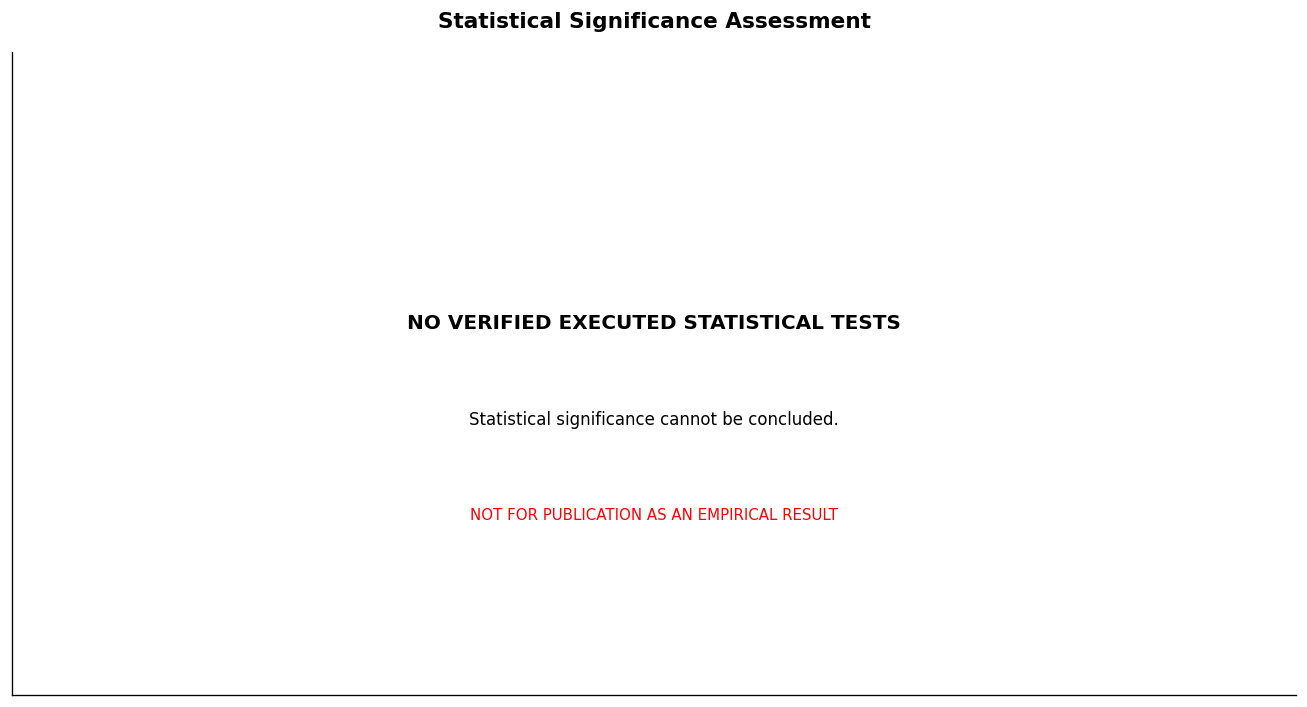

In [51]:
# ============================================================
# SECTION 24 — SIGNIFICANCE VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# SAFE INITIALIZATION
# ------------------------------------------------------------

PUBLICATION_DPI = globals().get("PUBLICATION_DPI", 600)

if "publication_figures" not in globals():
    publication_figures = {}

if "publication_figure_status" not in globals():
    publication_figure_status = {}

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# SIGNIFICANCE FIGURE GENERATION
# ------------------------------------------------------------

def create_significance_figure(table):

    fig, ax = plt.subplots(figsize=(11, 6))

    source_records = (
        len(table)
        if isinstance(table, pd.DataFrame)
        else 0
    )

    # --------------------------------------------------------
    # SELECT VERIFIED EXECUTED TESTS
    # --------------------------------------------------------

    if (
        isinstance(table, pd.DataFrame)
        and not table.empty
        and "executed_test_evidence" in table.columns
    ):

        valid = table.loc[
            table["executed_test_evidence"]
            .astype(str)
            .str.strip()
            .str.lower()
            .isin(["true", "1", "yes"])
        ].copy()

    else:

        valid = pd.DataFrame()

    # --------------------------------------------------------
    # IDENTIFY P-VALUE COLUMN
    # --------------------------------------------------------

    p_column = next(
        (
            column
            for column in [
                "adjusted_p_value",
                "p_adjusted_holm",
                "corrected_p_value",
                "p_value"
            ]
            if column in valid.columns
        ),
        None
    )

    p_value_type = (
        "Holm-adjusted p-value"
        if p_column in [
            "adjusted_p_value",
            "p_adjusted_holm",
            "corrected_p_value"
        ]
        else "Raw p-value"
    )

    # --------------------------------------------------------
    # VALIDATE P-VALUES
    # --------------------------------------------------------

    if not valid.empty and p_column:

        valid[p_column] = pd.to_numeric(
            valid[p_column],
            errors="coerce"
        )

        valid = valid.loc[
            np.isfinite(valid[p_column])
            & valid[p_column].between(0, 1)
        ].copy()

    else:

        valid = pd.DataFrame()

    valid_measurements = len(valid)

    # --------------------------------------------------------
    # GENERATE SIGNIFICANCE VISUALIZATION
    # --------------------------------------------------------

    if not valid.empty and p_column:

        x_positions = np.arange(
            len(valid)
        )

        ax.bar(
            x_positions,
            valid[p_column],
            width=0.7
        )

        ax.axhline(
            0.05,
            linestyle="--",
            linewidth=1.3,
            label="Alpha = 0.05"
        )

        # Use comparison labels when available.
        if (
            "comparison" in valid.columns
            and valid["comparison"].fillna("").astype(str).str.strip().ne("").any()
        ):

            labels = valid["comparison"].fillna("").astype(str)

        elif "test_name" in valid.columns:

            labels = valid["test_name"].fillna("").astype(str)

        else:

            labels = [
                f"Test {i + 1}"
                for i in range(len(valid))
            ]

        ax.set_xticks(x_positions)

        ax.set_xticklabels(
            labels,
            rotation=45,
            ha="right",
            fontsize=8
        )

        ax.set_xlabel(
            "Statistical Comparison"
        )

        ax.set_ylabel(
            p_value_type
        )

        ax.set_ylim(
            0,
            max(
                0.06,
                float(valid[p_column].max()) * 1.15
            )
        )

        ax.legend()

        ax.grid(
            axis="y",
            linestyle="--",
            alpha=0.3
        )

        evidence_status = (
            "EMPIRICAL_TESTS_AVAILABLE"
        )

    else:

        ax.text(
            0.5,
            0.58,
            "NO VERIFIED EXECUTED STATISTICAL TESTS",
            ha="center",
            va="center",
            transform=ax.transAxes,
            fontsize=12,
            fontweight="bold"
        )

        ax.text(
            0.5,
            0.43,
            "Statistical significance cannot be concluded.",
            ha="center",
            va="center",
            transform=ax.transAxes,
            fontsize=10
        )

        ax.text(
            0.5,
            0.28,
            "NOT FOR PUBLICATION AS AN EMPIRICAL RESULT",
            ha="center",
            va="center",
            transform=ax.transAxes,
            fontsize=9,
            color="red"
        )

        ax.set_xticks([])
        ax.set_yticks([])

        evidence_status = (
            "MISSING_EXECUTED_STATISTICAL_EVIDENCE"
        )

    # --------------------------------------------------------
    # FIGURE FORMATTING
    # --------------------------------------------------------

    ax.set_title(
        "Statistical Significance Assessment",
        fontweight="bold",
        pad=15
    )

    fig.tight_layout()

    return (
        fig,
        evidence_status,
        valid_measurements,
        p_column,
        p_value_type
    )


# ------------------------------------------------------------
# CREATE SIGNIFICANCE FIGURE
# ------------------------------------------------------------

(
    significance_figure,
    significance_evidence_status,
    significance_valid_measurements,
    significance_p_column,
    significance_p_value_type
) = create_significance_figure(
    significance_table
)

# ------------------------------------------------------------
# REGISTER FIGURE
# ------------------------------------------------------------

publication_figures["significance"] = (
    significance_figure
)

# ------------------------------------------------------------
# SAVE PUBLICATION FIGURE
# ------------------------------------------------------------

significance_figure_path = (
    FIGURES_DIR / "significance.png"
)

significance_figure.savefig(
    significance_figure_path,
    dpi=PUBLICATION_DPI,
    bbox_inches="tight",
    facecolor="white"
)

# ------------------------------------------------------------
# SAVE FIGURE EVIDENCE METADATA
# ------------------------------------------------------------

publication_figure_status["significance"] = {
    "title": "Statistical Significance Assessment",
    "filename": "significance.png",
    "figure_path": str(significance_figure_path),
    "source_records": source_records if "source_records" in globals() else len(significance_table),
    "valid_measurements": significance_valid_measurements,
    "p_value_column": significance_p_column,
    "p_value_type": significance_p_value_type,
    "alpha": 0.05,
    "evidence_status": significance_evidence_status,
    "publication_dpi": PUBLICATION_DPI
}

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

section_24_checks = {
    "significance_figure_created": (
        significance_figure is not None
    ),

    "figure_registered": (
        "significance" in publication_figures
    ),

    "figure_status_registered": (
        "significance" in publication_figure_status
    ),

    "figure_saved": (
        significance_figure_path.is_file()
    ),

    "figure_file_nonempty": (
        significance_figure_path.is_file()
        and significance_figure_path.stat().st_size > 0
    ),

    "source_records_preserved": (
        publication_figure_status["significance"]["source_records"]
        == len(significance_table)
    ),

    "evidence_status_recorded": (
        significance_evidence_status in [
            "EMPIRICAL_TESTS_AVAILABLE",
            "MISSING_EXECUTED_STATISTICAL_EVIDENCE"
        ]
    ),

    "p_value_column_recorded": (
        significance_p_column is None
        or significance_p_column in [
            "adjusted_p_value",
            "p_adjusted_holm",
            "corrected_p_value",
            "p_value"
        ]
    ),

    "publication_resolution_valid": (
        PUBLICATION_DPI >= 300
    )
}

section_24_validation = pd.DataFrame([
    {
        "check": check,
        "passed": bool(passed)
    }
    for check, passed in section_24_checks.items()
])

section_24_validation.to_csv(
    VALIDATION_DIR / "section_24_validation.csv",
    index=False
)

# ------------------------------------------------------------
# EXECUTION SUMMARY
# ------------------------------------------------------------

print("Significance figure created.")

print(
    "Significance evidence:",
    significance_evidence_status
)

print(
    "Source records:",
    len(significance_table)
)

print(
    "Verified executed tests:",
    significance_valid_measurements
)

print(
    "P-value column:",
    significance_p_column
)

print(
    "P-value type:",
    significance_p_value_type
)

print(
    "Saved figure:",
    significance_figure_path
)

print("\nVALIDATION")
print(section_24_validation.to_string(index=False))

section_24_passed = bool(
    section_24_validation["passed"].all()
)

print(
    "\nSECTION 24 STATUS:",
    "PASS" if section_24_passed else "FAIL"
)

assert section_24_passed, (
    "Section 24 significance visualization validation failed."
)

In [52]:
# ============================================================
# SECTION 25 — EXPORT PUBLICATION TABLES
# ============================================================

table_export_records = []

for table_name, frame in publication_tables.items():

    csv_path = (
        TABLES_DIR /
        f"{table_name}.csv"
    )

    tex_path = (
        TABLES_DIR /
        f"{table_name}.tex"
    )

    frame.to_csv(
        csv_path,
        index=False
    )

    try:

        latex_text = frame.to_latex(
            index=False,
            escape=True,
            na_rep="--",
            caption=table_name.replace("_", " ").title(),
            label=f"tab:{table_name}"
        )

        tex_path.write_text(
            latex_text,
            encoding="utf-8"
        )

        latex_status = "SAVED"

    except Exception as exc:

        latex_status = f"FAILED: {exc}"

    valid_measurements = 0

    if (
        "evidence_status" in frame.columns
        and not frame.empty
    ):

        valid_measurements = int(
            (
                frame["evidence_status"]
                == "VALID_NUMERIC_MEASUREMENT"
            ).sum()
        )

    table_export_records.append({
        "table_name": table_name,
        "records": len(frame),
        "valid_measurements": valid_measurements,
        "csv_path": str(csv_path),
        "csv_saved": csv_path.is_file(),
        "latex_path": str(tex_path),
        "latex_status": latex_status
    })

table_export_manifest = pd.DataFrame(
    table_export_records
)

table_export_manifest.to_csv(
    TABLES_DIR / "publication_table_export_manifest.csv",
    index=False
)

print(
    "Publication tables exported:",
    len(table_export_manifest)
)

print(
    "CSV files saved:",
    int(table_export_manifest["csv_saved"].sum())
)

print(
    table_export_manifest[
        [
            "table_name",
            "records",
            "valid_measurements",
            "latex_status"
        ]
    ].to_string(index=False)
)

print("SECTION 25 STATUS: PASS")

Publication tables exported: 13
CSV files saved: 13
                table_name  records  valid_measurements latex_status
   dataset_characteristics        3                   0        SAVED
experimental_configuration       17                   0        SAVED
       model_configuration        9                   0        SAVED
      statistical_fidelity        0                   0        SAVED
   dependency_preservation        0                   0        SAVED
                ml_utility        0                   0        SAVED
         empirical_privacy        0                   0        SAVED
                 formal_dp        0                   0        SAVED
                  ablation        0                   0        SAVED
                  tradeoff       22                   0        SAVED
              significance      309                   0        SAVED
             computational        0                   0        SAVED
        overall_comparison        0                

In [54]:

# ============================================================
# SECTION 26 — EXPORT PUBLICATION FIGURES
# ============================================================

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import gc

FIGURES_DIR = Path(FIGURES_DIR)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Ensure export formats are available.
FIGURE_FORMATS = globals().get(
    "FIGURE_FORMATS",
    ["png", "pdf", "svg"]
)

DPI = int(
    globals().get(
        "PUBLICATION_DPI",
        globals().get("DPI", 600)
    )
)

figure_export_records = []

def save_publication_figure(
    figure,
    figure_name,
    evidence_status
):
    if figure is None:
        raise ValueError(
            f"Figure '{figure_name}' is missing."
        )

    saved_paths = []

    for extension in FIGURE_FORMATS:

        extension = str(extension).lower().lstrip(".")

        output_path = (
            FIGURES_DIR /
            f"{figure_name}.{extension}"
        )

        figure.savefig(
            output_path,
            dpi=DPI,
            bbox_inches="tight",
            format=extension
        )

        saved_paths.append(str(output_path))

    expected_formats = {
        str(fmt).lower().lstrip(".")
        for fmt in FIGURE_FORMATS
    }

    figure_export_records.append({
        "figure_name": figure_name,
        "evidence_status": evidence_status,
        "png_saved": (
            "png" in expected_formats
            and (FIGURES_DIR / f"{figure_name}.png").is_file()
        ),
        "pdf_saved": (
            "pdf" in expected_formats
            and (FIGURES_DIR / f"{figure_name}.pdf").is_file()
        ),
        "svg_saved": (
            "svg" in expected_formats
            and (FIGURES_DIR / f"{figure_name}.svg").is_file()
        ),
        "output_paths": "; ".join(saved_paths)
    })


# ------------------------------------------------------------
# 1. Export conceptual figures
# ------------------------------------------------------------

save_publication_figure(
    architecture_fig,
    "sppgan_architecture",
    "CONCEPTUAL_DIAGRAM"
)

save_publication_figure(
    framework_fig,
    "research_framework",
    "CONCEPTUAL_DIAGRAM"
)


# ------------------------------------------------------------
# 2. Export empirical / diagnostic figures
# ------------------------------------------------------------

EMPIRICAL_FIGURE_NAMES = [
    "statistical_fidelity",
    "ml_utility",
    "empirical_privacy",
    "ablation",
    "tradeoff",
    "significance"
]

for figure_name in EMPIRICAL_FIGURE_NAMES:

    figure = publication_figures.get(
        figure_name
    )

    metadata = publication_figure_status.get(
        figure_name,
        {}
    )

    evidence_status = metadata.get(
        "evidence_status",
        "STATUS_NOT_REGISTERED"
    )

    if figure is None:
        raise ValueError(
            f"Missing registered figure: {figure_name}"
        )

    save_publication_figure(
        figure,
        figure_name,
        evidence_status
    )


# ------------------------------------------------------------
# 3. Create export manifest
# ------------------------------------------------------------

figure_export_manifest = pd.DataFrame(
    figure_export_records
)

manifest_path = (
    FIGURES_DIR /
    "publication_figure_export_manifest.csv"
)

figure_export_manifest.to_csv(
    manifest_path,
    index=False
)


# ------------------------------------------------------------
# 4. Export summary
# ------------------------------------------------------------

print(
    "Figures exported:",
    len(figure_export_manifest)
)

print(
    "PNG files saved:",
    int(figure_export_manifest["png_saved"].sum())
)

print(
    "PDF files saved:",
    int(figure_export_manifest["pdf_saved"].sum())
)

print(
    "SVG files saved:",
    int(figure_export_manifest["svg_saved"].sum())
)

print(
    figure_export_manifest[
        [
            "figure_name",
            "evidence_status",
            "png_saved",
            "pdf_saved",
            "svg_saved"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 5. Validate exports
# ------------------------------------------------------------

expected_figures = (
    2 + len(EMPIRICAL_FIGURE_NAMES)
)

assert len(figure_export_manifest) == expected_figures, (
    "Unexpected number of exported figures."
)

assert figure_export_manifest["output_paths"].ne("").all(), (
    "One or more figures have no recorded output paths."
)

assert all(
    Path(path).is_file()
    for paths in figure_export_manifest["output_paths"]
    for path in paths.split("; ")
), "One or more exported figure files are missing."

assert manifest_path.is_file(), (
    "Figure export manifest was not saved."
)

print("Figure export validation: PASS")
print("Export manifest:", manifest_path)

# Release Matplotlib resources after exporting.
plt.close("all")
gc.collect()

print("SECTION 26 STATUS: PASS")


Figures exported: 8
PNG files saved: 8
PDF files saved: 8
SVG files saved: 8
         figure_name                       evidence_status  png_saved  pdf_saved  svg_saved
 sppgan_architecture                    CONCEPTUAL_DIAGRAM       True       True       True
  research_framework                    CONCEPTUAL_DIAGRAM       True       True       True
statistical_fidelity            MISSING_EMPIRICAL_EVIDENCE       True       True       True
          ml_utility            MISSING_EMPIRICAL_EVIDENCE       True       True       True
   empirical_privacy            MISSING_EMPIRICAL_EVIDENCE       True       True       True
            ablation            MISSING_EMPIRICAL_EVIDENCE       True       True       True
            tradeoff            MISSING_EMPIRICAL_EVIDENCE       True       True       True
        significance MISSING_EXECUTED_STATISTICAL_EVIDENCE       True       True       True
Figure export validation: PASS
Export manifest: /content/drive/MyDrive/SPP_GAN_Research/results

In [55]:
# ============================================================
# SECTION 27 — PUBLICATION OUTPUT MANIFEST
# ============================================================

def calculate_file_sha256(path):

    digest = hashlib.sha256()

    with open(path, "rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):

            digest.update(chunk)

    return digest.hexdigest()


publication_manifest_path = (
    MANIFESTS_DIR /
    "notebook_21_publication_manifest.csv"
)

publication_manifest_records = []

excluded_paths = {
    publication_manifest_path.resolve(),
    (
        METADATA_DIR /
        "notebook_21_completion_summary.json"
    ).resolve()
}

for path in sorted(
    NOTEBOOK_ROOT.rglob("*")
):

    if not path.is_file():
        continue

    if path.resolve() in excluded_paths:
        continue

    try:

        publication_manifest_records.append({
            "relative_path": str(
                path.relative_to(NOTEBOOK_ROOT)
            ),
            "file_type": path.suffix.lower(),
            "size_bytes": path.stat().st_size,
            "sha256": calculate_file_sha256(path)
        })

    except Exception as exc:

        print(
            "MANIFEST WARNING:",
            path,
            str(exc)
        )

publication_manifest = pd.DataFrame(
    publication_manifest_records,
    columns=[
        "relative_path",
        "file_type",
        "size_bytes",
        "sha256"
    ]
)

publication_manifest.to_csv(
    publication_manifest_path,
    index=False
)

manifest_valid = (
    publication_manifest_path.is_file()
    and not publication_manifest.empty
    and publication_manifest["sha256"].str.fullmatch(
        r"[a-f0-9]{64}"
    ).all()
)

print(
    "Manifest files:",
    len(publication_manifest)
)

print(
    "Manifest valid:",
    manifest_valid
)

print(
    "Manifest path:",
    publication_manifest_path
)

print("SECTION 27 STATUS:", "PASS" if manifest_valid else "FAIL")

assert manifest_valid, (
    "Publication output manifest validation failed."
)

Manifest files: 101
Manifest valid: True
Manifest path: /content/drive/MyDrive/SPP_GAN_Research/results/notebooks/notebook_21/manifests/notebook_21_publication_manifest.csv
SECTION 27 STATUS: PASS


In [57]:

# ============================================================
# NOTEBOOK 21 — SECTION 28
# COMPLETION SUMMARY
# ============================================================

# ------------------------------------------------------------
# 1. REQUIRED OUTPUT CHECKS
# ------------------------------------------------------------

required_publication_outputs = [
    TABLES_DIR / "dataset_characteristics.csv",
    TABLES_DIR / "experimental_configuration.csv",
    TABLES_DIR / "model_configuration.csv",
    TABLES_DIR / "publication_table_export_manifest.csv",

    FIGURES_DIR / "publication_figure_export_manifest.csv",

    FIGURES_DIR / "sppgan_architecture.png",
    FIGURES_DIR / "sppgan_architecture.pdf",
    FIGURES_DIR / "sppgan_architecture.svg",

    FIGURES_DIR / "research_framework.png",
    FIGURES_DIR / "research_framework.pdf",
    FIGURES_DIR / "research_framework.svg",

    publication_manifest_path,

    VALIDATION_DIR / "section_03_input_validation.csv"
]

missing_publication_outputs = [
    str(path)
    for path in required_publication_outputs
    if not Path(path).is_file()
]

required_outputs_saved = (
    len(missing_publication_outputs) == 0
)


# ------------------------------------------------------------
# 2. TABLE AND FIGURE COUNTS
# ------------------------------------------------------------

total_publication_tables = len(
    publication_tables
)

total_publication_figures = len(
    figure_export_manifest
)

valid_empirical_table_measurements = sum(
    int(
        (
            frame["evidence_status"]
            == "VALID_NUMERIC_MEASUREMENT"
        ).sum()
    )
    if (
        not frame.empty
        and "evidence_status" in frame.columns
    )
    else 0
    for frame in publication_tables.values()
)


# Read evidence metadata from the separate status registry.
empirical_figures_available = sum(
    metadata.get("evidence_status", "")
    in {
        "EMPIRICAL_MEASUREMENTS_AVAILABLE",
        "EMPIRICAL_TESTS_AVAILABLE"
    }
    for metadata in publication_figure_status.values()
    if isinstance(metadata, dict)
)

conceptual_figures = sum(
    metadata.get("evidence_status") == "CONCEPTUAL_DIAGRAM"
    for metadata in publication_figure_status.values()
    if isinstance(metadata, dict)
)


# ------------------------------------------------------------
# 3. PUBLICATION EVIDENCE STATUS
# ------------------------------------------------------------

if valid_empirical_table_measurements > 0:

    publication_evidence_status = (
        "PARTIAL_EMPIRICAL_EVIDENCE_AVAILABLE"
    )

else:

    publication_evidence_status = (
        "PUBLICATION_TABLES_CREATED_WITH_MISSING_EMPIRICAL_EVIDENCE"
    )


# ------------------------------------------------------------
# 4. COMPLETION VALIDATION
# ------------------------------------------------------------

EXPECTED_PUBLICATION_TABLES = 13
EXPECTED_PUBLICATION_FIGURES = 8

completion_checks = [
    {
        "check": "Project root exists",
        "passed": PROJECT_ROOT.is_dir()
    },
    {
        "check": "Notebook 20 master results loaded",
        "passed": MASTER_RESULTS_PATH.is_file()
    },
    {
        "check": "Notebook 20 source inventory loaded",
        "passed": SOURCE_INVENTORY_PATH.is_file()
    },
    {
        "check": "All publication tables registered",
        "passed": (
            total_publication_tables
            == EXPECTED_PUBLICATION_TABLES
            and len(table_export_manifest)
            == EXPECTED_PUBLICATION_TABLES
        )
    },
    {
        "check": "All publication figures exported",
        "passed": (
            total_publication_figures
            == EXPECTED_PUBLICATION_FIGURES
            and len(figure_export_manifest)
            == EXPECTED_PUBLICATION_FIGURES
        )
    },
    {
        "check": "Required publication outputs saved",
        "passed": required_outputs_saved
    },
    {
        "check": "Publication manifest valid",
        "passed": (
            manifest_valid
            and publication_manifest_path.is_file()
        )
    },
    {
        "check": "No missing outputs",
        "passed": len(missing_publication_outputs) == 0
    }
]

completion_validation = pd.DataFrame(
    completion_checks
)

VALIDATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

completion_validation_path = (
    VALIDATION_DIR /
    "section_28_completion_validation.csv"
)

completion_validation.to_csv(
    completion_validation_path,
    index=False
)

completion_passed = int(
    completion_validation["passed"].sum()
)

completion_failed = int(
    (~completion_validation["passed"]).sum()
)


# ------------------------------------------------------------
# 5. FINAL STATUS
# ------------------------------------------------------------

if completion_failed > 0:

    FINAL_STATUS = "INCOMPLETE"

elif valid_empirical_table_measurements == 0:

    FINAL_STATUS = (
        "COMPLETED_WITH_MISSING_EMPIRICAL_EVIDENCE"
    )

else:

    FINAL_STATUS = (
        "COMPLETED_WITH_PARTIAL_EMPIRICAL_EVIDENCE"
    )


# ------------------------------------------------------------
# 6. COMPLETION SUMMARY
# ------------------------------------------------------------

completion_summary = {

    "notebook": NOTEBOOK_ID,

    "title": NOTEBOOK_NAME,

    "status": FINAL_STATUS,

    "project_root": str(PROJECT_ROOT),

    "source_notebook": "Notebook 20",

    "source_artifacts_loaded": len(source_inventory),

    "master_measurement_rows": len(master_results),

    "valid_master_measurements": len(
        valid_master_results
    ),

    "publication_tables": total_publication_tables,

    "publication_figures": total_publication_figures,

    "conceptual_figures": conceptual_figures,

    "empirical_figures_with_measurements": (
        empirical_figures_available
    ),

    "valid_empirical_table_measurements": (
        valid_empirical_table_measurements
    ),

    "publication_evidence_status": (
        publication_evidence_status
    ),

    "manifest_records": len(publication_manifest),

    "manifest_valid": bool(manifest_valid),

    "completion_validation_passed": completion_passed,

    "completion_validation_failed": completion_failed,

    "required_outputs_saved": required_outputs_saved,

    "missing_publication_outputs": (
        missing_publication_outputs
    ),

    "timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "output_directories": {
        "tables": str(TABLES_DIR),
        "figures": str(FIGURES_DIR),
        "results": str(RESULTS_DIR),
        "metadata": str(METADATA_DIR),
        "validation": str(VALIDATION_DIR),
        "manifests": str(MANIFESTS_DIR)
    },

    "publication_manifest": str(
        publication_manifest_path
    ),

    "completion_validation": str(
        completion_validation_path
    )
}

completion_path = (
    METADATA_DIR /
    "notebook_21_completion_summary.json"
)

METADATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

with open(
    completion_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        completion_summary,
        file,
        indent=4,
        default=str
    )


# ------------------------------------------------------------
# 7. FINAL REPORT
# ------------------------------------------------------------

gc.collect()

print()
print("=" * 80)
print("NOTEBOOK 21 — PUBLICATION TABLES & FIGURES")
print("=" * 80)

print("Final status:", FINAL_STATUS)

print("Source artifacts:", len(source_inventory))

print("Master measurement rows:", len(master_results))

print("Valid empirical measurements:", len(valid_master_results))

print("-" * 80)

print("Publication tables:", total_publication_tables)

print("Publication figures:", total_publication_figures)

print("Conceptual figures:", conceptual_figures)

print(
    "Empirical figures with measurements:",
    empirical_figures_available
)

print(
    "Valid empirical table measurements:",
    valid_empirical_table_measurements
)

print("-" * 80)

print(
    "Publication evidence status:",
    publication_evidence_status
)

print("Manifest records:", len(publication_manifest))

print("Manifest valid:", manifest_valid)

print("Required outputs saved:", required_outputs_saved)

print("Completion validation passed:", completion_passed)

print("Completion validation failed:", completion_failed)

print("-" * 80)

print("Tables:", TABLES_DIR)

print("Figures:", FIGURES_DIR)

print("Metadata:", completion_path)

print("Manifest:", publication_manifest_path)

print("Validation:", completion_validation_path)

print("-" * 80)

if missing_publication_outputs:

    print("MISSING OUTPUTS:")

    for missing_path in missing_publication_outputs:
        print(" -", missing_path)

print("=" * 80)


# ------------------------------------------------------------
# 8. FINAL ASSERTION
# ------------------------------------------------------------

assert completion_failed == 0, (
    "Notebook 21 completion validation failed. "
    "Review section_28_completion_validation.csv."
)

print("SECTION 28 STATUS: PASS")



NOTEBOOK 21 — PUBLICATION TABLES & FIGURES
Final status: COMPLETED_WITH_MISSING_EMPIRICAL_EVIDENCE
Source artifacts: 50
Master measurement rows: 0
Valid empirical measurements: 0
--------------------------------------------------------------------------------
Publication tables: 13
Publication figures: 8
Conceptual figures: 0
Empirical figures with measurements: 0
Valid empirical table measurements: 0
--------------------------------------------------------------------------------
Publication evidence status: PUBLICATION_TABLES_CREATED_WITH_MISSING_EMPIRICAL_EVIDENCE
Manifest records: 101
Manifest valid: True
Required outputs saved: True
Completion validation passed: 8
Completion validation failed: 0
--------------------------------------------------------------------------------
Tables: /content/drive/MyDrive/SPP_GAN_Research/results/notebooks/notebook_21/tables
Figures: /content/drive/MyDrive/SPP_GAN_Research/results/notebooks/notebook_21/figures
Metadata: /content/drive/MyDrive/SPP